# Taller 2 - Churn FinAlpes

Ciencia de Datos Aplicada (MINE-4101) - 2026-20

Integrantes: Sebastián Rodríguez y Louis Gualteros

## 0. Librerías y datos

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
                             PrecisionRecallDisplay, RocCurveDisplay)

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
%matplotlib inline

In [2]:
df = pd.read_csv("churn.csv")
df.head()

,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,418.0,France,Female,46.0,9,0.00,1,1,1,81014.50,1
1,689.0,Germany,Male,67.0,9,157094.78,1,1,1,99490.01,0
2,477.0,Spain,Female,48.0,2,129120.64,1,0,1,26475.79,0
3,573.0,Germany,Female,35.0,9,206868.78,2,0,1,102986.15,0
4,849.0,France,Male,69.0,7,71996.09,1,1,1,139065.94,0


## 1. Entendimiento de los datos

Las secciones 1.1 y 1.2 describen los datos crudos, tal como vienen en churn.csv.

### 1.1 Dimensiones y tipos de variables

In [3]:
print("Registros y columnas:", df.shape)
df.info()

Registros y columnas: (10045, 11)
<class 'pandas.DataFrame'>
RangeIndex: 10045 entries, 0 to 10044
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   credit_score      9795 non-null   float64
 1   country           10045 non-null  str    
 2   gender            10045 non-null  str    
 3   age               9745 non-null   float64
 4   tenure            10045 non-null  int64  
 5   balance           9845 non-null   float64
 6   products_number   10045 non-null  int64  
 7   credit_card       10045 non-null  int64  
 8   active_member     10045 non-null  int64  
 9   estimated_salary  9695 non-null   float64
 10  churn             10045 non-null  int64  
dtypes: float64(4), int64(5), str(2)
memory usage: 863.4 KB


In [4]:
objetivo = "churn"
continuas = ["credit_score", "age", "balance", "estimated_salary"]
discretas = ["tenure", "products_number"]
categoricas = ["country", "gender"]
binarias = ["credit_card", "active_member"]

pd.DataFrame({
    "variable": continuas + discretas + categoricas + binarias + [objetivo],
    "tipo": (["Continua"] * len(continuas) + ["Discreta"] * len(discretas)
             + ["Categórica"] * len(categoricas) + ["Binaria"] * len(binarias) + ["Binaria (objetivo)"]),
}).set_index("variable").join(df.dtypes.rename("dtype_pandas"))

,tipo,dtype_pandas
variable,,
credit_score,Continua,float64
age,Continua,float64
balance,Continua,float64
estimated_salary,Continua,float64
tenure,Discreta,int64
products_number,Discreta,int64
country,Categórica,str
gender,Categórica,str
credit_card,Binaria,int64


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
credit_score,9795.0,650.690148,97.087963,95.0,584.000,652.00,718.000,1200.00
age,9745.0,38.937609,10.734222,-1.0,32.000,37.00,44.000,210.00
tenure,10045.0,5.018915,2.901585,-2.0,3.000,5.00,8.000,25.00
balance,9845.0,76317.500287,62422.434819,0.0,0.000,97042.60,127559.970,250898.09
products_number,10045.0,1.530114,0.581829,1.0,1.000,1.00,2.000,4.00
credit_card,10045.0,0.704530,0.456277,0.0,0.000,1.00,1.000,1.00
active_member,10045.0,0.514684,0.499809,0.0,0.000,1.00,1.000,1.00
estimated_salary,9695.0,100069.014751,57510.689111,-5000.0,51013.655,100130.95,149382.875,199992.48
churn,10045.0,0.203584,0.402683,0.0,0.000,0.00,0.000,1.00


El dataset tiene **10.045 registros y 11 columnas**: 10 variables que describen al cliente y la variable objetivo `churn` (1 = abandonó el banco).

- **Continuas:** credit_score, age, balance y estimated_salary.
- **Discretas:** tenure (años como cliente) y products_number (1 a 4).
- **Categóricas:** country y gender.
- **Binarias:** credit_card y active_member.

En el `describe` ya se ven cosas raras: edades de -1 y 210, credit_score de 95 y 1.200, tenure de -2 y 25 y salarios negativos.

### 1.2 Calidad de los datos

In [6]:
print("Registros duplicados:", df.duplicated().sum())

nulos = pd.DataFrame({"nulos": df.isna().sum(), "porcentaje": (df.isna().mean() * 100).round(2)})
nulos[nulos["nulos"] > 0]

Registros duplicados: 45


,nulos,porcentaje
credit_score,250,2.49
age,300,2.99
balance,200,1.99
estimated_salary,350,3.48


In [7]:
for columna in categoricas:
    print(df[columna].value_counts())
    print()

country
France      5003
Germany     2502
Spain       2475
FRANCE        22
france        17
GERMANY        9
SPAIN          9
germany        6
spain          2
Name: count, dtype: int64

gender
Male      5464
Female    4551
M           16
F           14
Name: count, dtype: int64



In [8]:
rangos = {
    "credit_score": (300, 850), "age": (18, 100), "tenure": (0, 10), "balance": (0, None),
    "products_number": (1, 4), "estimated_salary": (0, None),
}

def fuera_de_rango(datos, columna):
    minimo, maximo = rangos[columna]
    serie = datos[columna].dropna()
    debajo = (serie < minimo).sum() if minimo is not None else 0
    encima = (serie > maximo).sum() if maximo is not None else 0
    return int(debajo + encima)

for columna in rangos:
    minimo, maximo = rangos[columna]
    fuera = df[columna][(df[columna] < minimo) | ((df[columna] > maximo) if maximo is not None else False)]
    if len(fuera) > 0:
        print(f"{columna}: {len(fuera)} fuera de rango -> {sorted(fuera.unique().tolist())}")

credit_score: 4 fuera de rango -> [95.0, 120.0, 999.0, 1200.0]
age: 6 fuera de rango -> [-1.0, 0.0, 5.0, 130.0, 150.0, 210.0]
tenure: 3 fuera de rango -> [-2, 15, 25]
estimated_salary: 3 fuera de rango -> [-5000.0, -120.5, -1.0]


- **Duplicados:** hay 45 filas repetidas.
- **Nulos:** están en 4 columnas y todos por debajo del 5 % (estimated_salary 3,5 %, age 3,0 %, credit_score 2,5 % y balance 2,0 %).
- **Consistencia:** country aparece escrito de 9 formas distintas (France, FRANCE, france...) y gender de 4 (Male/M, Female/F).
- **Validez:** credit_score tiene 4 valores fuera de 300-850, age 6 fuera de 18-100, tenure 3 fuera de 0-10 y estimated_salary 3 negativos.

### 1.3 Limpieza

Se eliminan los duplicados y se unifica la escritura de `country` y `gender`. Las edades, puntajes y antigüedades imposibles se dejan como nulos (recortarlos sería inventar un dato). Los salarios negativos (3 casos, hasta -5.000) se llevan a 0, porque un salario no puede ser negativo. Los nulos se imputan más adelante, después de dividir los datos, para no filtrar información del conjunto de prueba.

Rangos válidos: credit_score de 300 a 850 (escala FICO), edad de 18 a 100 y tenure de 0 a 10 (el máximo observado en los datos válidos).

In [9]:
antes = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Se eliminaron {antes - len(df)} duplicados; quedan {len(df)} registros")

df["country"] = df["country"].str.strip().str.title()
df["gender"] = df["gender"].str.strip().replace({"M": "Male", "F": "Female"})

for columna in ["credit_score", "age", "tenure"]:
    minimo, maximo = rangos[columna]
    df.loc[(df[columna] < minimo) | (df[columna] > maximo), columna] = np.nan
df["estimated_salary"] = df["estimated_salary"].clip(lower=0)

print("Valores fuera de rango después de limpiar:", sum(fuera_de_rango(df, c) for c in rangos))
print(df["country"].value_counts().to_dict(), df["gender"].value_counts().to_dict())
df.isna().sum()[lambda s: s > 0]

Se eliminaron 45 duplicados; quedan 10000 registros
Valores fuera de rango después de limpiar: 0
{'France': 5014, 'Germany': 2509, 'Spain': 2477} {'Male': 5457, 'Female': 4543}


credit_score        254
age                 306
tenure                3
balance             200
estimated_salary    350
dtype: int64

### 1.4 Distribuciones

Desde aquí todo se calcula sobre los datos limpios: 10.000 clientes.

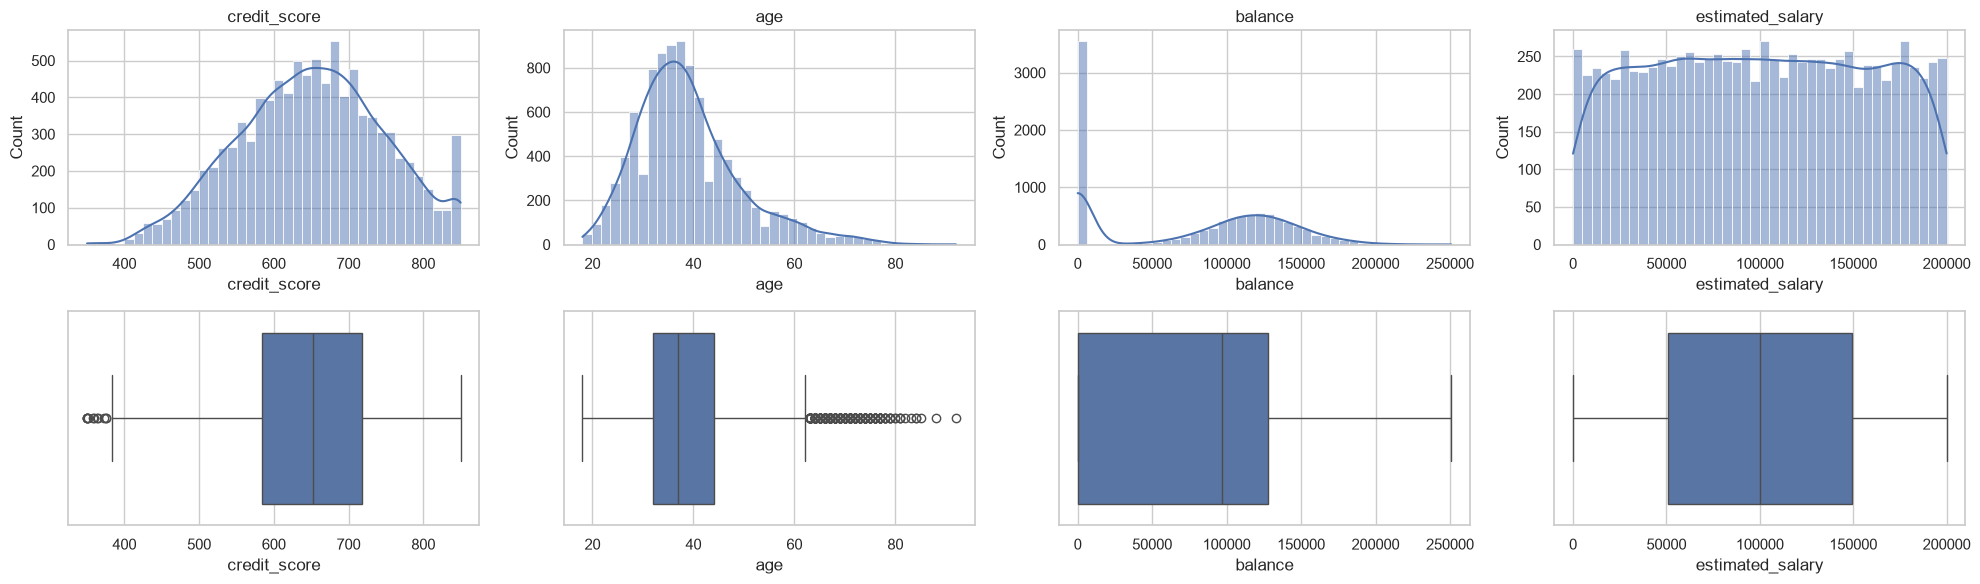

In [10]:
fig, axes = plt.subplots(2, len(continuas), figsize=(5 * len(continuas), 6))
for i, columna in enumerate(continuas):
    sns.histplot(df[columna], bins=40, kde=True, ax=axes[0, i])
    axes[0, i].set_title(columna)
    sns.boxplot(x=df[columna], ax=axes[1, i])
plt.tight_layout()
plt.show()

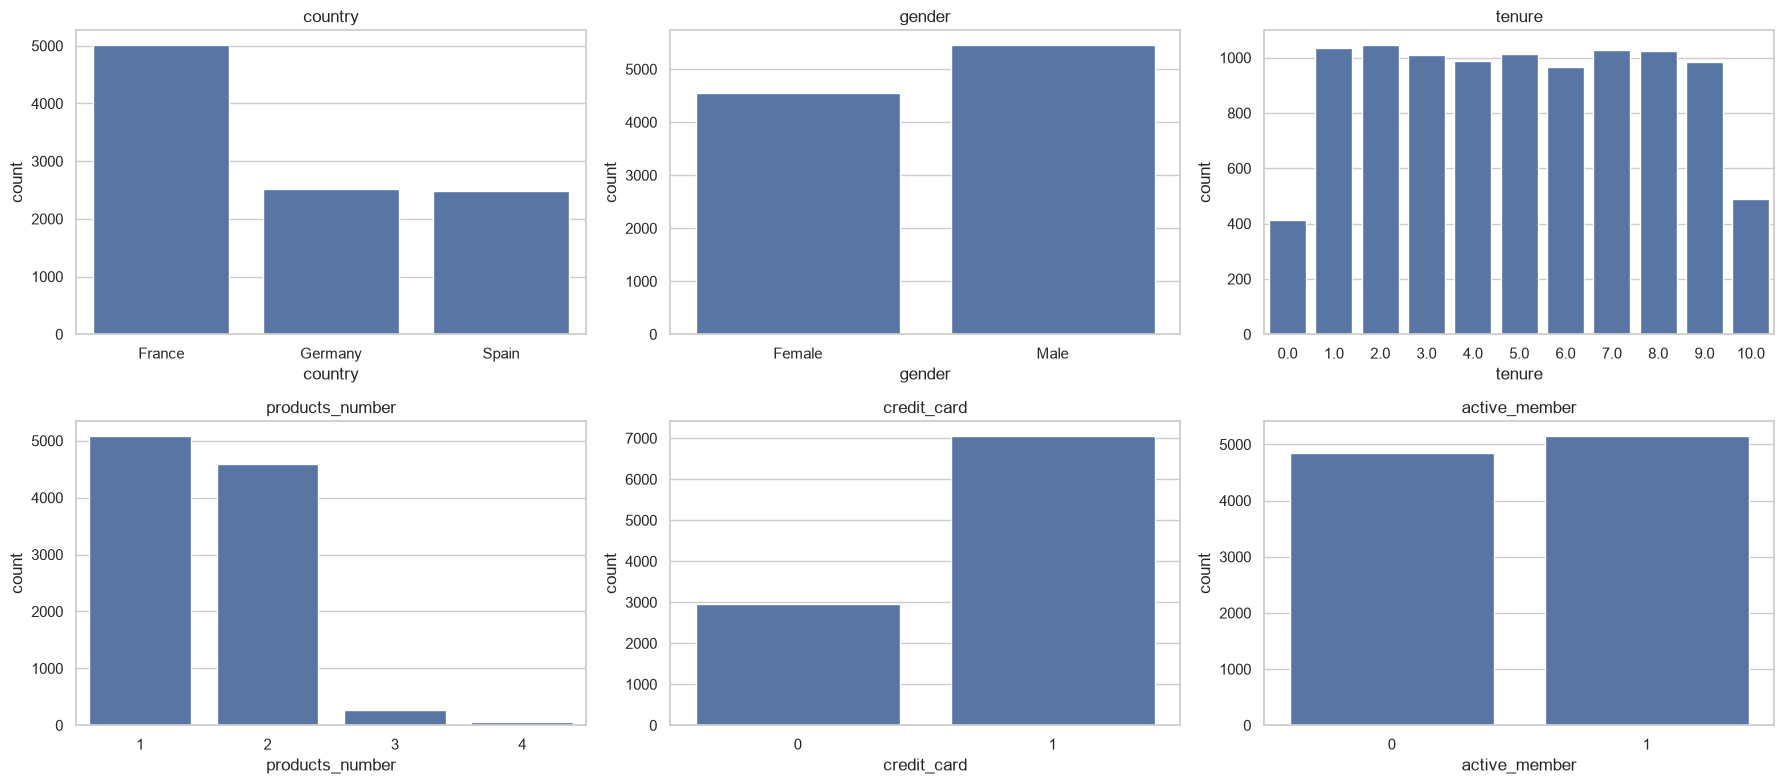

In [11]:
barras = categoricas + discretas + binarias
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, columna in zip(axes.flat, barras):
    sns.countplot(x=columna, data=df, ax=ax, order=sorted(df[columna].dropna().unique()))
    ax.set_title(columna)
plt.tight_layout()
plt.show()

In [12]:
# Indicadores citados en la lectura de distribuciones (datos limpios)
resumen = pd.DataFrame({
    "asimetria": df[continuas].skew(),
    "p25": df[continuas].quantile(0.25),
    "mediana": df[continuas].median(),
    "p75": df[continuas].quantile(0.75),
    "minimo": df[continuas].min(),
    "maximo": df[continuas].max(),
}).round(3)
print(resumen.to_string())
print()
print(f"Saldo 0 sobre todos los clientes: {(df['balance'] == 0).mean() * 100:.1f} %")
print(f"Saldo 0 sobre clientes con saldo informado: {(df['balance'].dropna() == 0).mean() * 100:.1f} %")
print(f"Mediana del saldo entre los que tienen saldo > 0: {df.loc[df['balance'] > 0, 'balance'].median():,.0f}")
print(f"Clientes con credit_score = 850: {(df['credit_score'] == 850).sum()}")
print(f"Valor más frecuente de credit_score: {df['credit_score'].mode()[0]:.0f}")
print(f"Salario mínimo y máximo: {df['estimated_salary'].min():,.0f} y {df['estimated_salary'].max():,.0f}")
tramos = pd.cut(df["estimated_salary"], [0, 50000, 100000, 150000, 200000], include_lowest=True)
print("% de clientes por tramo de salario (0-50k, 50-100k, 100-150k, 150-200k):",
      (tramos.value_counts(normalize=True, sort=False) * 100).round(1).tolist())
porcentajes = pd.concat({c: df[c].value_counts(normalize=True).mul(100).round(1)
                         for c in ["country", "products_number", "credit_card", "active_member"]})
print(porcentajes.to_string())
print(f"Tenure máximo en datos válidos: {int(df['tenure'].max())}")
print("Clientes por tenure:", df["tenure"].value_counts().sort_index().astype(int).to_dict())


                  asimetria        p25    mediana         p75  minimo     maximo
credit_score         -0.068    584.000     652.00     718.000   350.0     850.00
age                   0.996     32.000      37.00      44.000    18.0      92.00
balance              -0.137      0.000   97038.69  127537.155     0.0  250898.09
estimated_salary      0.004  51012.472  100129.33  149370.550     0.0  199992.48

Saldo 0 sobre todos los clientes: 35.6 %
Saldo 0 sobre clientes con saldo informado: 36.3 %
Mediana del saldo entre los que tienen saldo > 0: 119,826
Clientes con credit_score = 850: 227
Valor más frecuente de credit_score: 850
Salario mínimo y máximo: 0 y 199,992
% de clientes por tramo de salario (0-50k, 50-100k, 100-150k, 150-200k): [24.6, 25.4, 25.5, 24.5]
country          France     50.1
                 Germany    25.1
                 Spain      24.8
products_number  1          50.8
                 2          45.9
                 3           2.7
                 4           0.6


In [13]:
# Efecto de la limpieza: datos crudos (solo para comparar) frente a limpios; df no se modifica
crudo = pd.read_csv("churn.csv")
comparacion = pd.DataFrame({
    "crudo": {"registros": len(crudo), "nulos_totales": int(crudo.isna().sum().sum()),
              "asimetria_age": crudo["age"].skew(), "corr_age_churn": crudo["age"].corr(crudo["churn"])},
    "limpio": {"registros": len(df), "nulos_totales": int(df.isna().sum().sum()),
               "asimetria_age": df["age"].skew(), "corr_age_churn": df["age"].corr(df["churn"])},
}).round(3)
print(comparacion.to_string())

                    crudo     limpio
registros       10045.000  10000.000
nulos_totales    1100.000   1113.000
asimetria_age       1.494      0.996
corr_age_churn      0.274      0.283


- **age** tiene sesgo a la derecha (asimetría 0,996): las edades van de 18 a 92 años y el 50 % central de los clientes tiene entre 32 y 44 años.
- **balance** es bimodal: el 35,6 % de los 10.000 clientes tiene saldo 0 (36,3 % si solo se cuentan los que tienen saldo informado). Entre los que tienen saldo, la mediana es 119.826, cerca de 120 mil.
- **credit_score** es casi simétrico (asimetría -0,068), con un pico en 850, el máximo de la escala: 227 clientes lo tienen, y es el valor más frecuente.
- **estimated_salary** es prácticamente uniforme entre 0 y 200 mil: cada tramo de 50 mil reúne entre 24,5 % y 25,5 % de los clientes.
- En las categóricas, Francia tiene el 50,1 % de los clientes y Alemania y España 25,1 % y 24,8 %. Casi todos tienen 1 o 2 productos: 3 y 4 productos son muy raros (2,7 % y 0,6 %). El 70,6 % tiene tarjeta de crédito y el 51,5 % es miembro activo. Por género hay 5.457 hombres y 4.543 mujeres, y la antigüedad (tenure) se reparte de forma pareja: 413 clientes con 0 años, 490 con 10 y entre 967 y 1.046 en cada año de 1 a 9.

### 1.5 Variable objetivo

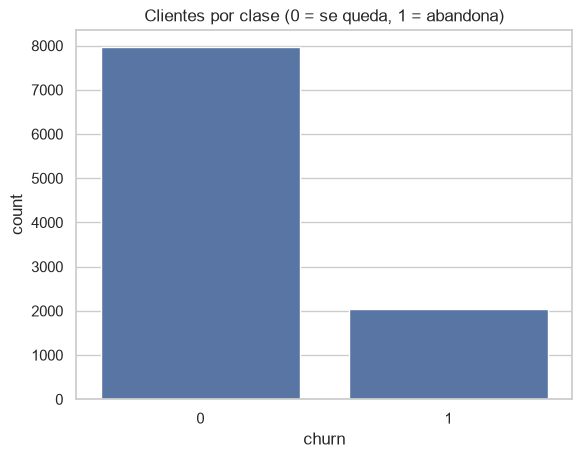

churn
0    7963
1    2037
Name: count, dtype: int64
churn
0    0.7963
1    0.2037
Name: proportion, dtype: float64
Tasa de churn: 20.4 % (referencia del enunciado: 15 %)
Clientes que se quedan por cada uno que se va: 3.9
Exactitud de un modelo que siempre predice 0: 79.6 %


In [14]:
sns.countplot(x=objetivo, data=df)
plt.title("Clientes por clase (0 = se queda, 1 = abandona)")
plt.show()

print(df[objetivo].value_counts())
print(df[objetivo].value_counts(normalize=True).round(4))

referencia = 0.15  # tasa de referencia del enunciado
print(f"Tasa de churn: {df[objetivo].mean() * 100:.1f} % (referencia del enunciado: {referencia * 100:.0f} %)")
print(f"Clientes que se quedan por cada uno que se va: {(df[objetivo] == 0).sum() / (df[objetivo] == 1).sum():.1f}")
print(f"Exactitud de un modelo que siempre predice 0: {(df[objetivo] == 0).mean() * 100:.1f} %")

El **20,4 % de los clientes abandonó** (2.037 de 10.000). Las clases están desbalanceadas: hay 3,9 clientes que se quedan por cada uno que se va. Por eso la exactitud no sirve para evaluar: un modelo que diga siempre "no abandona" acierta el 79,6 % de los casos. Hay que mirar recall, precisión, F1 y AUC, y estratificar al dividir los datos.

La tasa del dataset (20,4 %) está por encima del 15 % de referencia del enunciado. Esto hay que tenerlo en cuenta al proyectar los resultados a la base completa de clientes.

### 1.6 Churn según cada variable

Tasa de abandono por grupo y comparación de las variables continuas entre los que se quedan y los que se van.

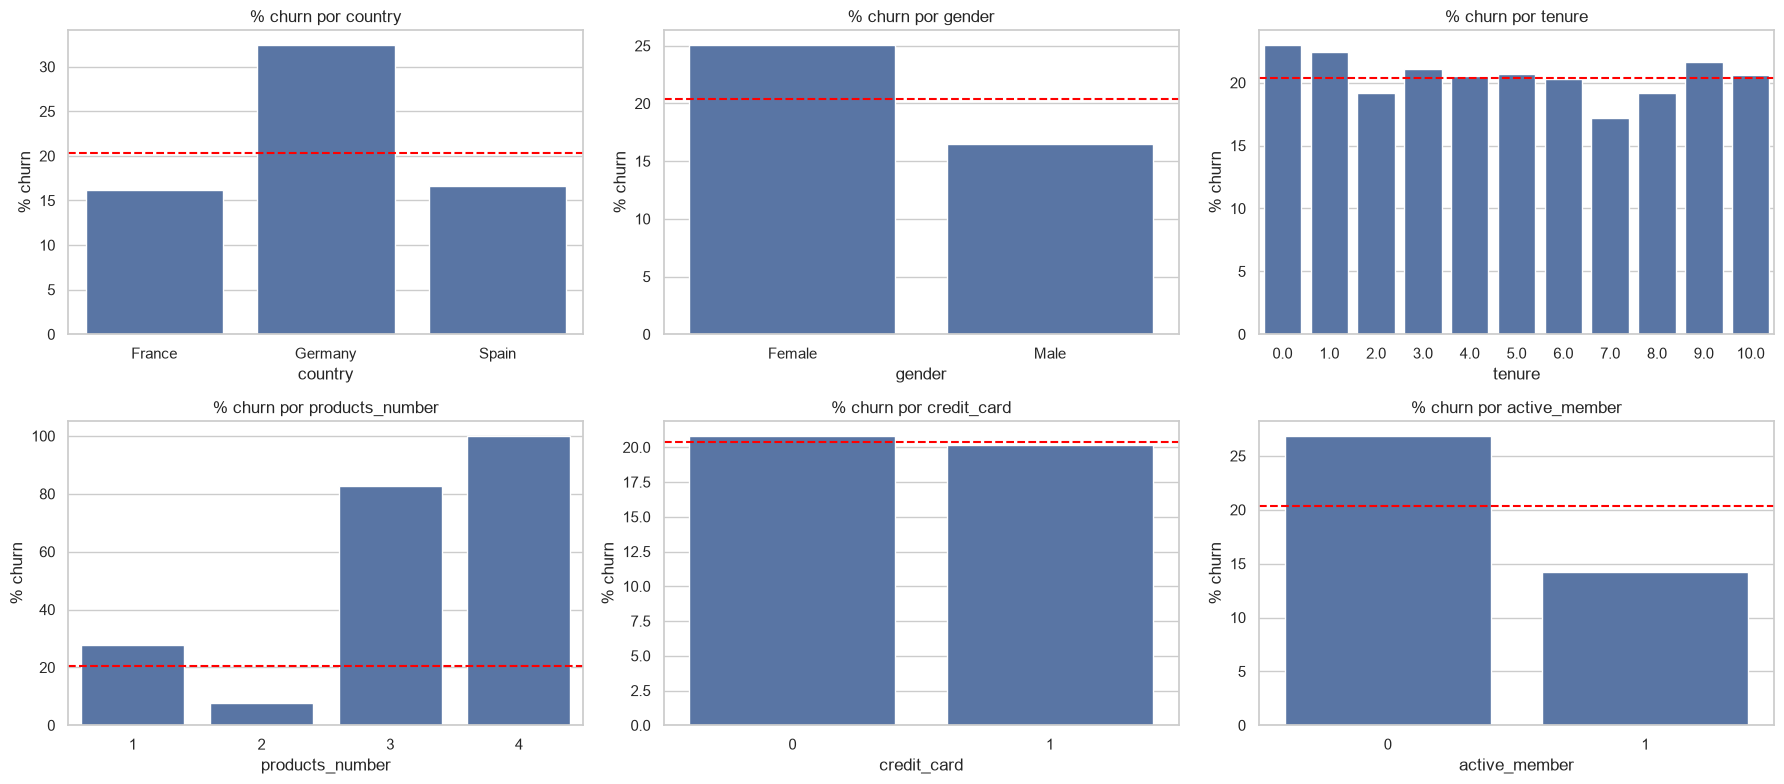

In [15]:
tasa_global = df[objetivo].mean()
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, columna in zip(axes.flat, barras):
    tasa = df.groupby(columna)[objetivo].mean().mul(100)
    sns.barplot(x=tasa.index, y=tasa.values, ax=ax)
    ax.axhline(tasa_global * 100, color="red", linestyle="--")
    ax.set_title(f"% churn por {columna}")
    ax.set_ylabel("% churn")
plt.tight_layout()
plt.show()

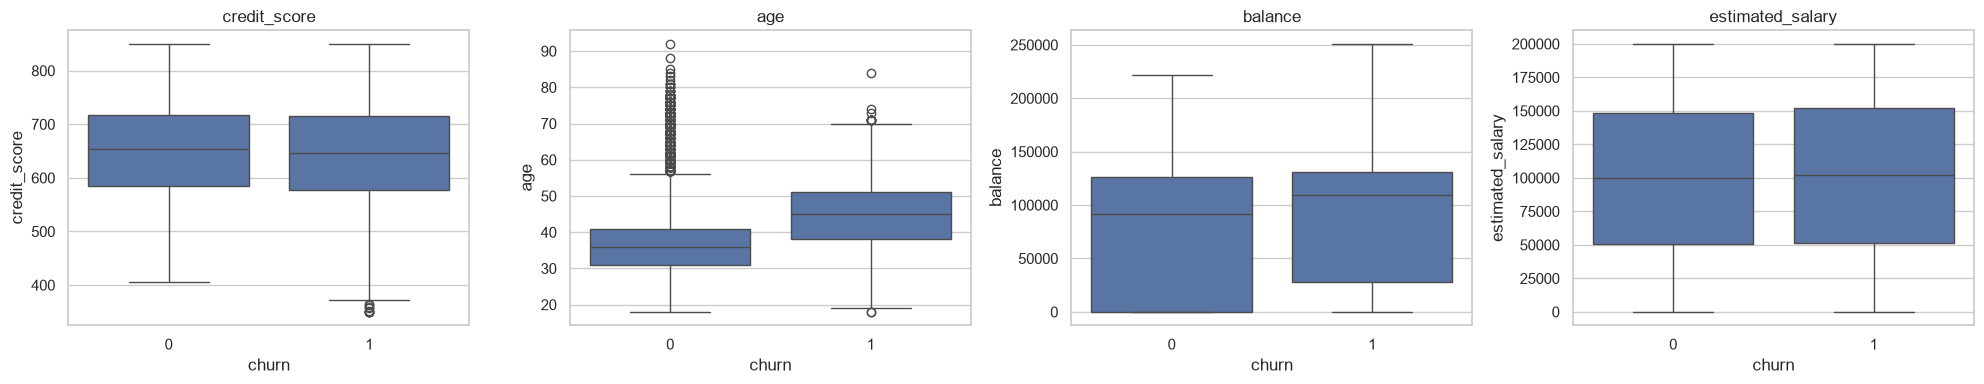

,credit_score,age,balance,estimated_salary
churn,,,,
0,654.0,36.0,91835.2,99645.0
1,646.0,45.0,109154.0,101954.8


In [16]:
fig, axes = plt.subplots(1, len(continuas), figsize=(5 * len(continuas), 4))
for ax, columna in zip(axes, continuas):
    sns.boxplot(x=objetivo, y=columna, data=df, ax=ax)
    ax.set_title(columna)
plt.tight_layout()
plt.show()

df.groupby(objetivo)[continuas].median().round(1)

In [17]:
df["grupo_edad"] = pd.cut(df["age"], bins=[17, 30, 40, 50, 60, 100], labels=["18-30", "31-40", "41-50", "51-60", "60+"])
tasa_edad = df.groupby("grupo_edad", observed=True)[objetivo].agg(churn_pct="mean", n="count")
tasa_edad["churn_pct"] = (tasa_edad["churn_pct"] * 100).round(1)
print(tasa_edad.to_string())
df = df.drop(columns="grupo_edad")

            churn_pct     n
grupo_edad                 
18-30             7.7  1910
31-40            12.3  4304
41-50            33.8  2252
51-60            56.0   782
60+              24.7   446


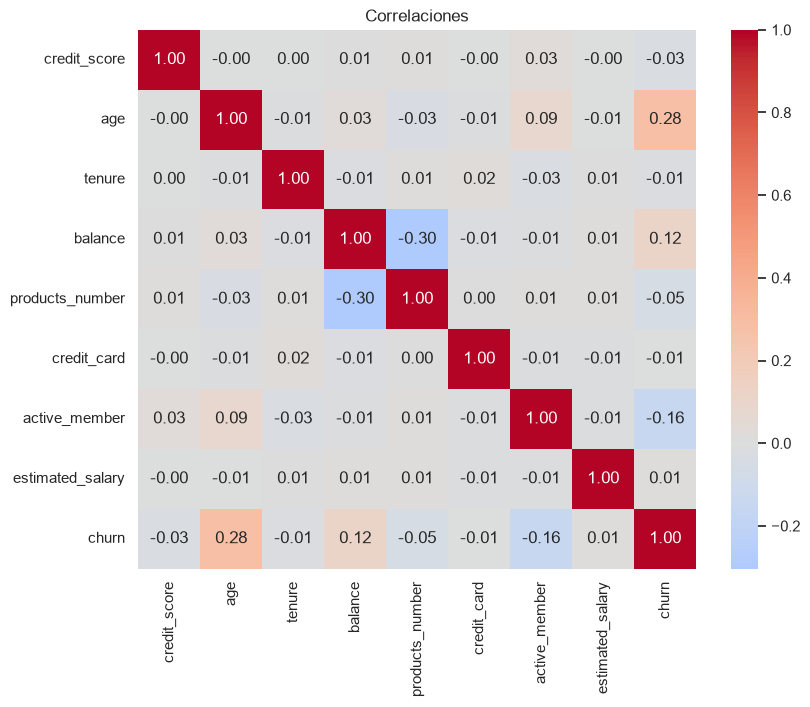

In [18]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlaciones")
plt.show()

In [19]:
# Tasa de churn (%) y n por grupo; saldo 0 frente a saldo > 0 (los nulos de balance quedan como "sin dato")
df_grupos = df.assign(saldo=np.select([df["balance"] > 0, df["balance"] == 0],
                                      ["saldo > 0", "saldo 0"], default="sin dato"))
filas = []
for variable in ["country", "gender", "products_number", "active_member", "credit_card", "tenure", "saldo"]:
    for grupo, churn_grupo in df_grupos.groupby(variable)[objetivo]:
        filas.append({"variable": variable, "grupo": grupo,
                      "churn_%": round(churn_grupo.mean() * 100, 1), "n": len(churn_grupo)})
print(pd.DataFrame(filas).to_string(index=False))
print()

# Correlación de cada variable numérica con churn
correlacion = df.select_dtypes("number").corr(numeric_only=True)[objetivo].drop(objetivo)
print(correlacion.reindex(correlacion.abs().sort_values(ascending=False).index).round(3).to_string())

       variable     grupo  churn_%    n
        country    France     16.2 5014
        country   Germany     32.4 2509
        country     Spain     16.7 2477
         gender    Female     25.1 4543
         gender      Male     16.5 5457
products_number         1     27.7 5084
products_number         2      7.6 4590
products_number         3     82.7  266
products_number         4    100.0   60
  active_member         0     26.9 4849
  active_member         1     14.3 5151
    credit_card         0     20.8 2945
    credit_card         1     20.2 7055
         tenure       0.0     23.0  413
         tenure       1.0     22.4 1034
         tenure       2.0     19.2 1046
         tenure       3.0     21.1 1009
         tenure       4.0     20.5  989
         tenure       5.0     20.7 1012
         tenure       6.0     20.3  967
         tenure       7.0     17.2 1028
         tenure       8.0     19.2 1025
         tenure       9.0     21.6  984
         tenure      10.0     20.6  490


In [20]:
# Porcentaje de saldo 0 por país (sobre clientes con saldo informado)
saldo_pais = df.dropna(subset=["balance"]).groupby("country")["balance"].agg(
    n="count", saldo_0_pct=lambda s: round((s == 0).mean() * 100, 1))
print(saldo_pais.to_string())

            n  saldo_0_pct
country                   
France   4911         48.4
Germany  2456          0.0
Spain    2433         48.7


In [21]:
# Saldo 0 frente a saldo > 0 dentro de cada país (se excluyen los 200 clientes sin dato de saldo)
con_saldo = df.dropna(subset=["balance"]).assign(saldo=lambda d: np.where(d["balance"] > 0, "saldo > 0", "saldo 0"))
tabla_sp = con_saldo.groupby(["country", "saldo"])[objetivo].agg(n="size", churn_pct=lambda s: round(s.mean() * 100, 1)).unstack("saldo")
print(tabla_sp.to_string())
print()
print(f"Alemania, clientes con saldo 0: {int(((con_saldo['country'] == 'Germany') & (con_saldo['saldo'] == 'saldo 0')).sum())}")
for pais in ["France", "Spain"]:
    t0, t1 = tabla_sp.loc[pais, ("churn_pct", "saldo 0")], tabla_sp.loc[pais, ("churn_pct", "saldo > 0")]
    print(f"{pais}: saldo 0 {t0:.1f} %, saldo > 0 {t1:.1f} %, brecha {t1 - t0:+.1f} puntos")
g0, g1 = [con_saldo.loc[con_saldo["saldo"] == s, objetivo].mean() * 100 for s in ("saldo 0", "saldo > 0")]
print(f"Brecha global (todos los países): saldo 0 {g0:.1f} %, saldo > 0 {g1:.1f} %, {g1 - g0:+.1f} puntos")
sin_alemania = con_saldo[con_saldo["country"] != "Germany"]
h0, h1 = [sin_alemania.loc[sin_alemania["saldo"] == s, objetivo].mean() * 100 for s in ("saldo 0", "saldo > 0")]
print(f"Brecha sin Alemania (Francia y España juntas): saldo 0 {h0:.1f} %, saldo > 0 {h1:.1f} %, {h1 - h0:+.1f} puntos")

              n           churn_pct          
saldo   saldo 0 saldo > 0   saldo 0 saldo > 0
country                                      
France   2375.0    2536.0      14.0      18.3
Germany     NaN    2456.0       NaN      32.5
Spain    1184.0    1249.0      13.8      19.5

Alemania, clientes con saldo 0: 0
France: saldo 0 14.0 %, saldo > 0 18.3 %, brecha +4.3 puntos
Spain: saldo 0 13.8 %, saldo > 0 19.5 %, brecha +5.7 puntos
Brecha global (todos los países): saldo 0 13.9 %, saldo > 0 24.1 %, +10.2 puntos
Brecha sin Alemania (Francia y España juntas): saldo 0 13.9 %, saldo > 0 18.7 %, +4.8 puntos


Las variables que más se asocian con el abandono son:

- **Edad:** es la de mayor correlación lineal con churn (0,283, en el mapa de calor y en la tabla de correlaciones). La tasa sube de 7,7 % en el grupo de 18 a 30 años a 33,8 % entre 41 y 50 y a 56,0 % entre 51 y 60; en el grupo de 60+ baja a 24,7 %. La mediana de edad de los que abandonan es 45 años, contra 36 de los que se quedan.
- **Número de productos:** la tasa es de 27,7 % con 1 producto y de 7,6 % con 2. Con 3 productos es de 82,7 % (n = 266) y con 4 de 100,0 % (n = 60); son grupos pequeños.
- **País:** Alemania presenta mayor tasa, 32,4 %, frente a 16,2 % en Francia y 16,7 % en España. Ver saldo.
- **Miembro activo:** los inactivos presentan 26,9 % de churn, contra 14,3 % de los activos.
- **Género:** las mujeres presentan 25,1 % de churn, contra 16,5 % de los hombres.
- **Saldo:** 24,1 % de churn con saldo > 0 contra 13,9 % con saldo 0 (+10,2 puntos). Parte de esa brecha es efecto de Alemania, donde ningún cliente tiene saldo 0 (en Francia y España lo tiene cerca de la mitad: 48,4 % y 48,7 %). Dentro de cada país baja a +4,3 puntos en Francia (18,3 % contra 14,0 %) y a +5,7 en España (19,5 % contra 13,8 %). País y saldo deben leerse juntos.

Las variables con **poca asociación lineal o por grupos** son credit_score, estimated_salary, tenure y credit_card. Su correlación con churn no supera 0,028 en valor absoluto (credit_score: -0,028). La tasa por antigüedad va de 17,2 % a 23,0 % sin tendencia clara, y la de tarjeta de crédito es 20,8 % sin tarjeta y 20,2 % con tarjeta. En los diagramas de caja, las medianas de los que se van frente a los que se quedan son casi iguales en credit_score (646 contra 654) y en estimated_salary (101.955 contra 99.645), y algo mayor en balance (109.154 contra 91.835).

In [22]:
# Tamaño del efecto con IC 95 % bootstrap (1.000 remuestreos, semilla 42) y p-valor ajustado por Holm; nulos omitidos por variable
from scipy.stats import chi2_contingency, mannwhitneyu
from statsmodels.stats.multitest import multipletests

rng_e = np.random.default_rng(42)

def cramer_v(x, y):
    tabla = pd.crosstab(x, y).reindex(columns=[0, 1], fill_value=0)
    tabla = tabla.loc[tabla.sum(axis=1) > 0]
    chi2, p, _, _ = chi2_contingency(tabla, correction=False)
    return np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1))), chi2, p

filas_e = []
for columna in ["country", "gender", "products_number", "credit_card", "active_member"]:
    d = df[[columna, objetivo]].dropna()
    x, y_ = d[columna].to_numpy(), d[objetivo].to_numpy()
    v, chi2, p = cramer_v(x, y_)
    boot = [cramer_v(x[i], y_[i])[0] for i in (rng_e.integers(0, len(d), len(d)) for _ in range(1000))]
    filas_e.append({"variable": columna, "medida": "V de Cramér", "n": len(d), "efecto": v,
                    "IC95_inf": np.percentile(boot, 2.5), "IC95_sup": np.percentile(boot, 97.5), "p": p})
for columna in ["credit_score", "age", "tenure", "balance", "estimated_salary"]:
    d = df[[columna, objetivo]].dropna()
    x, y_ = d[columna].to_numpy(), d[objetivo].to_numpy()
    auc = roc_auc_score(y_, x)
    p = mannwhitneyu(x[y_ == 1], x[y_ == 0], alternative="two-sided").pvalue
    boot = [roc_auc_score(y_[i], x[i]) for i in (rng_e.integers(0, len(d), len(d)) for _ in range(1000))]
    filas_e.append({"variable": columna, "medida": "AUC univariado", "n": len(d), "efecto": auc,
                    "IC95_inf": np.percentile(boot, 2.5), "IC95_sup": np.percentile(boot, 97.5), "p": p})
pruebas = pd.DataFrame(filas_e).set_index("variable")
pruebas["p_Holm"] = multipletests(pruebas["p"], method="holm")[1]
pruebas["prueba"] = np.where(pruebas["medida"] == "V de Cramér", "chi²", "Mann-Whitney")
pruebas["p Holm"] = [f"{p:.3f}" if p >= 0.001 else "<0.001" for p in pruebas["p_Holm"]]
pruebas["|AUC-0,5|"] = np.where(pruebas["medida"] == "AUC univariado", (pruebas["efecto"] - 0.5).abs(), np.nan)
print("AUC univariado = probabilidad de que un cliente que abandona tenga un valor mayor que uno que se queda (0,5 = sin asociación; >0,5: más churn con valores altos).")
print(pruebas[["medida", "prueba", "n", "efecto", "IC95_inf", "IC95_sup", "p Holm", "|AUC-0,5|"]].round(3).to_string())
print(f"\nAncho medio del IC 95 %: V de Cramér {(pruebas.loc[pruebas.medida == 'V de Cramér', 'IC95_sup'] - pruebas.loc[pruebas.medida == 'V de Cramér', 'IC95_inf']).mean():.3f}; "
      f"AUC {(pruebas.loc[pruebas.medida == 'AUC univariado', 'IC95_sup'] - pruebas.loc[pruebas.medida == 'AUC univariado', 'IC95_inf']).mean():.3f}")

AUC univariado = probabilidad de que un cliente que abandona tenga un valor mayor que uno que se queda (0,5 = sin asociación; >0,5: más churn con valores altos).
                          medida        prueba      n  efecto  IC95_inf  IC95_sup  p Holm  |AUC-0,5|
variable                                                                                            
country              V de Cramér          chi²  10000   0.174     0.154     0.194  <0.001        NaN
gender               V de Cramér          chi²  10000   0.107     0.087     0.128  <0.001        NaN
products_number      V de Cramér          chi²  10000   0.388     0.369     0.406  <0.001        NaN
credit_card          V de Cramér          chi²  10000   0.007     0.000     0.028   0.593        NaN
active_member        V de Cramér          chi²  10000   0.156     0.137     0.175  <0.001        NaN
credit_score      AUC univariado  Mann-Whitney   9746   0.482     0.468     0.496   0.063      0.018
age               AUC univaria

**Qué muestran las pruebas.** El AUC univariado es la probabilidad de que un cliente que abandona tenga un valor mayor que uno que se queda (0,5 = sin asociación). Asociación clara: `products_number` (V de Cramér 0,388; IC 0,369 a 0,406) y `age` (AUC 0,729; 0,717 a 0,742). Moderada: `country` (V 0,174), `active_member` (0,156), `gender` (0,107) y `balance` (AUC 0,577, en parte por Alemania). En el límite: `credit_score` (AUC 0,482; 0,468 a 0,496; p de Holm 0,063; el IC no está ajustado por comparaciones múltiples, por eso excluye 0,5 aunque el p ajustado supera 0,05). Casi nula: `tenure` (AUC 0,490), `estimated_salary` (0,508) y `credit_card` (V 0,007), con intervalos que incluyen o rozan la ausencia de asociación.

### Conclusiones de la sección 1

Después de la limpieza quedan **10.000 clientes**. No hay duplicados, las categorías están unificadas y los valores imposibles de edad, puntaje y antigüedad se convirtieron en nulos (los salarios negativos se llevaron a 0). Quedan nulos en credit_score, age, tenure, balance y estimated_salary, que se imputan en la sección 2 con la mediana del conjunto de entrenamiento.

Los perfiles con mayor tasa de churn son los de 41 a 60 años, los de Alemania, los inactivos y, en menor medida, los que tienen saldo: la brecha global por saldo (24,1 % con saldo > 0 contra 13,9 % con saldo 0, +10,2 puntos) baja a +4,3 puntos en Francia (18,3 % contra 14,0 %) y a +5,7 en España (19,5 % contra 13,8 %), porque parte de ella es el efecto de Alemania, donde ningún cliente tiene saldo 0 (tabla de saldo por país en 1.6). Las relaciones no son lineales: la tasa sube hasta 56,0 % entre 51 y 60 años y luego baja a 24,7 % en 60+; con productos, baja a 7,6 % con 2 y sube a 82,7 % con 3. Por eso conviene probar modelos de árboles, además de uno lineal como referencia (y, en 2.2, una logística con esas no linealidades).

**Ojo con 3 y 4 productos.** products_number = 4 tiene 100,0 % de churn, pero solo n = 60 clientes; products_number = 3 tiene 82,7 % con n = 266. Se mantienen porque son datos observados, pero su efecto se interpreta con cautela.

**¿Cuándo se midieron las variables?** El dataset es una foto tomada cuando ya se sabe si el cliente abandonó. `active_member` indica si el cliente ha hecho transacciones recientemente, así que puede reflejar en parte el propio abandono: su asociación con churn (26,9 % en inactivos contra 14,3 % en activos) se lee como señal de riesgo concurrente, no como anticipación. `products_number` = 4 muestra 100,0 % de churn en solo 60 clientes, un patrón que vale la pena notar; la causa no se conoce con estos datos. Se mantienen ambas variables y todas las demás; no hay identificadores. Las implicaciones para producción están en 5.5.

## 2. Modelos

Se prueban tres modelos:
- **Regresión logística**, como línea base.
- **Random Forest**.
- **Gradient Boosting**.

En la sección 1 vimos que la edad y el número de productos no tienen una relación lineal con el churn, así que se espera que los modelos de árboles funcionen mejor que la logística lineal. En 2.2 se mide cuánto de esa ventaja viene de esas dos no linealidades con una logística no lineal adicional (age² y dummies de productos); esa variante no entra en las tablas de la sección 3 ni en 4.1, donde la logística lineal sigue siendo la línea base interpretable.

### 2.1 Preparación y división de los datos

Se usan todas las variables. country y gender se pasan a dummies. Los datos se dividen en 60 % entrenamiento, 20 % validación y 20 % prueba, de forma estratificada y con `random_state=42`. Los nulos se imputan con la mediana del entrenamiento y después se escala. El conjunto de prueba no se usa en esta sección.

**¿Por qué no quitamos variables?** El dataset es una foto tomada cuando ya se sabe si el cliente abandonó, y no documenta cuándo se midió cada variable. `active_member` (transacciones recientes) puede reflejar en parte el propio abandono, así que su asociación con churn se lee como señal de riesgo concurrente, no como anticipación. `products_number` = 4 muestra 100 % de churn en solo 60 clientes (con 3 productos es 82,7 %, en 266), un patrón que vale la pena notar; su causa no se conoce con estos datos. Por decisión del equipo se mantienen ambas variables y todas las demás; no hay identificadores. Las variables con menor asociación individual (AUC univariado en entrenamiento, tomado como el mayor entre AUC y 1 − AUC, entre 0,505 y 0,518 en credit_card, estimated_salary, tenure y credit_score) también se mantienen: solas casi no separan, pero un árbol puede usarlas en interacciones. El punto 4 revisa su aporte con importancia por impureza (4.2) y valores de Shapley (4.4).

El escalado solo lo necesita la regresión logística; no afecta a los árboles, que no cambian con transformaciones monótonas de cada columna. Las medianas y el escalador se calculan con todo el entrenamiento antes de la validación cruzada, así que los folds de validación comparten esos estadísticos (fuga mínima, aceptada por simplicidad). Los nulos imputados en el entrenamiento (6.000 clientes) son 186 en age, 196 en estimated_salary, 146 en credit_score, 120 en balance y 2 en tenure.

In [23]:
datos = pd.get_dummies(df, columns=categoricas, drop_first=True, dtype=int)
columnas = datos.columns.drop(objetivo).tolist()
X = datos[columnas]
y = datos[objetivo]

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp)

medianas = X_train.median()
X_train, X_val, X_test = X_train.fillna(medianas), X_val.fillna(medianas), X_test.fillna(medianas)

escalador = StandardScaler()
X_train_esc = pd.DataFrame(escalador.fit_transform(X_train), columns=columnas, index=X_train.index)
X_val_esc = pd.DataFrame(escalador.transform(X_val), columns=columnas, index=X_val.index)
X_test_esc = pd.DataFrame(escalador.transform(X_test), columns=columnas, index=X_test.index)

print("Columnas:", columnas)
pd.DataFrame({
    "registros": [len(s) for s in (y_train, y_val, y_test)],
    "proporcion_churn": [round(float(s.mean()), 4) for s in (y_train, y_val, y_test)],
}, index=["Entrenamiento", "Validación", "Prueba"])

Columnas: ['credit_score', 'age', 'tenure', 'balance', 'products_number', 'credit_card', 'active_member', 'estimated_salary', 'country_Germany', 'country_Spain', 'gender_Male']


,registros,proporcion_churn
Entrenamiento,6000,0.2038
Validación,2000,0.2035
Prueba,2000,0.2035


In [24]:
# Evidencia para mantener todas las variables: asociación individual con el churn (en entrenamiento) y nulos imputados
asociacion = pd.DataFrame({
    "AUC univariado": [max(roc_auc_score(y_train, X_train[c]), 1 - roc_auc_score(y_train, X_train[c])) for c in columnas],
    "nulos imputados": [int(df.loc[X_train.index, c].isna().sum()) if c in df.columns else 0 for c in columnas],
}, index=columnas).sort_values("AUC univariado", ascending=False)
print(asociacion.round(3))

por_productos = df.groupby("products_number")[objetivo].agg(clientes="size", churn="mean")
print(por_productos.round(3))

                  AUC univariado  nulos imputados
age                        0.728              186
active_member              0.599                0
country_Germany            0.588                0
products_number            0.578                0
balance                    0.573              120
gender_Male                0.565                0
country_Spain              0.524                0
credit_score               0.518              146
tenure                     0.510                2
estimated_salary           0.506              196
credit_card                0.505                0
                 clientes  churn
products_number                 
1                    5084  0.277
2                    4590  0.076
3                     266  0.827
4                      60  1.000


### 2.2 Búsqueda de hiperparámetros

Se usa `GridSearchCV` con validación cruzada estratificada de 5 folds sobre el entrenamiento, con los mismos folds para todos los modelos. Cada modelo se reajusta con la combinación de mayor **AUC** (`refit="roc_auc"`), y se reporta también el **AP** (precisión promedio) como métrica de apoyo, siempre como media ± desviación estándar entre folds.

Se usa AUC y no F1 porque la campaña contacta a los clientes en orden de riesgo y el umbral (a cuántos contactar) se fija después, según costo y beneficio, en la subsección 3.7. Lo que importa es que el modelo ordene bien. El AP pesa más el tope del ranking, que es donde se gasta el presupuesto.

In [25]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
tiempos = {}
resumen_cv = {}

def buscar(nombre, modelo, rejilla):
    inicio = time.time()
    busqueda = GridSearchCV(modelo, rejilla, cv=skf, scoring={"roc_auc": "roc_auc", "ap": "average_precision"},
                            refit="roc_auc", n_jobs=-1)
    busqueda.fit(X_train_esc, y_train)
    tiempos[nombre] = time.time() - inicio
    r, i = busqueda.cv_results_, busqueda.best_index_
    resumen_cv[nombre] = {"AUC CV": r["mean_test_roc_auc"][i], "AUC CV std": r["std_test_roc_auc"][i],
                          "AP CV": r["mean_test_ap"][i], "AP CV std": r["std_test_ap"][i]}
    print("Mejor combinación:", busqueda.best_params_)
    print(f"AUC de validación cruzada: {r['mean_test_roc_auc'][i]:.3f} ± {r['std_test_roc_auc'][i]:.3f} (desviación entre folds)")
    print(f"AP de validación cruzada: {r['mean_test_ap'][i]:.3f} ± {r['std_test_ap'][i]:.3f}")
    print(f"tiempo: {tiempos[nombre]:.0f} s")
    return busqueda


In [26]:
busqueda_logistica = buscar("Regresión logística", LogisticRegression(max_iter=1000),
                            {"C": [0.01, 0.1, 1, 10], "class_weight": [None, "balanced"]})

Mejor combinación: {'C': 0.1, 'class_weight': 'balanced'}
AUC de validación cruzada: 0.761 ± 0.027 (desviación entre folds)
AP de validación cruzada: 0.457 ± 0.029
tiempo: 5 s


In [27]:
busqueda_rf = buscar("Random Forest", RandomForestClassifier(random_state=42),
                     {"n_estimators": [200, 400], "max_depth": [5, 10, None], "min_samples_leaf": [1, 5, 20],
                      "class_weight": [None, "balanced"]})
pd.DataFrame(busqueda_rf.cv_results_).sort_values("mean_test_roc_auc", ascending=False)[
    ["param_n_estimators", "param_max_depth", "param_min_samples_leaf", "param_class_weight", "mean_test_roc_auc"]
].head(5).round(3)

Mejor combinación: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 200}
AUC de validación cruzada: 0.865 ± 0.010 (desviación entre folds)
AP de validación cruzada: 0.685 ± 0.027
tiempo: 7 s


,param_n_estimators,param_max_depth,param_min_samples_leaf,param_class_weight,mean_test_roc_auc
24,200,10,1,balanced,0.865
25,400,10,1,balanced,0.865
7,400,10,1,NaN,0.864
26,200,10,5,balanced,0.864
27,400,10,5,balanced,0.864


In [28]:
busqueda_gb = buscar("Gradient Boosting", GradientBoostingClassifier(random_state=42),
                     {"n_estimators": [100, 200, 300], "learning_rate": [0.02, 0.05, 0.1], "max_depth": [2, 3, 4]})
pd.DataFrame(busqueda_gb.cv_results_).pivot_table(index=["param_max_depth", "param_n_estimators"],
                                                  columns="param_learning_rate", values="mean_test_roc_auc").round(3)

Mejor combinación: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200}
AUC de validación cruzada: 0.868 ± 0.007 (desviación entre folds)
AP de validación cruzada: 0.707 ± 0.017
tiempo: 6 s


param_learning_rate                  0.02   0.05   0.10
param_max_depth param_n_estimators                     
2               100                 0.838  0.856  0.861
                200                 0.852  0.862  0.862
                300                 0.859  0.863  0.862
3               100                 0.849  0.865  0.867
                200                 0.862  0.868  0.864
                300                 0.866  0.866  0.861
4               100                 0.857  0.865  0.865
                200                 0.864  0.866  0.860
                300                 0.865  0.864  0.856

Mejores combinaciones (AUC de validación cruzada, media ± desviación entre folds; entre paréntesis el AP de validación cruzada):

- **Regresión logística:** C = 0,1 con `class_weight="balanced"` (0,761 ± 0,027; AP 0,457).
- **Random Forest:** 200 árboles, `max_depth=10`, `min_samples_leaf=1` y `class_weight="balanced"` (0,865 ± 0,010; AP 0,685). Las primeras cinco combinaciones quedan entre 0,864 y 0,865 y todas tienen `max_depth=10`, así que entre las mejores combinaciones las diferencias son de 0,001, mucho menores que la desviación entre folds.
- **Gradient Boosting:** 200 árboles, `learning_rate=0,05` y `max_depth=3` (0,868 ± 0,007; AP 0,707). La rejilla cubre de 100 a 300 árboles, tasa de 0,02 a 0,1 y profundidad de 2 a 4, y el óptimo queda en el interior, no en un borde. Sus vecinos inmediatos no mejoran: 0,867 con 100 árboles y tasa 0,1, 0,866 con 300 árboles y tasa 0,05, y 0,862 con 200 árboles y tasa 0,02. No se probó `subsample`, para mantener corta la búsqueda.

Los dos modelos de árboles le sacan unos 10 puntos de AUC a la regresión logística (0,865 y 0,868 contra 0,761 de la logística lineal), como se esperaba. Más abajo se mide cuánto de esa diferencia desaparece al darle a la logística las no linealidades de edad y productos.

In [29]:
# ¿Cambia algo si el Gradient Boosting se entrena con pesos balanceados? Mismos hiperparámetros, mismos folds
from sklearn.model_selection import cross_validate
from sklearn.utils.class_weight import compute_sample_weight

pesos = compute_sample_weight("balanced", y_train)
mejor_gb = GradientBoostingClassifier(random_state=42, **busqueda_gb.best_params_)
filas_w = {}
for etiqueta, parametros in [("sin pesos", None), ("con pesos balanceados", {"sample_weight": pesos})]:
    cv = cross_validate(mejor_gb, X_train_esc, y_train, cv=skf, scoring={"roc_auc": "roc_auc", "ap": "average_precision"},
                        params=parametros)
    modelo_w = GradientBoostingClassifier(random_state=42, **busqueda_gb.best_params_)
    modelo_w.fit(X_train_esc, y_train, sample_weight=None if parametros is None else pesos)
    prob = modelo_w.predict_proba(X_val_esc)[:, 1]
    pred = (prob >= 0.5).astype(int)
    filas_w[etiqueta] = {"AUC CV": cv["test_roc_auc"].mean(), "AUC CV std": cv["test_roc_auc"].std(),
                         "AP CV": cv["test_ap"].mean(), "AP CV std": cv["test_ap"].std(),
                         "AUC val": roc_auc_score(y_val, prob), "AP val": average_precision_score(y_val, prob),
                         "prob. media val": prob.mean(), "precisión val (0,5)": precision_score(y_val, pred),
                         "recall val (0,5)": recall_score(y_val, pred)}
print("Proporción real de churn en validación:", round(float(y_val.mean()), 4))
comparacion_pesos = pd.DataFrame(filas_w).T
comparacion_pesos.round(3)

Proporción real de churn en validación: 0.2035


,AUC CV,AUC CV std,AP CV,AP CV std,AUC val,AP val,prob. media val,"precisión val (0,5)","recall val (0,5)"
sin pesos,0.868,0.007,0.707,0.017,0.848,0.677,0.196,0.770,0.459
con pesos balanceados,0.865,0.008,0.702,0.019,0.845,0.667,0.364,0.494,0.715


**¿Y con pesos balanceados?** Con los mismos hiperparámetros y folds, entrenar con `sample_weight` balanceado da un AUC de CV de 0,865 ± 0,008 contra 0,868 ± 0,007 sin pesos, y un AP de CV de 0,702 contra 0,707. La diferencia es menor que la desviación entre folds: los pesos casi no cambian el ordenamiento (el AUC de validación pasa de 0,848 a 0,845). Lo que cambia es la probabilidad. La media de las probabilidades en validación pasa de 0,196 (la proporción real de churn es 0,2035) a 0,364, y con umbral 0,5 el recall sube de 0,459 a 0,715 mientras la precisión baja de 0,770 a 0,494. Es decir, sin pesos el modelo es más conservador a umbral 0,5 pero su probabilidad media se acerca a la tasa real; los pesos se asocian sobre todo con un cambio del punto de corte efectivo. Como el umbral se decide en la subsección 3.7 según la ganancia, se deja el Gradient Boosting sin pesos.

In [30]:
# Logística con edad al cuadrado y número de productos como categorías
X_train_nl = pd.get_dummies(X_train.assign(age2=X_train["age"] ** 2), columns=["products_number"], drop_first=True, dtype=int)
X_val_nl = pd.get_dummies(X_val.assign(age2=X_val["age"] ** 2), columns=["products_number"], drop_first=True, dtype=int)

escalador_nl = StandardScaler().fit(X_train_nl)
busqueda_nl = GridSearchCV(LogisticRegression(max_iter=1000),
                           {"C": [0.01, 0.1, 1, 10], "class_weight": [None, "balanced"]},
                           cv=skf, scoring="roc_auc", n_jobs=-1)
busqueda_nl.fit(escalador_nl.transform(X_train_nl), y_train)

print("Mejores parámetros:", busqueda_nl.best_params_)
pd.DataFrame(busqueda_nl.cv_results_)[["param_C", "param_class_weight", "mean_test_score", "std_test_score"]] \
    .sort_values("mean_test_score", ascending=False).head(3)

Mejores parámetros: {'C': 10, 'class_weight': None}


,param_C,param_class_weight,mean_test_score,std_test_score
6,10.0,NaN,0.843826,0.008633
4,1.0,NaN,0.843548,0.008861
7,10.0,balanced,0.843392,0.008737


In [31]:
prob_nl = busqueda_nl.predict_proba(escalador_nl.transform(X_val_nl))[:, 1]
print("AUC validación, logística no lineal:", round(roc_auc_score(y_val, prob_nl), 3))
print("AUC validación, logística normal:   ", round(roc_auc_score(y_val, busqueda_logistica.best_estimator_.predict_proba(X_val_esc)[:, 1]), 3))
print("AUC validación, Gradient Boosting:  ", round(roc_auc_score(y_val, busqueda_gb.best_estimator_.predict_proba(X_val_esc)[:, 1]), 3))

AUC validación, logística no lineal: 0.828
AUC validación, logística normal:    0.762
AUC validación, Gradient Boosting:   0.848


**Logística con edad al cuadrado.** Es una prueba aparte: no entra en `modelos` y la línea base sigue siendo la logística normal. Al agregar edad al cuadrado y el número de productos como categorías, el AUC de validación cruzada sube de 0,76 a 0,84 (mejor combinación: C = 10 sin pesos). Es decir, casi toda la ventaja de los árboles viene de captar esas dos formas: el pico de churn en edades medias y el salto con 3 y 4 productos.

### 2.3 Selección del modelo

Se comparan los tres modelos con el AUC de CV (± desviación entre folds) y con entrenamiento y validación. Precisión, recall y F1 de validación usan el umbral 0,5. El conjunto de prueba se deja para la sección 3.

Criterio: se parte del mayor AUC de CV; los modelos a menos de una desviación del mayor se consideran un empate técnico, y entre ellos se elige el de menor brecha entre entrenamiento y validación.

In [32]:
modelos = {
    "Regresión logística": busqueda_logistica.best_estimator_,
    "Random Forest": busqueda_rf.best_estimator_,
    "Gradient Boosting": busqueda_gb.best_estimator_,
}

filas = {}
for nombre, modelo in modelos.items():
    prob_train = modelo.predict_proba(X_train_esc)[:, 1]
    prob_val = modelo.predict_proba(X_val_esc)[:, 1]
    pred_val = (prob_val >= 0.5).astype(int)
    filas[nombre] = {"AUC CV": resumen_cv[nombre]["AUC CV"], "AUC CV std": resumen_cv[nombre]["AUC CV std"],
                     "AUC train": roc_auc_score(y_train, prob_train), "AUC val": roc_auc_score(y_val, prob_val),
                     "AP train": average_precision_score(y_train, prob_train), "AP val": average_precision_score(y_val, prob_val),
                     "precisión val": precision_score(y_val, pred_val), "recall val": recall_score(y_val, pred_val),
                     "F1 val": f1_score(y_val, pred_val), "tiempo búsqueda (s)": tiempos[nombre]}
seleccion = pd.DataFrame(filas).T
seleccion["brecha AUC"] = seleccion["AUC train"] - seleccion["AUC val"]

# Criterio: se parte del mayor AUC de CV; los modelos a menos de una desviación entre folds son un empate técnico
# y, entre ellos, se elige el de menor brecha train-val.
mayor = seleccion["AUC CV"].idxmax()
empatados = seleccion.index[seleccion["AUC CV"] >= seleccion.loc[mayor, "AUC CV"] - seleccion.loc[mayor, "AUC CV std"]].tolist()
mejor = seleccion.loc[empatados, "brecha AUC"].idxmin()
print("Mayor AUC de CV:", mayor)
print("Empate técnico (dentro de una desviación del mayor):", empatados)
print("Modelo elegido (menor brecha entre los empatados):", mejor)
seleccion.round(3)

Mayor AUC de CV: Gradient Boosting
Empate técnico (dentro de una desviación del mayor): ['Random Forest', 'Gradient Boosting']
Modelo elegido (menor brecha entre los empatados): Gradient Boosting


,AUC CV,AUC CV std,AUC train,AUC val,AP train,AP val,precisión val,recall val,F1 val,tiempo búsqueda (s),brecha AUC
Regresión logística,0.761,0.027,0.764,0.762,0.456,0.441,0.387,0.681,0.493,4.792,0.002
Random Forest,0.865,0.010,0.973,0.840,0.921,0.649,0.545,0.651,0.594,7.211,0.134
Gradient Boosting,0.868,0.007,0.895,0.848,0.765,0.677,0.770,0.459,0.575,5.612,0.047


**Se elige el Gradient Boosting** (200 árboles, `learning_rate=0,05`, `max_depth=3`). En AUC es un empate técnico con el Random Forest: 0,868 ± 0,007 contra 0,865 ± 0,010 en CV, una diferencia menor que la desviación entre folds, y 0,848 contra 0,840 en validación (diferencia pareada de 0,008 con IC 95 % bootstrap de 0,000 a 0,015, ver 3.3). Por eso se desempata con otras cifras:

- **Sobreajuste:** el Random Forest tiene AUC 0,973 en entrenamiento y 0,840 en validación (brecha 0,133). El Gradient Boosting pasa de 0,895 a 0,848 (brecha 0,047).
- **AP:** el Gradient Boosting es mayor en CV (0,707 contra 0,685) y en validación (0,677 contra 0,649; diferencia pareada de 0,028 con IC de 0,010 a 0,046, ver 3.3).
- **Tiempo:** la búsqueda del Gradient Boosting tardó menos que la del Random Forest en esta ejecución (columna `tiempo búsqueda (s)`); depende de la máquina.
- La **regresión logística lineal** no sobreajusta (0,764 contra 0,762), pero se queda corta: no capta la relación no monótona de products_number (7,6 % con 2 productos, 27,7 % con 1 y 82,7 % con 3) ni el pico de churn de 56,0 % entre 51 y 60 años. Al agregarle age² y dummies de productos (2.2), su AUC de validación sube de 0,762 a 0,828 frente a 0,848 del Gradient Boosting: la mayor parte de la ventaja de los árboles se asocia con esas dos no linealidades. Con ellas, el Gradient Boosting aún suma 0,020 de AUC (IC +0,009 a +0,032). Esa variante es una comparación adicional: la sección 3 y 4.1 usan la logística lineal como línea base.

Con umbral 0,5, el Random Forest tiene mejor recall (0,654 contra 0,459) y el Gradient Boosting mejor precisión (0,770 contra 0,550); esa diferencia depende del umbral y se retoma en las secciones 3 y 5.

### 2.4 Desbalance

Con 20,4 % de churn hay que evitar que el modelo "gane" diciendo a todos que no abandonan. Esto es lo que se hizo en cada paso:

- **División:** entrenamiento, validación, prueba y los 5 folds de CV son estratificados, así que todos tienen la misma proporción de churn (2.1 y 2.2).
- **Pesos por modelo:** en la regresión logística y el Random Forest, `class_weight` fue un hiperparámetro más de la búsqueda y ganó `"balanced"` en ambos (la logística no lineal de 2.2 ganó sin pesos). En el Gradient Boosting se probó aparte con `sample_weight` (2.2): no mejora el AUC y desplaza las probabilidades, por lo que se deja sin pesos.
- **Métrica de selección:** AUC, con AP de apoyo; nunca la exactitud.
- **Umbral:** no se usa 0,5 para operar; el umbral se elige en validación (3.4 por F1 y 3.7 por ganancia).

No se usó sobremuestreo (SMOTE) ni submuestreo. Como el umbral se ajusta después y los pesos balanceados ya no cambiaron el AUC del Gradient Boosting, no se espera que remuestrear mejore el ordenamiento, y en cambio deformaría las probabilidades; esto no se probó.

La celda siguiente muestra por qué el AUC y la AP sirven con clases desbalanceadas y la exactitud no: se comparan con un modelo que siempre dice "no abandona", y luego se triplican los clientes que no abandonan en validación (sin cambiar ninguna predicción) para ver qué métrica se mueve solo por la proporción de clases.

In [33]:
# Referencias del desbalance (validación): qué saca un modelo que siempre dice "no abandona"
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

def metricas_desbalance(y, prob, umbral=0.5):
    pred = (prob >= umbral).astype(int)
    return {"exactitud (0,5)": accuracy_score(y, pred), "recall (0,5)": recall_score(y, pred, zero_division=0),
            "AUC": roc_auc_score(y, prob), "AP": average_precision_score(y, prob)}

siempre_no = DummyClassifier(strategy="most_frequent").fit(X_train_esc, y_train)
prob_gb_val = modelos["Gradient Boosting"].predict_proba(X_val_esc)[:, 1]
referencias = pd.DataFrame({
    "Siempre 'no abandona'": metricas_desbalance(y_val, siempre_no.predict_proba(X_val_esc)[:, 1]),
    "Gradient Boosting": metricas_desbalance(y_val, prob_gb_val)}).T
print("Proporción de churn en validación:", round(float(y_val.mean()), 4))
print(referencias.round(3).to_string())

# Prueba de sensibilidad a la proporción de clases: se repiten 3 veces los clientes que no abandonan
# (el churn baja de ~20 % a ~8 %) sin cambiar ninguna predicción.
y_val_arr = np.asarray(y_val)
idx_rep = np.concatenate([np.arange(len(y_val_arr))] + [np.where(y_val_arr == 0)[0]] * 2)
y_rep, p_rep = y_val_arr[idx_rep], prob_gb_val[idx_rep]
p_no_rep = siempre_no.predict_proba(X_val_esc)[:, 1][idx_rep]
print(f"\nCon los que no abandonan triplicados (churn {y_rep.mean():.4f}):")
print(f"  Siempre 'no abandona': exactitud {accuracy_score(y_rep, (p_no_rep >= 0.5).astype(int)):.3f}, AUC {roc_auc_score(y_rep, p_no_rep):.3f}, AP {average_precision_score(y_rep, p_no_rep):.3f}")
print(f"  Gradient Boosting:     AUC {roc_auc_score(y_rep, p_rep):.3f}, AP {average_precision_score(y_rep, p_rep):.3f}")


Proporción de churn en validación: 0.2035
                       exactitud (0,5)  recall (0,5)    AUC     AP
Siempre 'no abandona'            0.796         0.000  0.500  0.204
Gradient Boosting                0.862         0.459  0.848  0.677

Con los que no abandonan triplicados (churn 0.0785):
  Siempre 'no abandona': exactitud 0.922, AUC 0.500, AP 0.078
  Gradient Boosting:     AUC 0.848, AP 0.494


El modelo que siempre dice "no abandona" tiene exactitud 0,796 sin detectar a nadie (recall 0,000), apenas por debajo del 0,862 del Gradient Boosting: la exactitud casi no separa un modelo útil de uno inútil. En cambio, su AUC es 0,500 y su AP es 0,204 (la proporción de churn), frente a 0,848 y 0,677 del Gradient Boosting.

Al triplicar los clientes que no abandonan (el churn baja a 0,0785), la exactitud del modelo trivial sube de 0,796 a 0,922 sin que cambie nada en él: premia a la mayoría. El AUC no se mueve en ninguno de los dos (0,500 y 0,848), porque compara el puntaje de un cliente que abandona con el de uno que no, y no depende de cuántos hay de cada clase; para subirlo el modelo tiene que ordenar mejor, no predecir más "no abandona". La AP sí baja (0,677 a 0,494) porque depende de la proporción de churn, pero sigue muy por encima de su referencia (0,078). Por eso se selecciona con AUC y se reporta la AP, que es la más exigente con la clase minoritaria.

## 3. Resultados de los modelos

Los tres modelos se evalúan en entrenamiento y validación con el umbral de 0,5. El conjunto de prueba se usa con el modelo final en 3.5 y de nuevo en 3.7 (con `umbral_negocio`, elegido en validación); no se ajusta nada con él. La ganancia de la campaña en el caso base se calcula en la subsección 3.7 y se amplía en la sección 5; aquí las métricas se traducen a clientes.

### 3.1 Matrices de confusión (umbral 0,5)

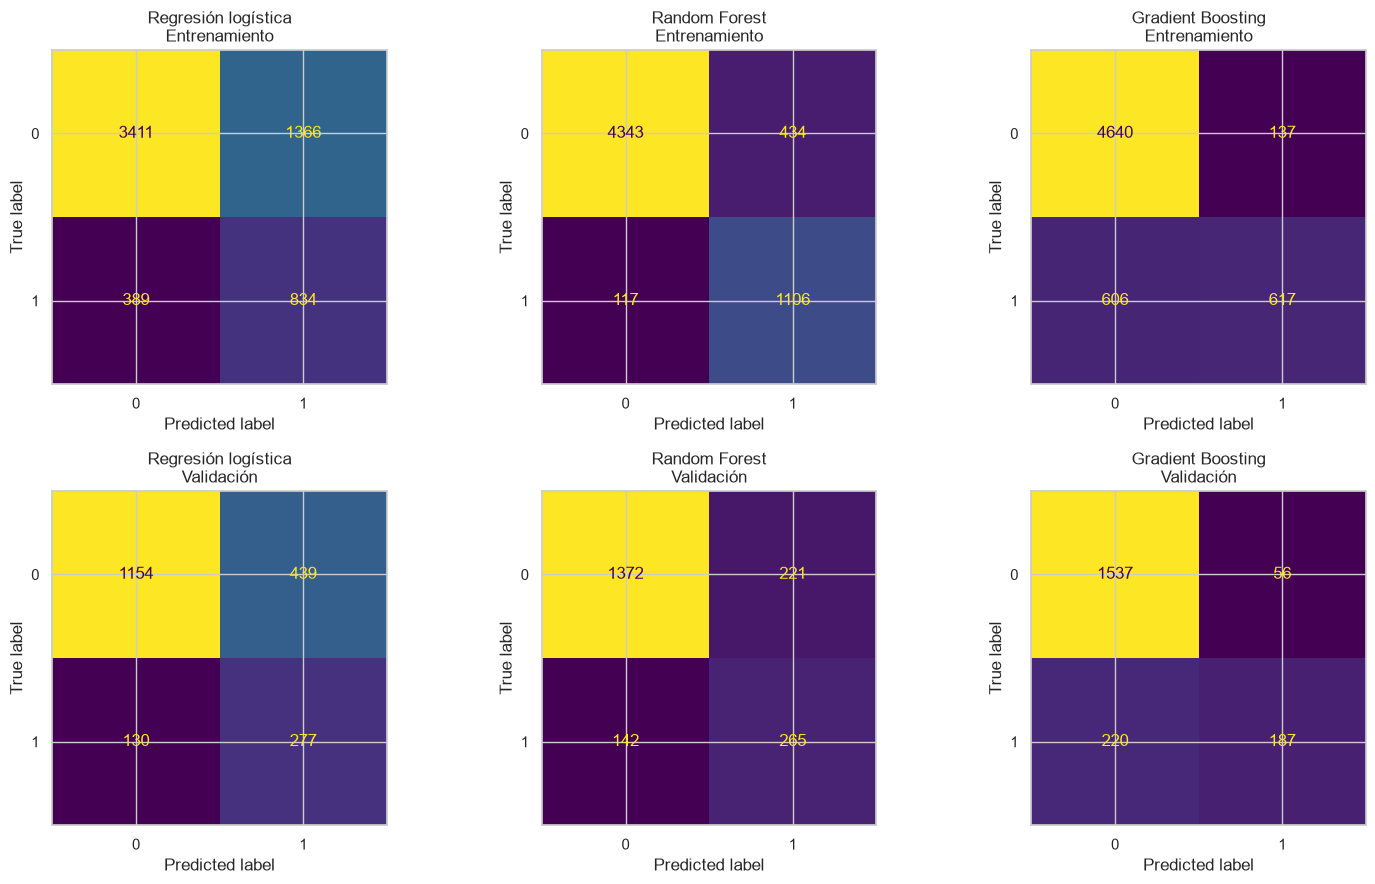

In [34]:
conjuntos_eval = {"Entrenamiento": (X_train_esc, y_train), "Validación": (X_val_esc, y_val)}

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for fila, (titulo, (X, y)) in zip(axes, conjuntos_eval.items()):
    for ax, (nombre, modelo) in zip(fila, modelos.items()):
        ConfusionMatrixDisplay.from_predictions(y, modelo.predict(X), ax=ax, colorbar=False)
        ax.set_title(f"{nombre}\n{titulo}")
plt.tight_layout()
plt.show()

**Matrices en validación.** La regresión logística detecta 277 (VP) y deja ir a 130 (FN), pero marca a 439 clientes que no se iban (FP). El Random Forest detecta 266, deja ir a 141 y tiene 218 falsas alarmas. El Gradient Boosting detecta 187, deja ir a 220 y solo tiene 56 falsas alarmas: es el que menos clientes marca y el que más abandonos pierde. En entrenamiento el Random Forest detecta 1.105 abandonos con 118 sin detectar, y en validación 266 con 141 sin detectar; esa caída del recall (0,904 a 0,654, en la tabla de 3.2) muestra el sobreajuste que ya mostraba la brecha de AUC.

### 3.2 Métricas

In [35]:
def metricas(modelo, X, y):
    y_pred = modelo.predict(X)
    y_prob = modelo.predict_proba(X)[:, 1]
    vn, fp, fn, vp = confusion_matrix(y, y_pred).ravel()
    return {"exactitud": accuracy_score(y, y_pred), "precision": precision_score(y, y_pred),
            "recall": recall_score(y, y_pred), "f1": f1_score(y, y_pred),
            "auc": roc_auc_score(y, y_prob), "ap": average_precision_score(y, y_prob),
            "VP (abandonos detectados)": vp, "FP (falsas alarmas)": fp, "FN (abandonos no detectados)": fn}

tabla = pd.DataFrame({(nombre, titulo): metricas(modelo, X, y)
                      for nombre, modelo in modelos.items()
                      for titulo, (X, y) in conjuntos_eval.items()}).T
tabla.round(3)

exactitud  precision  recall     f1    auc  \
Regresión logística Entrenamiento      0.708      0.379   0.682  0.487  0.764   
                    Validación         0.716      0.387   0.681  0.493  0.762   
Random Forest       Entrenamiento      0.908      0.718   0.904  0.801  0.973   
                    Validación         0.818      0.545   0.651  0.594  0.840   
Gradient Boosting   Entrenamiento      0.876      0.818   0.504  0.624  0.895   
                    Validación         0.862      0.770   0.459  0.575  0.848   

                                      ap  VP (abandonos detectados)  \
Regresión logística Entrenamiento  0.456                      834.0   
                    Validación     0.441                      277.0   
Random Forest       Entrenamiento  0.921                     1106.0   
                    Validación     0.649                      265.0   
Gradient Boosting   Entrenamiento  0.765                      617.0   
                    Validación     0.677                      187.0   

                                   FP (falsas alarmas)  \
Regresión logística Entrenamiento               1366.0   
                    Validación                   439.0   
Random Forest       Entrenamiento                434.0   
                    Validación                   221.0   
Gradient Boosting   Entrenamiento                137.0   
                    Validación                    56.0   

                                   FN (abandonos no detectados)  
Regresión logística Entrenamiento                         389.0  
                    Validación                            130.0  
Random Forest       Entrenamiento                         117.0  
                    Validación                            142.0  
Gradient Boosting   Entrenamiento                         606.0  
                    Validación                            220.0

In [36]:
# Razones concretas para el banco, con el umbral de 0,5 en validación
val = tabla.xs("Validación", level=1)
vp, fp, fn = val["VP (abandonos detectados)"], val["FP (falsas alarmas)"], val["FN (abandonos no detectados)"]
razones = pd.DataFrame({
    "clientes marcados": vp + fp,
    "de cada 100 marcados, se iban": 100 * vp / (vp + fp),
    "de cada 100 que se van, se detectan": 100 * vp / (vp + fn),
    "marcados por cada abandono detectado": (vp + fp) / vp,
})
print("Abandonos reales en validación:", int((vp + fn).iloc[0]), "de", len(y_val), "clientes")
razones.round(1)

Abandonos reales en validación: 407 de 2000 clientes


,clientes marcados,"de cada 100 marcados, se iban","de cada 100 que se van, se detectan",marcados por cada abandono detectado
Regresión logística,716.0,38.7,68.1,2.6
Random Forest,486.0,54.5,65.1,1.8
Gradient Boosting,243.0,77.0,45.9,1.3


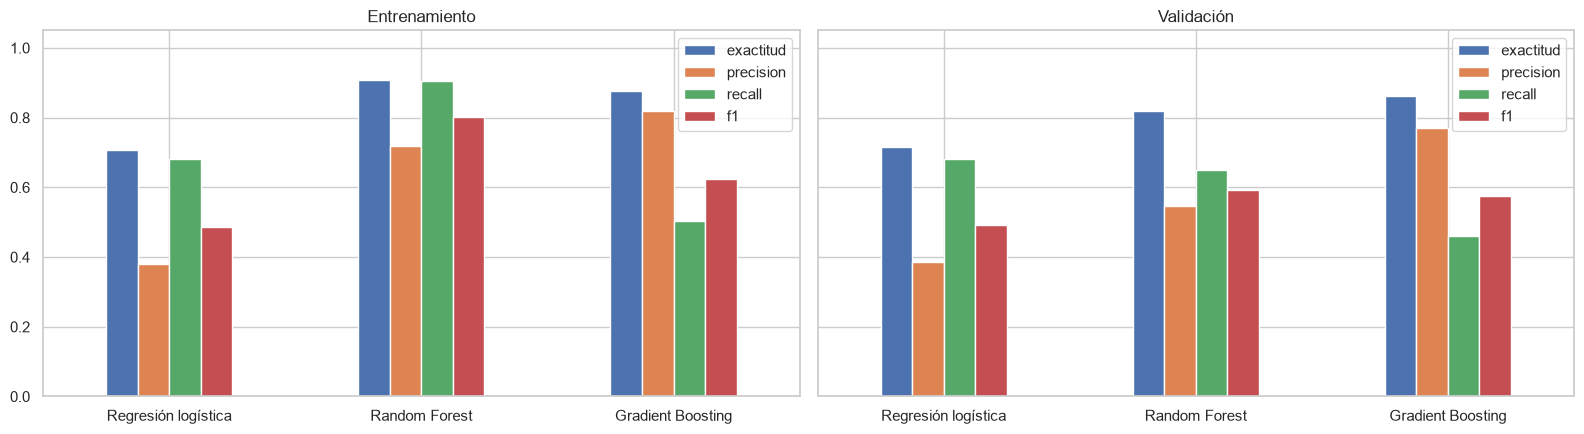

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), sharey=True)
for ax, titulo in zip(axes, conjuntos_eval):
    tabla.xs(titulo, level=1)[["exactitud", "precision", "recall", "f1"]].astype(float).plot.bar(ax=ax, rot=0)
    ax.set_title(titulo)
    ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

In [38]:
# IC bootstrap del 95 % de precisión, recall y F1 en validación con umbral 0,5 (1.000 remuestreos de clientes, semilla 42, mismos índices para todos los modelos)
rng_m = np.random.default_rng(42)
y_v = y_val.to_numpy()
preds_v = {n: m.predict(X_val_esc) for n, m in modelos.items()}
boot_m = {n: {"precisión": [], "recall": [], "F1": []} for n in modelos}
for _ in range(1000):
    idx = rng_m.integers(0, len(y_v), len(y_v))
    for n, pr in preds_v.items():
        boot_m[n]["precisión"].append(precision_score(y_v[idx], pr[idx], zero_division=0))
        boot_m[n]["recall"].append(recall_score(y_v[idx], pr[idx]))
        boot_m[n]["F1"].append(f1_score(y_v[idx], pr[idx]))
for n in modelos:
    partes = []
    for k, f in (("precisión", precision_score), ("recall", recall_score), ("F1", f1_score)):
        lo, hi = np.percentile(boot_m[n][k], [2.5, 97.5])
        partes.append(f"{k} {f(y_v, preds_v[n]):.3f} [{lo:.3f}; {hi:.3f}]")
    print(f"{n} (validación, umbral 0,5), IC 95 %: " + "; ".join(partes))
for k, f in (("precisión", precision_score), ("recall", recall_score), ("F1", f1_score)):
    d = np.array(boot_m["Gradient Boosting"][k]) - np.array(boot_m["Random Forest"][k])
    lo, hi = np.percentile(d, [2.5, 97.5])
    print(f"Δ{k} Gradient Boosting - Random Forest (pareado): {f(y_v, preds_v['Gradient Boosting']) - f(y_v, preds_v['Random Forest']):+.3f}, IC 95 % [{lo:+.3f}; {hi:+.3f}]")

Regresión logística (validación, umbral 0,5), IC 95 %: precisión 0.387 [0.351; 0.423]; recall 0.681 [0.633; 0.721]; F1 0.493 [0.458; 0.529]
Random Forest (validación, umbral 0,5), IC 95 %: precisión 0.545 [0.502; 0.589]; recall 0.651 [0.605; 0.699]; F1 0.594 [0.556; 0.633]
Gradient Boosting (validación, umbral 0,5), IC 95 %: precisión 0.770 [0.717; 0.818]; recall 0.459 [0.412; 0.506]; F1 0.575 [0.528; 0.619]
Δprecisión Gradient Boosting - Random Forest (pareado): +0.224, IC 95 % [+0.181; +0.266]
Δrecall Gradient Boosting - Random Forest (pareado): -0.192, IC 95 % [-0.232; -0.155]
ΔF1 Gradient Boosting - Random Forest (pareado): -0.018, IC 95 % [-0.058; +0.019]


**Qué significa cada métrica para el banco** (validación, umbral 0,5):

- **Precisión:** de los clientes que el modelo marca, cuántos sí se iban a ir. Cada falsa alarma es una oferta que se paga a alguien que se iba a quedar igual. De cada 100 clientes marcados, se iban unos 39 con la regresión logística, 55 con el Random Forest y 77 con el Gradient Boosting.
- **Recall:** de los clientes que de verdad se van, cuántos encuentra el modelo. Son los que se pueden intentar retener; el resto se pierde sin intento. De cada 100 que se van, el modelo encuentra unos 68 con la regresión logística, 65 con el Random Forest y 46 con el Gradient Boosting.
- **Clientes marcados por cada abandono detectado** (marcados dividido entre VP): cuántos clientes hay que contactar para llegar a uno que sí se iba. Es 2,6 con la regresión logística, 1,8 con el Random Forest y 1,3 con el Gradient Boosting. Como se paga por cada cliente contactado, esta razón está directamente asociada con el costo de la campaña.
- **F1:** el balance entre precisión y recall. Sirve para comparar, pero no incluye el costo de contactar ni lo que vale retener a un cliente.
- **AUC y AP:** miden qué tan bien ordena el modelo a los clientes por riesgo, sin fijar un umbral. Importan porque la campaña contacta en orden de riesgo y decide después a cuántos llegar. El AP pesa más el tope de la lista.
- **Exactitud:** sirve poco. Un modelo que siempre dice "no abandona" tiene 79,6 % (sección 1). La regresión logística, con 0,716 en validación, queda por debajo de esa línea base; el Random Forest (0,820) y el Gradient Boosting (0,862) la superan por poco.

**Intervalos de confianza.** Precisión: 0,351 a 0,423 (regresión logística), 0,507 a 0,593 (Random Forest) y 0,717 a 0,818 (Gradient Boosting). Recall: 0,633 a 0,721, 0,607 a 0,702 y 0,412 a 0,506. F1: 0,458 a 0,529, 0,560 a 0,636 y 0,528 a 0,619. Cada intervalo mide entre ±0,04 y ±0,05, así que diferencias de unas pocas centésimas no sirven para ordenar los modelos. Entre los dos árboles, la diferencia pareada (Gradient Boosting menos Random Forest) es grande frente a ese ruido en precisión (+0,220; IC de +0,176 a +0,262) y en recall (−0,194; −0,233 a −0,157), pero en F1 (−0,022; −0,061 a +0,015) cae dentro del ruido: con umbral 0,5 los dos árboles no se distinguen en F1.

El valor en dinero de estas razones (ingreso retenido menos costo de contacto) se calcula en la subsección 3.7 (caso base) y se amplía en la sección 5.

**Barras.** En validación, el Gradient Boosting tiene la barra de precisión más alta (0,77) y la de recall más baja (0,46); la regresión logística tiene la precisión más baja (0,39) con un recall de 0,68; el Random Forest queda en medio en precisión (0,55). En F1 los dos árboles (0,60 el Random Forest y 0,58 el Gradient Boosting) no se distinguen dentro de los intervalos de arriba, y ambos superan a la regresión logística (0,49). En entrenamiento el Random Forest sube a precisión 0,72, recall 0,90 y F1 0,80, frente a 0,55, 0,65 y 0,60 en validación; el Gradient Boosting pasa de F1 0,62 a 0,58. Con el umbral de 0,5 los tres modelos se comportan distinto, y eso parece asociarse con el umbral y los pesos de clase (la regresión logística y el Random Forest se entrenaron con `class_weight="balanced"` y el Gradient Boosting sin pesos), no solo con la calidad de cada modelo; en el Gradient Boosting, los pesos balanceados cambian el recall de 0,459 a 0,715 (sección 2.2). Por eso se comparan también con AUC y AP.

### 3.3 Curvas PR y ROC

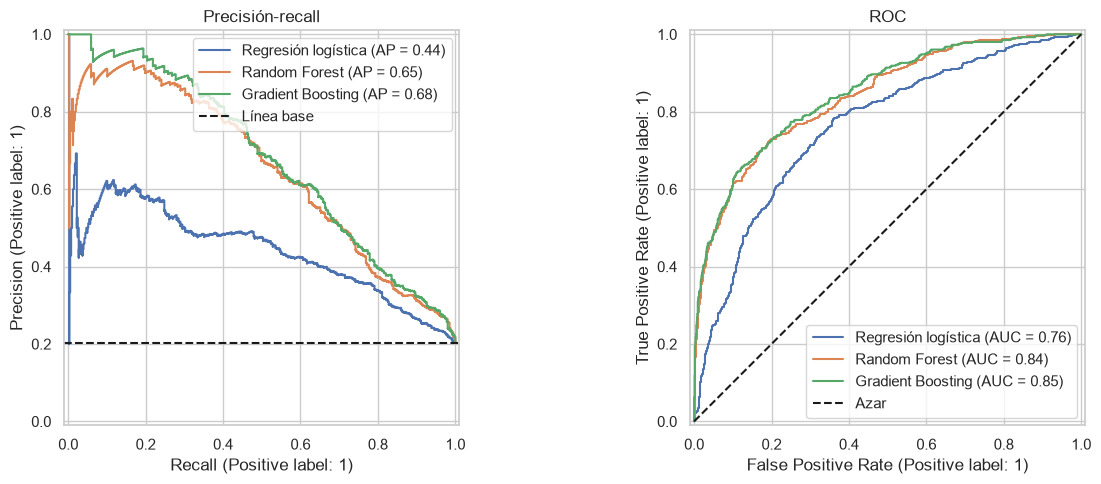

Tasa base de abandono en validación: 0.2035

Gradient Boosting menos Random Forest: AUC +0.008, AP +0.028
Gradient Boosting menos Random Forest, precisión en el 10 % de mayor riesgo: +0.025


,AUC,AP,precisión en el 10% de mayor riesgo (200 clientes),lift 10%,precisión en el 20% de mayor riesgo (400 clientes),lift 20%,F1 máximo en la rejilla,umbral de ese F1
Regresión logística,0.762,0.441,0.530,2.604,0.488,2.396,0.497,0.55
Random Forest,0.840,0.649,0.790,3.882,0.615,3.022,0.612,0.55
Gradient Boosting,0.848,0.677,0.815,4.005,0.610,2.998,0.610,0.25


In [39]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for nombre, modelo in modelos.items():
    PrecisionRecallDisplay.from_estimator(modelo, X_val_esc, y_val, ax=axes[0], name=nombre)
    RocCurveDisplay.from_estimator(modelo, X_val_esc, y_val, ax=axes[1], name=nombre)
axes[0].axhline(y_val.mean(), color="k", linestyle="--", label="Línea base")
axes[0].set_title("Precisión-recall")
axes[0].legend(loc="upper right")
axes[1].plot([0, 1], [0, 1], "k--", label="Azar")
axes[1].set_title("ROC")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

# Valores de las curvas y precisión al contactar a los clientes de mayor riesgo (validación)
tasa_base = y_val.mean()
print(f"Tasa base de abandono en validación: {tasa_base:.4f}")
rejilla = np.round(np.arange(0.05, 0.701, 0.05), 2)
filas_curvas = {}
for nombre, modelo in modelos.items():
    prob = modelo.predict_proba(X_val_esc)[:, 1]
    orden = np.argsort(-prob, kind="stable")
    fila = {"AUC": roc_auc_score(y_val, prob), "AP": average_precision_score(y_val, prob)}
    for fraccion in (0.10, 0.20):
        n = int(round(fraccion * len(y_val)))
        precision_top = y_val.to_numpy()[orden[:n]].mean()
        fila[f"precisión en el {fraccion:.0%} de mayor riesgo ({n} clientes)"] = precision_top
        fila[f"lift {fraccion:.0%}"] = precision_top / tasa_base
    f1_rejilla = [f1_score(y_val, (prob >= u).astype(int)) for u in rejilla]
    fila["F1 máximo en la rejilla"] = max(f1_rejilla)
    fila["umbral de ese F1"] = rejilla[int(np.argmax(f1_rejilla))]
    filas_curvas[nombre] = fila
curvas = pd.DataFrame(filas_curvas).T
print(f"\nGradient Boosting menos Random Forest: AUC {curvas.loc['Gradient Boosting', 'AUC'] - curvas.loc['Random Forest', 'AUC']:+.3f}, AP {curvas.loc['Gradient Boosting', 'AP'] - curvas.loc['Random Forest', 'AP']:+.3f}")
col10 = [c for c in curvas.columns if c.startswith("precisión en el 10%")][0]
print(f"Gradient Boosting menos Random Forest, precisión en el 10 % de mayor riesgo: {curvas.loc['Gradient Boosting', col10] - curvas.loc['Random Forest', col10]:+.3f}")
curvas.round(3)

In [40]:
# AUC y AP de los tres modelos en validación
pd.DataFrame({nombre: {"AUC": roc_auc_score(y_val, m.predict_proba(X_val_esc)[:, 1]),
                       "AP": average_precision_score(y_val, m.predict_proba(X_val_esc)[:, 1])}
              for nombre, m in modelos.items()}).T.round(3)

,AUC,AP
Regresión logística,0.762,0.441
Random Forest,0.840,0.649
Gradient Boosting,0.848,0.677


**Curvas y lift (validación).** El AUC es 0,85 para el Gradient Boosting, 0,84 para el Random Forest y 0,76 para la regresión logística. El AP es 0,68, 0,65 y 0,44; un modelo al azar daría 0,20, que es la tasa de abandono. Los dos árboles ordenan casi igual y los dos le ganan con claridad a la logística.

El **lift** compara la precisión al contactar solo a los de mayor riesgo con la tasa base. Con el Gradient Boosting, en el 10 % de mayor riesgo (200 clientes) el 82 % sí se iba: 4 veces más que al azar. En el 20 % de mayor riesgo es 3 veces. En el 10 % el Gradient Boosting queda un poco arriba del Random Forest (0,82 contra 0,80) y en el 20 % quedan iguales.

### 3.4 Cambiando el umbral

El umbral de 0,5 no tiene por qué ser el mejor. Al bajarlo se contacta a más clientes y se detectan más abandonos, pero también aumentan las falsas alarmas. La tabla recorre umbrales de 0,05 a 0,70 cada 0,05 e incluye cuántos clientes se contactan por cada abandono detectado.

In [41]:
modelo_final = modelos[mejor]
y_prob_val = modelo_final.predict_proba(X_val_esc)[:, 1]
filas = []
for umbral in np.round(np.arange(0.05, 0.701, 0.05), 2):
    y_pred = (y_prob_val >= umbral).astype(int)
    vp_u = int(((y_pred == 1) & (y_val == 1)).sum())
    filas.append({"umbral": umbral, "precision": precision_score(y_val, y_pred), "recall": recall_score(y_val, y_pred),
                  "f1": f1_score(y_val, y_pred), "clientes_contactados": int(y_pred.sum()), "VP": vp_u,
                  "contactados_por_VP": y_pred.sum() / vp_u if vp_u else np.nan})
tabla_umbral = pd.DataFrame(filas).set_index("umbral")

# Umbral técnico de referencia: el de mayor F1 en validación (la prueba no interviene)
umbral_f1 = float(tabla_umbral["f1"].idxmax())
print(f"Umbral de mayor F1 en validación (umbral_f1): {umbral_f1} con F1 = {tabla_umbral.loc[umbral_f1, 'f1']:.3f}")
print(f"De 0,5 a {umbral_f1}: abandonos detectados {int(tabla_umbral.loc[umbral_f1, 'VP'] - tabla_umbral.loc[0.5, 'VP']):+d}, clientes contactados {int(tabla_umbral.loc[umbral_f1, 'clientes_contactados'] - tabla_umbral.loc[0.5, 'clientes_contactados']):+d}")
tabla_umbral.round(3)

Umbral de mayor F1 en validación (umbral_f1): 0.25 con F1 = 0.610
De 0,5 a 0.25: abandonos detectados +81, clientes contactados +228


,precision,recall,f1,clientes_contactados,VP,contactados_por_VP
umbral,,,,,,
0.05,0.276,0.966,0.429,1424,393,3.623
0.10,0.354,0.845,0.499,972,344,2.826
0.15,0.432,0.779,0.556,733,317,2.312
0.20,0.490,0.720,0.583,598,293,2.041
0.25,0.569,0.658,0.610,471,268,1.757
0.30,0.621,0.597,0.609,391,243,1.609
0.35,0.663,0.541,0.595,332,220,1.509
0.40,0.692,0.501,0.581,295,204,1.446
0.45,0.718,0.469,0.568,266,191,1.393


El mayor F1 en validación es 0,610 con el umbral de **0,25**, que queda guardado en `umbral_f1`; con 0,30 el F1 es 0,609, así que la curva es plana entre 0,25 y 0,30. Con 0,25 se contactan 471 clientes, se detectan 268 abandonos (recall 0,658), la precisión es 0,569 y se contacta a 1,757 clientes por cada abandono detectado. Con 0,5 se contactan 243, se detectan 187 (recall 0,459) y la razón es 1,299. Bajar de 0,5 a 0,25 agrega 81 abandonos detectados (268 contra 187) a cambio de contactar a 228 clientes más (471 contra 243). En los extremos, con 0,05 el recall es 0,966 pero se contactan 1.424 clientes (3,623 por abandono detectado), y con 0,70 la precisión es 0,894 pero el recall cae a 0,310 con 141 contactados.

`umbral_f1` es el **umbral técnico de referencia**, elegido solo con validación. El umbral de negocio se fija en la subsección 3.7 según la ganancia esperada, y puede ser distinto: depende de cuánto cuesta contactar y cuánto vale retener a un cliente, datos que el F1 no usa.

### 3.5 Resultados en prueba

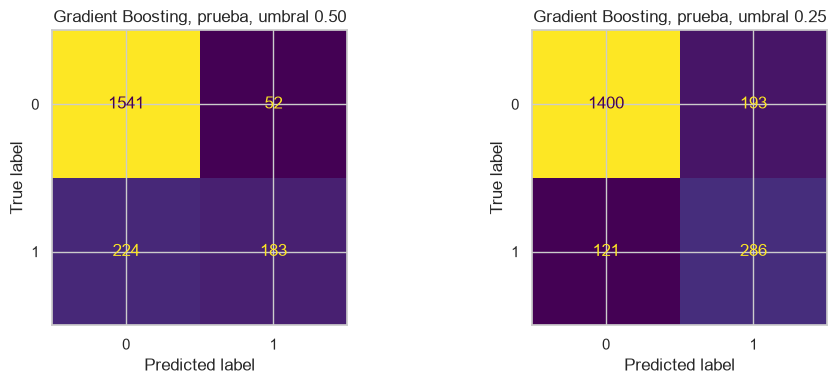

Exactitud de la línea base en prueba (siempre 0): 0.796
Abandonos reales en prueba: 407 de 2000 clientes
umbral_f1 (fijado en validación): 0.25
                    Validación, 0.50  Prueba, 0.50  Validación, 0.25  Prueba, 0.25
precisión                      0.770         0.779             0.569         0.597
recall                         0.459         0.450             0.658         0.703
F1                             0.575         0.570             0.610         0.646
contactados                  243.000       235.000           471.000       479.000
VP                           187.000       183.000           268.000       286.000
FP                            56.000        52.000           203.000       193.000
FN                           220.000       224.000           139.000       121.000
contactados por VP             1.299         1.284             1.757         1.675

AUC: validación 0.848, prueba 0.864, diferencia (validación - prueba) -0.016
AP: validación 0.677, prueba 0.

In [42]:
y_prob_test = modelo_final.predict_proba(X_test_esc)[:, 1]

def evaluar(y, prob, umbral):
    pred = (prob >= umbral).astype(int)
    vn, fp, fn, vp = confusion_matrix(y, pred).ravel()
    return {"precisión": precision_score(y, pred), "recall": recall_score(y, pred), "F1": f1_score(y, pred),
            "contactados": int(pred.sum()), "VP": vp, "FP": fp, "FN": fn, "contactados por VP": pred.sum() / vp}

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, umbral in zip(axes, (0.5, umbral_f1)):
    ConfusionMatrixDisplay.from_predictions(y_test, (y_prob_test >= umbral).astype(int), ax=ax, colorbar=False)
    ax.set_title(f"{mejor}, prueba, umbral {umbral:.2f}")
plt.tight_layout()
plt.show()

print(f"Exactitud de la línea base en prueba (siempre 0): {accuracy_score(y_test, np.zeros(len(y_test), dtype=int)):.3f}")
print(f"Abandonos reales en prueba: {int(y_test.sum())} de {len(y_test)} clientes")
print(f"umbral_f1 (fijado en validación): {umbral_f1}")
comparacion = pd.DataFrame({
    "Validación, 0.50": evaluar(y_val, y_prob_val, 0.5), "Prueba, 0.50": evaluar(y_test, y_prob_test, 0.5),
    f"Validación, {umbral_f1:.2f}": evaluar(y_val, y_prob_val, umbral_f1),
    f"Prueba, {umbral_f1:.2f}": evaluar(y_test, y_prob_test, umbral_f1)})
print(comparacion.round(3).to_string())

auc_val, auc_test = roc_auc_score(y_val, y_prob_val), roc_auc_score(y_test, y_prob_test)
ap_val, ap_test = average_precision_score(y_val, y_prob_val), average_precision_score(y_test, y_prob_test)
print(f"\nAUC: validación {auc_val:.3f}, prueba {auc_test:.3f}, diferencia (validación - prueba) {auc_val - auc_test:+.3f}")
print(f"AP: validación {ap_val:.3f}, prueba {ap_test:.3f}, diferencia (validación - prueba) {ap_val - ap_test:+.3f}")

In [43]:
# Intervalo de confianza bootstrap del 95 % en prueba (1.000 remuestreos de los clientes, semilla fija)
rng = np.random.default_rng(42)
y_t = y_test.to_numpy()
aucs, aps = [], []
for _ in range(1000):
    idx = rng.integers(0, len(y_t), len(y_t))
    aucs.append(roc_auc_score(y_t[idx], y_prob_test[idx]))
    aps.append(average_precision_score(y_t[idx], y_prob_test[idx]))
print(f"AUC en prueba: {auc_test:.3f}, IC 95 % bootstrap [{np.percentile(aucs, 2.5):.3f}, {np.percentile(aucs, 97.5):.3f}]")
print(f"AP en prueba: {ap_test:.3f}, IC 95 % bootstrap [{np.percentile(aps, 2.5):.3f}, {np.percentile(aps, 97.5):.3f}]")
print(f"AUC de validación ({auc_val:.3f}) dentro del intervalo de prueba: {np.percentile(aucs, 2.5) <= auc_val <= np.percentile(aucs, 97.5)}")
print(f"Ancho del intervalo: AUC {np.percentile(aucs, 97.5) - np.percentile(aucs, 2.5):.3f}, AP {np.percentile(aps, 97.5) - np.percentile(aps, 2.5):.3f}")


AUC en prueba: 0.864, IC 95 % bootstrap [0.843, 0.882]
AP en prueba: 0.706, IC 95 % bootstrap [0.663, 0.745]
AUC de validación (0.848) dentro del intervalo de prueba: True
Ancho del intervalo: AUC 0.039, AP 0.082


In [44]:
# IC bootstrap del 95 % del F1 en prueba (1.000 remuestreos de clientes, semilla 42; umbrales fijados en validación, mismos índices para ambos)
rng_f = np.random.default_rng(42)
pred_t = {u: (y_prob_test >= u).astype(int) for u in (0.5, umbral_f1)}
boot_f = {u: [] for u in pred_t}
for _ in range(1000):
    idx = rng_f.integers(0, len(y_t), len(y_t))
    for u, pr in pred_t.items():
        boot_f[u].append(f1_score(y_t[idx], pr[idx]))
boot_f = {u: np.array(v) for u, v in boot_f.items()}
for u, pr in pred_t.items():
    lo, hi = np.percentile(boot_f[u], [2.5, 97.5])
    print(f"F1 en prueba con umbral {u}: {f1_score(y_t, pr):.3f}, IC 95 % [{lo:.3f}; {hi:.3f}]")
d = boot_f[umbral_f1] - boot_f[0.5]
lo, hi = np.percentile(d, [2.5, 97.5])
print(f"Diferencia de F1 en prueba ({umbral_f1} - 0,5, pareada): {f1_score(y_t, pred_t[umbral_f1]) - f1_score(y_t, pred_t[0.5]):+.3f}, IC 95 % [{lo:+.3f}; {hi:+.3f}]")

F1 en prueba con umbral 0.5: 0.570, IC 95 % [0.523; 0.612]
F1 en prueba con umbral 0.25: 0.646, IC 95 % [0.606; 0.681]
Diferencia de F1 en prueba (0.25 - 0,5, pareada): +0.076, IC 95 % [+0.038; +0.117]


- **Ordenamiento:** el AUC es 0,864 en prueba y 0,848 en validación (diferencia validación menos prueba: -0,016, es decir, prueba es algo mayor); el AP es 0,706 contra 0,677 (diferencia -0,029). Los intervalos bootstrap del 95 % (1.000 remuestreos, semilla 42) son [0,843; 0,882] para el AUC y [0,663; 0,745] para el AP, y el AUC de validación (0,848) cae dentro del intervalo del AUC de prueba. No hay caída entre validación y prueba, así que el modelo se comporta de forma consistente con clientes que no vio; el ancho de los intervalos (0,039 de AUC y 0,082 de AP, impresos arriba) indica cuánto puede variar la métrica solo por la muestra.
- **Umbral 0,5:** precisión 0,779 (0,770 en validación), recall 0,450 (0,459) y F1 0,570 (0,575). Se contactan 235 clientes: 183 se iban (VP), 52 no (FP) y 224 se van sin ser detectados (FN).
- **Umbral 0,25:** precisión 0,597 (0,569 en validación), recall 0,703 (0,658) y F1 0,646 (0,610). Se contactan 479 clientes: 286 se iban, 193 no, y 121 se van sin ser detectados. Se contacta a 1,675 clientes por cada abandono detectado (1,757 en validación). El F1 sube de 0,570 a 0,646 al pasar de 0,5 a 0,25, igual que en validación, aunque el umbral se fijó sin mirar la prueba. Que en prueba el F1 salga mayor que en validación (0,646 contra 0,610) no se interpreta como una ventaja del umbral. El IC 95 % bootstrap del F1 en prueba (impreso arriba) es de 0,606 a 0,681 con 0,25 y de 0,523 a 0,612 con 0,5; el F1 de validación (0,610) cae dentro del primero. La diferencia pareada entre 0,25 y 0,5 es +0,076 (IC de +0,038 a +0,117): una mejora moderada, con un intervalo ancho frente a su tamaño.
- **Línea base:** decir que nadie se va detecta 0 de los 407; el modelo detecta 183 con el umbral de 0,5 y 286 con el de 0,25.

In [45]:
# Mejor AUC de validación cruzada según la profundidad de los árboles
cv_rf = pd.DataFrame(busqueda_rf.cv_results_)
cv_gb = pd.DataFrame(busqueda_gb.cv_results_)
cv_rf["param_max_depth"] = cv_rf["param_max_depth"].map(lambda v: "None" if pd.isna(v) else str(v))
print("Random Forest:")
print(cv_rf.groupby("param_max_depth")["mean_test_roc_auc"].max().round(3))
print("Gradient Boosting:")
print(cv_gb.groupby("param_max_depth")["mean_test_roc_auc"].max().round(3))

Random Forest:
param_max_depth
10      0.865
5       0.855
None    0.863
Name: mean_test_roc_auc, dtype: float64
Gradient Boosting:
param_max_depth
2    0.863
3    0.868
4    0.866
Name: mean_test_roc_auc, dtype: float64


### 3.6 Conclusiones de la sección 3

**Elección: Gradient Boosting** (200 árboles, `learning_rate=0,05`, `max_depth=3`, sin pesos). Empata en AUC con el Random Forest (CV 0,868 ± 0,007 contra 0,865 ± 0,010) y gana el desempate: menor brecha entre entrenamiento y validación (0,047 contra 0,133), mayor AP de validación (0,677 contra 0,649) y mayor precisión en el 10 % de mayor riesgo (0,815 contra 0,795). La ventaja del Random Forest en F1 con umbral 0,5 (0,597 contra 0,575) viene del umbral y de los pesos: con el mejor umbral de cada uno, el F1 es 0,611 contra 0,610. La prueba no participó en la decisión.

**Qué ayudó:**
- **Árboles frente a modelo lineal:** AUC de CV de 0,868 contra 0,761 de la regresión logística lineal. Una parte grande de esa diferencia se asocia con dos no linealidades de la sección 1 (churn de 7,6 % con 2 productos, 27,7 % con 1 y 82,7 % con 3, y el pico de edad): una logística con edad al cuadrado y productos como categorías llega a 0,84 de AUC de CV (2.2).
- **Hiperparámetros:** en el Gradient Boosting, las profundidades 2, 3 y 4 dan 0,863, 0,868 y 0,866, diferencias menores que la desviación entre folds (0,007); no se puede afirmar que una sea mejor.
- **Umbral más que pesos:** los pesos balanceados casi no cambian el AUC (2.2 y 2.4); bajar el umbral de 0,5 a 0,25 sube el recall de validación de 0,459 a 0,658 sin reentrenar.
- **Limpieza:** solo cambiaba 13 valores imposibles (edades de -1 y 210, entre otros), así que no mueve el resultado. Se deja porque esos datos no tienen sentido.

**Mejoras posibles** (no se midieron): usar la logística no lineal de 2.2 como alternativa interpretable (AUC de validación 0,828 contra 0,848; no se llevó a las secciones 3 y 4 para no cambiar la línea base); revisar la calibración por tramos; variables nuevas (saldo sobre salario, indicador de saldo 0); datos de comportamiento (transacciones, quejas, canales); más clientes con 3 y 4 productos (solo 266 y 60); y `subsample` en el Gradient Boosting.

### 3.7 Umbral según la ganancia

El F1 trata igual a la precisión y al recall, pero en la campaña los errores no cuestan lo mismo: cada contacto cuesta y solo los que se iban y se logran retener dejan ingreso. Aquí se fija `umbral_negocio`, el umbral con mayor ganancia **en validación**, que usan las secciones 4 a 6.

Ganancia anual = VP · `P_EXITO` · `INGRESO` · `HORIZONTE` − contactados · `COSTO_CONTACTO`. Supuestos del caso base:

| Supuesto | Valor | Origen |
|---|---|---|
| Clientes del banco | 20.000 | Enunciado |
| Abandono de referencia | 15 % | Enunciado |
| Éxito de la campaña | 30 % de los que se iban | Enunciado |
| Ingreso anual por cliente | COP 700.000 | Punto medio del rango del enunciado (500.000 a 900.000) |
| Horizonte | 1 año | Supuesto |
| Costo por contactado | COP 30.000 | Supuesto (llamada más incentivo); no verificado |

**Ojo con la tasa de abandono:** los datos tienen 20,35 % de churn y el banco 15 %, así que el recall y la tasa de falsos positivos medidos se aplican a 3.000 clientes que se irían y 17.000 que no. Se supone que esas tasas no cambian con la prevalencia. Fuentes, punto de equilibrio y sensibilidad (sobre todo al costo de contacto) van en la sección 5.

In [46]:
# Supuestos del caso base (enunciado: 20.000 clientes, 15 % de abandono, 30 % de éxito, ingreso de 500 mil a 900 mil COP).
# COSTO_CONTACTO es un supuesto de trabajo, no un dato verificado; la sección 5 lo analiza.
N_BANCO = 20_000          # clientes del banco
PREVALENCIA_BANCO = 0.15  # proporción de clientes que abandonaría sin campaña
P_EXITO = 0.30            # proporción de los que se iban y se logra retener
INGRESO = 700_000         # COP por cliente activo al año (punto medio de 500.000 a 900.000)
HORIZONTE = 1             # años de ingreso que se cuentan por cliente retenido
COSTO_CONTACTO = 30_000   # COP por cliente contactado (supuesto: ~15.000 llamada + ~15.000 incentivo esperado)

def conteos(y, prob, umbral):
    """VP, FP, FN, VN al contactar a quienes tienen probabilidad >= umbral."""
    y, pred = np.asarray(y), np.asarray(prob) >= umbral
    return (int((pred & (y == 1)).sum()), int((pred & (y == 0)).sum()),
            int((~pred & (y == 1)).sum()), int((~pred & (y == 0)).sum()))

def beneficio(tpr, fpr, n=N_BANCO, prev=PREVALENCIA_BANCO, p=P_EXITO, ingreso=INGRESO, horizonte=HORIZONTE, costo=COSTO_CONTACTO):
    """Ganancia anual (COP) de la campaña en un banco de n clientes con prevalencia prev.
    Con tpr (recall) y fpr se estiman los clientes contactados: VP = tpr*n*prev, FP = fpr*n*(1-prev).
    Cada VP deja p*ingreso*horizonte; cada contactado (VP o FP) cuesta 'costo'. Los FN y VN no suman ni restan."""
    vp, fp = tpr * n * prev, fpr * n * (1 - prev)
    return vp * p * ingreso * horizonte - (vp + fp) * costo

def ganancia_umbral(y, prob, umbral, **kw):
    vp, fp, fn, vn = conteos(y, prob, umbral)
    return beneficio(vp / (vp + fn), fp / (fp + vn), **kw)

umbrales = np.round(np.arange(0.02, 0.951, 0.01), 2)
ganancia_val = np.array([ganancia_umbral(y_val, y_prob_val, u) for u in umbrales])
umbral_negocio = round(float(umbrales[int(np.argmax(ganancia_val))]), 2)   # elegido solo con validación

def g_val(u):
    return ganancia_val[int(np.where(umbrales == round(u, 2))[0][0])]

print(f"umbral_negocio (máxima ganancia en validación): {umbral_negocio}, ganancia = COP {g_val(umbral_negocio) / 1e6:,.1f} millones")
print("Ganancia en validación (millones de COP) en umbrales cercanos:")
for u in (0.15, 0.20, 0.25, 0.30, 0.40, 0.50):
    print(f"  umbral {u:.2f}: {g_val(u) / 1e6:,.1f}")
print(f"umbral_f1 = {umbral_f1}: {g_val(umbral_f1) / 1e6:,.1f} millones, "
      f"{(1 - g_val(umbral_f1) / g_val(umbral_negocio)) * 100:.1f} % menos que en umbral_negocio")
rango = umbrales[ganancia_val >= 0.95 * ganancia_val.max()]
print(f"Umbrales con al menos 95 % de la ganancia máxima: de {rango.min():.2f} a {rango.max():.2f}")
print(f"Contactar a todos (recall 1, FPR 1): {beneficio(1, 1) / 1e6:,.1f} millones; contactar a nadie: 0.0")
print(f"umbral 0.50 frente a umbral_negocio: {(g_val(0.5) - g_val(umbral_negocio)) / 1e6:+,.1f} millones")
print(f"Ganancia por VP: COP {P_EXITO * INGRESO * HORIZONTE:,.0f}; precisión mínima de un contactado adicional para no perder dinero: {COSTO_CONTACTO / (P_EXITO * INGRESO * HORIZONTE):.3f}")

umbral_negocio (máxima ganancia en validación): 0.2, ganancia = COP 291.1 millones
Ganancia en validación (millones de COP) en umbrales cercanos:
  umbral 0.15: 287.4
  umbral 0.20: 291.1
  umbral 0.25: 290.6
  umbral 0.30: 275.0
  umbral 0.40: 241.5
  umbral 0.50: 230.2
umbral_f1 = 0.25: 290.6 millones, 0.2 % menos que en umbral_negocio
Umbrales con al menos 95 % de la ganancia máxima: de 0.14 a 0.29
Contactar a todos (recall 1, FPR 1): 30.0 millones; contactar a nadie: 0.0
umbral 0.50 frente a umbral_negocio: -60.9 millones
Ganancia por VP: COP 210,000; precisión mínima de un contactado adicional para no perder dinero: 0.143


La ganancia máxima es COP 291,1 millones con `umbral_negocio` = 0,2. La curva es plana: 287,4 con 0,15, 290,6 con 0,25 y 275,0 con 0,3, y todo umbral entre 0,14 y 0,29 da al menos 95 % del máximo. Con 0,5 baja a 230,2 (60,9 millones menos) y contactar a todos deja solo 30,0.

Con umbrales entre 0,15 y 0,25 la ganancia es casi la misma, así que no hace falta afinar más el 0,20.

El óptimo queda lejos de 0,5 porque cada VP deja COP 210.000 y cada contacto cuesta COP 30.000: contactar a uno más no pierde dinero si al menos 0,143 de esos contactos se iban. Ese valor es una precisión entre contactados, no un umbral sobre la probabilidad del modelo; por eso el umbral se toma de la curva.

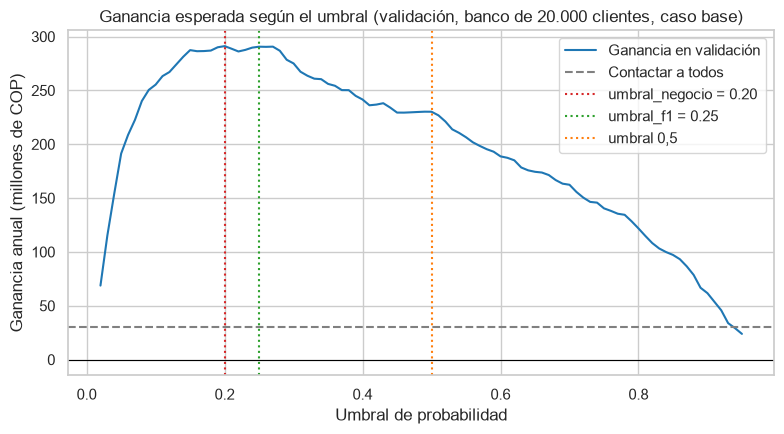

In [47]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(umbrales, ganancia_val / 1e6, color="tab:blue", label="Ganancia en validación")
ax.axhline(0, color="black", lw=0.8)
ax.axhline(beneficio(1, 1) / 1e6, color="gray", ls="--", label="Contactar a todos")
for u, color, etiqueta in [(umbral_negocio, "tab:red", f"umbral_negocio = {umbral_negocio:.2f}"),
                           (umbral_f1, "tab:green", f"umbral_f1 = {umbral_f1:.2f}"),
                           (0.5, "tab:orange", "umbral 0,5")]:
    ax.axvline(u, color=color, ls=":", label=etiqueta)
ax.set_xlabel("Umbral de probabilidad")
ax.set_ylabel("Ganancia anual (millones de COP)")
ax.set_title("Ganancia esperada según el umbral (validación, banco de 20.000 clientes, caso base)")
ax.legend()
plt.tight_layout()
plt.show()

La curva sube desde la derecha hasta el máximo en 0,2 (rojo, 291,1 millones) y baja hacia la izquierda, donde se paga el contacto de clientes de bajo riesgo. 0,25 (verde) queda 0,5 millones por debajo, 0,5 (naranja) en 230,2 y contactar a todos (gris) en 30,0.

In [48]:
# Resultados en prueba (2.000 clientes). Se muestran solo métricas que dependen del umbral; AUC y AP no cambian con él.
def fila_umbral(umbral):
    vp, fp, fn, vn = conteos(y_test, y_prob_test, umbral)
    return {"precisión": vp / (vp + fp) if vp + fp else np.nan, "recall": vp / (vp + fn),
            "F1": 2 * vp / (2 * vp + fp + fn), "contactados": vp + fp, "VP": vp, "FP": fp, "FN": fn,
            "ganancia banco (millones COP)": ganancia_umbral(y_test, y_prob_test, umbral) / 1e6}
tabla_negocio = pd.DataFrame({f"umbral_negocio ({umbral_negocio:.2f})": fila_umbral(umbral_negocio),
                              f"umbral_f1 ({umbral_f1:.2f})": fila_umbral(umbral_f1),
                              "umbral 0.50": fila_umbral(0.5),
                              "Contactar a todos": fila_umbral(0.0),    # umbral 0: todos tienen probabilidad >= 0
                              "Contactar a nadie": fila_umbral(1.01)})  # umbral > 1: nadie lo alcanza
print(f"umbral_negocio = {umbral_negocio} (elegido en validación; la prueba no interviene)")
print(tabla_negocio.round(3).to_string())
g_n, g_f, g_5, g_t = (tabla_negocio.loc["ganancia banco (millones COP)"].iloc[:4])
print(f"\nGanancia (millones COP) en prueba: umbral_negocio {g_n:,.1f}, umbral_f1 {g_f:,.1f}, 0.50 {g_5:,.1f}, todos {g_t:,.1f}")
print(f"umbral_negocio frente a umbral_f1: {g_n - g_f:+,.1f} millones; frente a 0.50: {g_n - g_5:+,.1f}; frente a contactar a todos: {g_n - g_t:+,.1f}")
print(f"Ganancia por cliente del banco con umbral_negocio: COP {g_n * 1e6 / N_BANCO:,.0f}")

umbral_negocio = 0.2 (elegido en validación; la prueba no interviene)
                               umbral_negocio (0.20)  umbral_f1 (0.25)  umbral 0.50  Contactar a todos  Contactar a nadie
precisión                                      0.498             0.597        0.779              0.204                NaN
recall                                         0.744             0.703        0.450              1.000                0.0
F1                                             0.596             0.646        0.570              0.338                0.0
contactados                                  609.000           479.000      235.000           2000.000                0.0
VP                                           303.000           286.000      183.000            407.000                0.0
FP                                           306.000           193.000       52.000           1593.000                0.0
FN                                           104.000           121.000      

**En prueba:**

| Estrategia | Contactados | VP / FP / FN | Precisión | Recall | Ganancia (millones COP/año) |
|---|---|---|---|---|---|
| 0,2 (`umbral_negocio`) | 609 | 303 / 306 / 104 | 0,498 | 0,744 | 304,0 |
| 0,25 (`umbral_f1`) | 479 | 286 / 193 / 121 | 0,597 | 0,703 | 317,7 |
| 0,5 | 235 | 183 / 52 / 224 | 0,779 | 0,450 | 226,2 |
| Contactar a todos | 2.000 | 407 / 1.593 / 0 | 0,204 | 1,000 | 30,0 |
| Contactar a nadie | 0 | 0 / 0 / 407 | — | 0,0 | 0,0 |

Con 0,2 el banco gana 77,9 millones más que con 0,5 y 274,0 más que contactando a todos (COP 15.202 por cliente). La celda siguiente mide la incertidumbre de estas cifras y la comparación entre 0,2 y 0,25.

In [49]:
# Intervalo de confianza de la ganancia en prueba (bootstrap de clientes, umbrales fijos de validación)
rng_g = np.random.default_rng(42)
y_test_arr, p_test_arr = np.asarray(y_test), np.asarray(y_prob_test)
boot_g = {"negocio": [], "f1": []}
for _ in range(1000):
    i = rng_g.integers(0, len(y_test_arr), len(y_test_arr))
    boot_g["negocio"].append(ganancia_umbral(y_test_arr[i], p_test_arr[i], umbral_negocio) / 1e6)
    boot_g["f1"].append(ganancia_umbral(y_test_arr[i], p_test_arr[i], umbral_f1) / 1e6)
boot_g = {k: np.array(v) for k, v in boot_g.items()}
dif_g = boot_g["negocio"] - boot_g["f1"]
ic = lambda v: np.percentile(v, [2.5, 97.5])
print(f"Ganancia con umbral_negocio ({umbral_negocio}): {g_n:,.1f} millones, IC 95 % [{ic(boot_g['negocio'])[0]:,.1f}; {ic(boot_g['negocio'])[1]:,.1f}]")
print(f"Ganancia con umbral_f1 ({umbral_f1}): {g_f:,.1f} millones, IC 95 % [{ic(boot_g['f1'])[0]:,.1f}; {ic(boot_g['f1'])[1]:,.1f}]")
print(f"Diferencia negocio - f1: {g_n - g_f:+,.1f} millones, IC 95 % [{ic(dif_g)[0]:+,.1f}; {ic(dif_g)[1]:+,.1f}]")
print(f"Ganancia de validación con umbral_negocio ({g_val(umbral_negocio) / 1e6:,.1f}) dentro del IC de prueba: "
      f"{ic(boot_g['negocio'])[0] <= g_val(umbral_negocio) / 1e6 <= ic(boot_g['negocio'])[1]}")

# La misma diferencia en validación, donde se eligió el umbral
y_val_arr2, p_val_arr2 = np.asarray(y_val), np.asarray(y_prob_val)
dif_val = []
for _ in range(1000):
    i = rng_g.integers(0, len(y_val_arr2), len(y_val_arr2))
    dif_val.append((ganancia_umbral(y_val_arr2[i], p_val_arr2[i], umbral_negocio)
                    - ganancia_umbral(y_val_arr2[i], p_val_arr2[i], umbral_f1)) / 1e6)
dif_val = np.array(dif_val)
print(f"Diferencia negocio - f1 en validación: {(g_val(umbral_negocio) - g_val(umbral_f1)) / 1e6:+,.1f} millones, "
      f"IC 95 % [{ic(dif_val)[0]:+,.1f}; {ic(dif_val)[1]:+,.1f}]")


Ganancia con umbral_negocio (0.2): 304.0 millones, IC 95 % [278.4; 327.0]


Ganancia con umbral_f1 (0.25): 317.7 millones, IC 95 % [291.8; 341.7]
Diferencia negocio - f1: -13.6 millones, IC 95 % [-26.2; -1.0]
Ganancia de validación con umbral_negocio (291.1) dentro del IC de prueba: True


Diferencia negocio - f1 en validación: +0.5 millones, IC 95 % [-12.4; +14.7]


La ganancia esperada para el banco con `umbral_negocio` es **COP 304,0 millones al año, con IC 95 % de 278,4 a 327,0**. La cifra de validación (291,1) cae dentro de ese intervalo: la diferencia entre ambas es variación entre muestras de 2.000 clientes.

**¿0,2 o 0,25?**
- En validación, donde se eligió el umbral, la diferencia 0,20 − 0,25 es +0,5 millones (IC de −12,4 a +14,7): el intervalo contiene valores de ambos signos y es ancho frente a la diferencia, así que no se distinguen.
- En prueba, la diferencia 0,20 − 0,25 es −13,6 millones (IC de −26,2 a −1,0): el intervalo favorece a 0,25, pero su extremo más cercano a cero (−1,0) es casi nulo frente a ganancias de unos 300 millones.

No se cambia el umbral por este resultado, porque eso sería elegirlo con la prueba. Se toma como señal de que el óptimo podría estar más cerca de 0,25 (el intervalo del umbral óptimo en validación, de 0,15 a 0,28, incluye a ambos, 3.7); la sección 5 revisa el umbral con otros supuestos.

## 4. Interpretación del modelo

Esta sección interpreta el **Gradient Boosting** final con los **datos de validación**; la prueba no se toca. Las técnicas son las de la clase de interpretabilidad, con las librerías `shap` y `lime`:

| Técnica de la clase | Dónde |
|---|---|
| Regresión lineal: gráfico de pesos con varianza y gráfico de efectos (regresión logística) | 4.1 |
| Árboles: importancia de las características (impureza) | 4.2 |
| Métodos locales agnósticos: ICE, ICE centrado (c-ICE) y PDP | 4.3 |
| Valores Shapley: diagrama de enjambre (global) y cascadas (individuales) | 4.4 y 4.6 |
| Substitutos locales (LIME) | 4.7 |
| Explicaciones por ejemplos: contraste y vecinos más cercanos | 4.8 |

Se reemplazó la importancia por permutación, que no se vio en clase. El PDP (promedio de las ICE) no aparece como tal en la clase; no se usaron anclas, prototipos, ejemplos adversariales ni instancias influyentes. Todo es **asociación**, no causalidad, y el dataset es una foto del mismo momento que la etiqueta, así que algunas asociaciones (por ejemplo `active_member`) pueden ser concurrentes y no anticipadas (4.9).

### 4.1 Coeficientes de la regresión logística

Referencia lineal. **Gráfico de pesos con varianza:** pesos en log-odds por 1 desviación estándar (DE) de entrenamiento, con (a) intervalo de 95 % por bootstrap del modelo final (penalizado, `class_weight="balanced"`; 1.000 remuestras) y (b) `statsmodels` Logit sin penalizar (error de Wald), como referencia. **Gráfico de efectos:** peso por valor escalado de cada variable en validación; el punto rojo es el primer cliente de validación. Al ser lineal en el log-odds, no representa formas de U ni interacciones.

Gradient Boosting final: 200 árboles, tasa de aprendizaje 0.05, profundidad 3; clientes de validación: 2000


Pesos de la regresión logística por 1 DE de entrenamiento (bootstrap: 1000 remuestras del modelo penalizado, C=0.1, balanced; statsmodels: Logit sin penalizar ni pesos de clase):
                  peso (sklearn)  IC95% bootstrap inf.  IC95% bootstrap sup.  peso (statsmodels)  IC95% Wald inf.  IC95% Wald sup.  odds ratio por 1 DE
age                        0.794                 0.720                 0.876               0.748            0.680            0.816                2.213
active_member             -0.462                -0.540                -0.395              -0.540           -0.612           -0.467                0.630
country_Germany            0.313                 0.245                 0.390               0.321            0.246            0.395                1.367
gender_Male               -0.262                -0.334                -0.196              -0.260           -0.329           -0.192                0.769
balance                    0.177                 0.091       

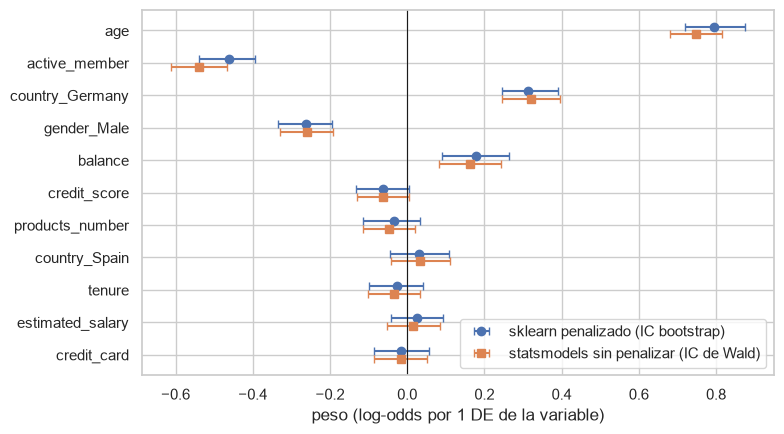

C:\Users\js.rodrigueza1\AppData\Local\Temp\ipykernel_67784\2238644942.py:45: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot([efectos[c] for c in orden_ef], vert=False, tick_labels=orden_ef, whis=(5, 95), showfliers=False)


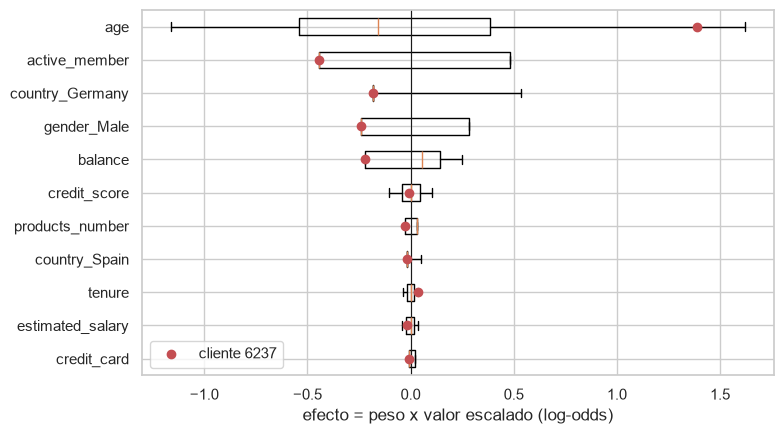

Efecto sobre el log-odds (peso x valor escalado), validación; ancho p5-p95 por variable:
                  mediana     p5    p95  cliente 6237
age                -0.156 -1.162  1.622         1.390
active_member      -0.443 -0.443  0.481        -0.443
country_Germany    -0.183 -0.183  0.536        -0.183
gender_Male        -0.242 -0.242  0.284        -0.242
balance             0.057 -0.219  0.248        -0.219
credit_score       -0.000 -0.104  0.104        -0.008
products_number     0.032 -0.027  0.032        -0.027
country_Spain      -0.017 -0.017  0.052        -0.017
tenure              0.000 -0.037  0.037         0.037
estimated_salary    0.000 -0.039  0.038        -0.019
credit_card        -0.010 -0.010  0.023        -0.010
Cliente 6237: intercepto -0.278 + suma de efectos = -0.020 log-odds; probabilidad de la logística 0.495 (predict_proba: 0.495)

products_number en validación: tasa real frente a la predicción media de cada modelo
                 n (validación)  churn real  prob.

In [50]:
import itertools, math
import statsmodels.api as sm
from sklearn.base import clone

t_ini_s4 = time.time()
lr_final = modelos["Regresión logística"]
print(f"Gradient Boosting final: {modelo_final.n_estimators} árboles, tasa de aprendizaje {modelo_final.learning_rate}, profundidad {modelo_final.max_depth}; "
      f"clientes de validación: {len(X_val)}")

# Pesos con estimación de la varianza: (a) bootstrap del modelo penalizado y (b) Logit sin penalizar de statsmodels (error estándar de Wald)
B_BOOT = 1000
rng_b = np.random.RandomState(0)
coef_boot = np.array([clone(lr_final).fit(X_train_esc.iloc[ib], y_train.iloc[ib]).coef_[0]
                      for ib in (rng_b.randint(0, len(X_train_esc), len(X_train_esc)) for _ in range(B_BOOT))])
sm_fit = sm.Logit(y_train, sm.add_constant(X_train_esc)).fit(disp=0)
ci_sm = sm_fit.conf_int().drop("const")
pesos_lr = pd.DataFrame({"peso (sklearn)": lr_final.coef_[0],
                         "IC95% bootstrap inf.": np.percentile(coef_boot, 2.5, axis=0), "IC95% bootstrap sup.": np.percentile(coef_boot, 97.5, axis=0),
                         "peso (statsmodels)": sm_fit.params.drop("const"), "IC95% Wald inf.": ci_sm[0], "IC95% Wald sup.": ci_sm[1],
                         "odds ratio por 1 DE": np.exp(lr_final.coef_[0])}, index=columnas)
pesos_lr = pesos_lr.reindex(pesos_lr["peso (sklearn)"].abs().sort_values(ascending=False).index)
print(f"Pesos de la regresión logística por 1 DE de entrenamiento (bootstrap: {B_BOOT} remuestras del modelo penalizado, C=0.1, balanced; "
      "statsmodels: Logit sin penalizar ni pesos de clase):")
print(pesos_lr.round(3).to_string())
sig_boot = [c for c in columnas if pesos_lr.loc[c, "IC95% bootstrap inf."] > 0 or pesos_lr.loc[c, "IC95% bootstrap sup."] < 0]
sig_sm = [c for c in columnas if pesos_lr.loc[c, "IC95% Wald inf."] > 0 or pesos_lr.loc[c, "IC95% Wald sup."] < 0]
print("IC95% bootstrap que excluyen 0:", sig_boot)
print("IC95% de Wald que excluyen 0:  ", sig_sm)
print(f"odds ratio por 10 años de age: {np.exp(lr_final.coef_[0][columnas.index('age')] / X_train.std()['age'] * 10):.2f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
pos = np.arange(len(pesos_lr))[::-1]
ax.errorbar(pesos_lr["peso (sklearn)"], pos + 0.12, xerr=[pesos_lr["peso (sklearn)"] - pesos_lr["IC95% bootstrap inf."], pesos_lr["IC95% bootstrap sup."] - pesos_lr["peso (sklearn)"]],
            fmt="o", color="C0", capsize=3, label="sklearn penalizado (IC bootstrap)")
ax.errorbar(pesos_lr["peso (statsmodels)"], pos - 0.12, xerr=[pesos_lr["peso (statsmodels)"] - pesos_lr["IC95% Wald inf."], pesos_lr["IC95% Wald sup."] - pesos_lr["peso (statsmodels)"]],
            fmt="s", color="C1", capsize=3, label="statsmodels sin penalizar (IC de Wald)")
ax.axvline(0, color="k", lw=0.8); ax.set_yticks(pos); ax.set_yticklabels(pesos_lr.index)
ax.set_xlabel("peso (log-odds por 1 DE de la variable)"); ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

# Gráfico de efectos: peso x valor (escalado) de cada variable en los clientes de validación; el punto rojo es un cliente
efectos = X_val_esc * lr_final.coef_[0]
cli_ef = X_val.index[0]
fig, ax = plt.subplots(figsize=(8, 4.5))
orden_ef = pesos_lr.index[::-1]
ax.boxplot([efectos[c] for c in orden_ef], vert=False, tick_labels=orden_ef, whis=(5, 95), showfliers=False)
ax.scatter(efectos.loc[cli_ef, orden_ef], np.arange(1, len(orden_ef) + 1), color="C3", zorder=3, label=f"cliente {cli_ef}")
ax.axvline(0, color="k", lw=0.8); ax.set_xlabel("efecto = peso x valor escalado (log-odds)"); ax.legend(); plt.tight_layout(); plt.show()
print(f"Efecto sobre el log-odds (peso x valor escalado), validación; ancho p5-p95 por variable:")
print(pd.DataFrame({"mediana": efectos.median(), "p5": efectos.quantile(0.05), "p95": efectos.quantile(0.95), f"cliente {cli_ef}": efectos.loc[cli_ef]}
                   ).reindex(pesos_lr.index).round(3).to_string())
lo_cli = lr_final.intercept_[0] + efectos.loc[cli_ef].sum()
print(f"Cliente {cli_ef}: intercepto {lr_final.intercept_[0]:.3f} + suma de efectos = {lo_cli:.3f} log-odds; "
      f"probabilidad de la logística {1 / (1 + np.exp(-lo_cli)):.3f} (predict_proba: {lr_final.predict_proba(X_val_esc.loc[[cli_ef]])[0, 1]:.3f})")

prob_lr_val = lr_final.predict_proba(X_val_esc)[:, 1]
tabla_prod = pd.DataFrame({"n (validación)": X_val.products_number.value_counts().sort_index(),
                           "churn real": y_val.groupby(X_val.products_number).mean(),
                           "prob. media logística": pd.Series(prob_lr_val, index=X_val.index).groupby(X_val.products_number).mean(),
                           "prob. media GB": pd.Series(y_prob_val, index=X_val.index).groupby(X_val.products_number).mean()})
print("\nproducts_number en validación: tasa real frente a la predicción media de cada modelo")
print(tabla_prod.round(3).to_string())

- **Pesos** (bootstrap de 1.000 remuestras): `age` 0,794 (IC 0,720 a 0,876; odds ratio 2,213 por DE, 2,17 por 10 años), `active_member` -0,462 (-0,540 a -0,395), `country_Germany` 0,313 (0,245 a 0,390), `gender_Male` -0,262 (-0,334 a -0,196) y `balance` 0,177 (0,091 a 0,264): sus IC quedan del mismo lado de 0 con bootstrap y con Wald, y la lista `sig_boot` impresa coincide con la de Wald. `credit_score` (-0,064) está en el límite: ambos IC rozan el 0 (bootstrap -0,133 a 0,005; Wald -0,131 a 0,006), con un efecto pequeño. `products_number` (-0,035; -0,113 a 0,033) incluye 0.
- **Efectos:** `age` tiene el mayor rango (p5 -1,162, p95 1,622). El cliente 6237 recibe 1,390 por su edad; con el intercepto (-0,278) la suma es -0,020 log-odds, probabilidad 0,495.
- **`products_number`:**

| Productos | n | Real | Logística | Gradient Boosting |
|---|---|---|---|---|
| 1 | 1.045 | 0,276 | 0,465 | 0,271 |
| 2 | 901 | 0,083 | 0,388 | 0,070 |
| 3 | 48 | 0,792 | 0,503 | 0,804 |
| 4 | 6 | 1,000 | 0,492 | 0,931 |

La logística lineal es casi plana y el Gradient Boosting sigue la U. Con dummies de productos y age², la logística llega a AUC de validación 0,828 contra 0,848 del Gradient Boosting (2.2): la mayor parte de la ventaja de los árboles se asocia con esas dos no linealidades.

### 4.2 Importancia de variables

Reducción de impureza acumulada por variable, calculada en entrenamiento y normalizada a 1. Es un sesgo conocido que favorece las variables continuas (tienen más puntos de corte posibles); aquí no se midió.

Importancia por impureza del Gradient Boosting (entrenamiento, suma 1):
age                 0.370
products_number     0.334
active_member       0.115
balance             0.080
country_Germany     0.041
estimated_salary    0.022
credit_score        0.018
gender_Male         0.014
tenure              0.004
country_Spain       0.001
credit_card         0.001

Variables continuas ['credit_score', 'age', 'balance', 'estimated_salary']: 0.490 de la impureza; binarias y discretas: 0.510
estimated_salary: 0.022; credit_score: 0.018; tenure: 0.004; credit_card: 0.001; country_Spain: 0.001


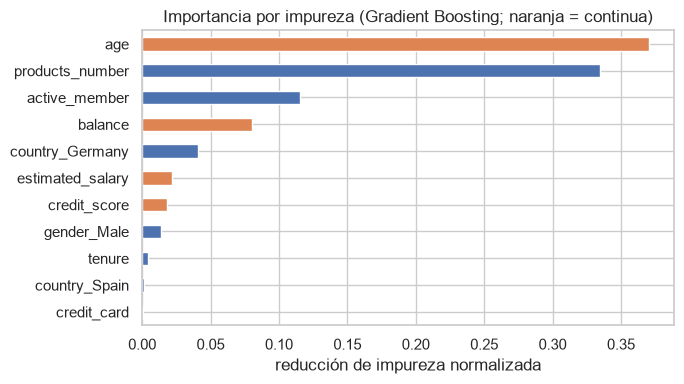

In [51]:
imp_gini = pd.Series(modelo_final.feature_importances_, index=columnas).sort_values(ascending=False)
cont_s4 = ["credit_score", "age", "balance", "estimated_salary"]
print("Importancia por impureza del Gradient Boosting (entrenamiento, suma 1):")
print(imp_gini.round(3).to_string())
print(f"\nVariables continuas {cont_s4}: {imp_gini[cont_s4].sum():.3f} de la impureza; binarias y discretas: {1 - imp_gini[cont_s4].sum():.3f}")
print(f"estimated_salary: {imp_gini['estimated_salary']:.3f}; credit_score: {imp_gini['credit_score']:.3f}; tenure: {imp_gini['tenure']:.3f}; "
      f"credit_card: {imp_gini['credit_card']:.3f}; country_Spain: {imp_gini['country_Spain']:.3f}")
ax = imp_gini.iloc[::-1].plot.barh(figsize=(7, 4), color=["C1" if c in cont_s4 else "C0" for c in imp_gini.index[::-1]],
                                   title="Importancia por impureza (Gradient Boosting; naranja = continua)")
ax.set_xlabel("reducción de impureza normalizada"); plt.tight_layout(); plt.show()

`age` (0,370) y `products_number` (0,334) concentran la mayor parte; siguen `active_member` (0,115), `balance` (0,080) y `country_Germany` (0,041). `estimated_salary` (0,022) y `credit_score` (0,018) superan a `gender_Male` (0,014); las cuatro continuas suman 0,490 y las binarias y discretas 0,510. En 4.4 se compara con Shapley.

### 4.3 ICE, c-ICE y PDP

**ICE:** una curva por cliente (se fija la variable en cada valor). **PDP** (línea roja): promedio de las ICE de los 2.000 clientes de validación. **c-ICE:** cada curva menos su valor en el ancla (primer valor de la rejilla): el cambio, sin importar el nivel de partida. Se dibujan 40 curvas al azar. Las rejillas se cortan entre p1 y p99 de entrenamiento: ICE y PDP combinan valores que pueden no existir (extrapolación) y son sensibles a correlaciones.

Clientes de validación fuera del rango [p1, p99] de entrenamiento (donde la rejilla se corta):
  age: rango de la rejilla 21 a 71; 22 por debajo y 26 por encima (de 2000)
  balance: rango de la rejilla 0 a 186,827; 0 por debajo y 12 por encima (de 2000)
  credit_score: rango de la rejilla 434 a 850; 21 por debajo y 0 por encima (de 2000)
  estimated_salary: rango de la rejilla 1,802 a 198,104; 24 por debajo y 13 por encima (de 2000)
  age mayor o igual que 65: 57 clientes (2.9%); age mayor o igual que 70: 32
  balance: 725 clientes con saldo 0 (36.2%)


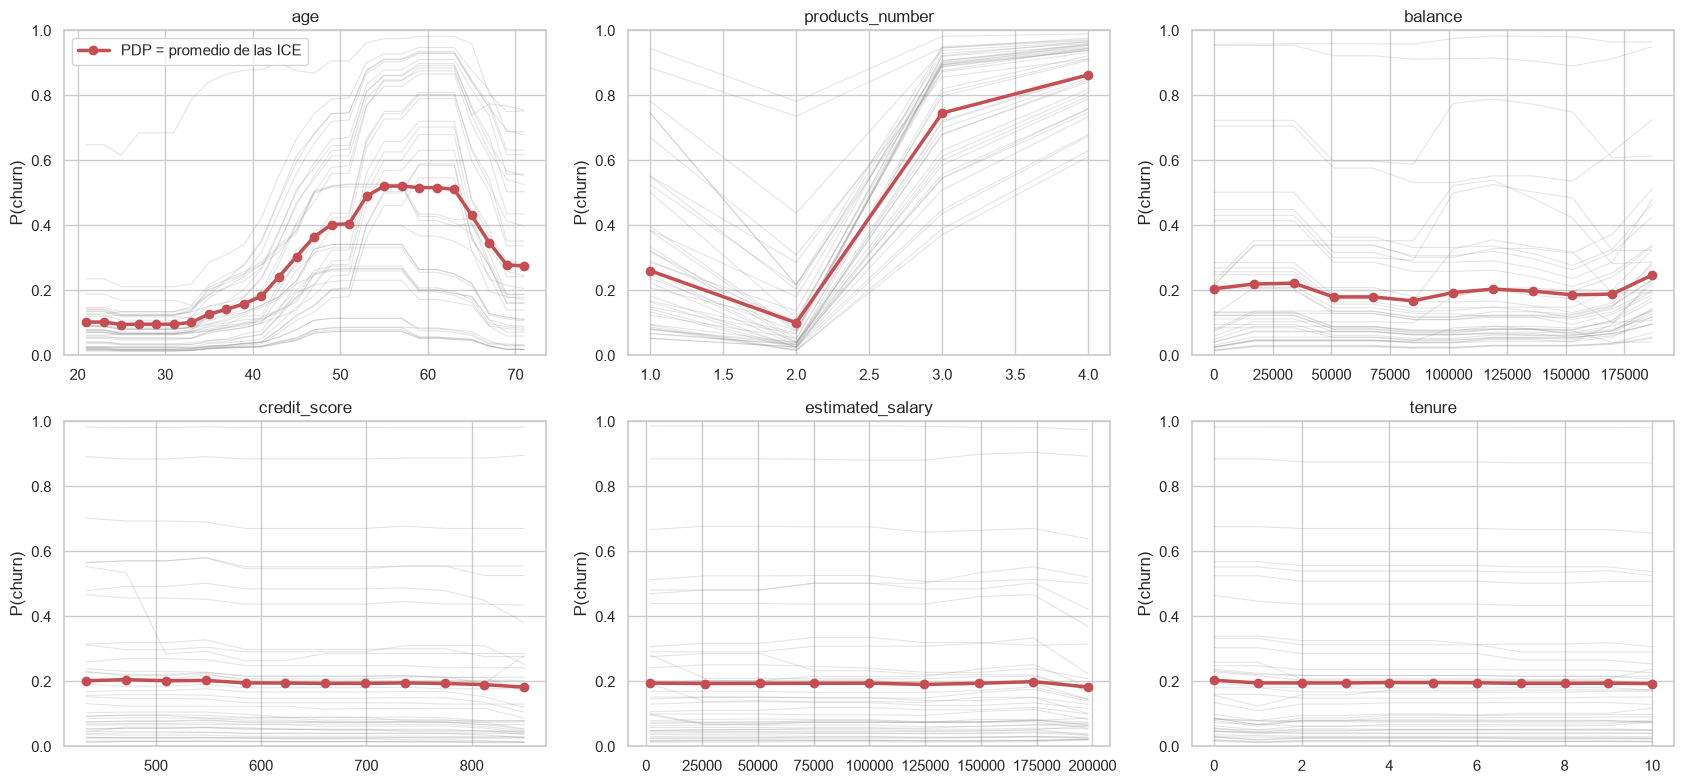

PDP age: 21: 0.103, 23: 0.103, 25: 0.095, 27: 0.096, 29: 0.096, 31: 0.096, 33: 0.102, 35: 0.128, 37: 0.142, 39: 0.159, 41: 0.182, 43: 0.243, 45: 0.304, 47: 0.365, 49: 0.403, 51: 0.405, 53: 0.490, 55: 0.521, 57: 0.521, 59: 0.516, 61: 0.516, 63: 0.511, 65: 0.431, 67: 0.347, 69: 0.279, 71: 0.275
PDP products_number: 1: 0.261, 2: 0.101, 3: 0.746, 4: 0.863
PDP balance: 0: 0.205, 16,984: 0.220, 33,969: 0.223, 50,953: 0.180, 67,937: 0.180, 84,922: 0.168, 101,906: 0.194, 118,890: 0.204, 135,875: 0.198, 152,859: 0.187, 169,843: 0.189, 186,827: 0.247
PDP credit_score: 434: 0.202, 472: 0.206, 510: 0.202, 547: 0.203, 585: 0.196, 623: 0.195, 661: 0.194, 699: 0.194, 737: 0.195, 774: 0.194, 812: 0.190, 850: 0.183
PDP estimated_salary: 1,802: 0.195, 26,339: 0.194, 50,877: 0.194, 75,415: 0.194, 99,953: 0.195, 124,490: 0.191, 149,028: 0.194, 173,566: 0.200, 198,104: 0.183
PDP tenure: 0: 0.204, 1: 0.196, 2: 0.195, 3: 0.195, 4: 0.197, 5: 0.197, 6: 0.196, 7: 0.194, 8: 0.194, 9: 0.195, 10: 0.193
PDP age: mí

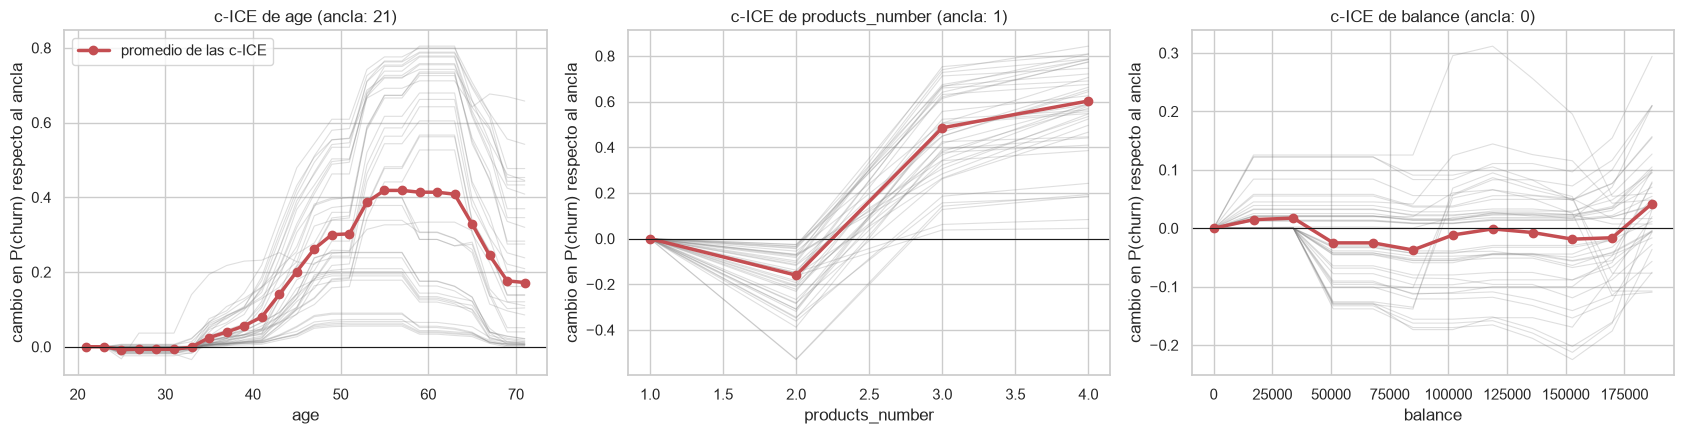

c-ICE de age (ancla 21), en age=55: promedio 0.418, p10 0.090, p90 0.731; clientes con c-ICE mayor que 0: 100.0%
  edad del máximo de la curva de cada cliente: mediana 51, p10 49, p90 59
c-ICE de products_number (ancla 1), en 2 productos: promedio -0.160, p10 -0.321, p90 -0.043
c-ICE de products_number (ancla 1), en 3 productos: promedio 0.485, p10 0.238, p90 0.711
c-ICE de products_number (ancla 1), en 4 productos: promedio 0.603, p10 0.363, p90 0.800
c-ICE de balance (ancla 0), en 186,827: promedio 0.042, p10 -0.055, p90 0.137
  c-ICE de balance en 186,827 por país: Alemania -0.030, resto 0.065


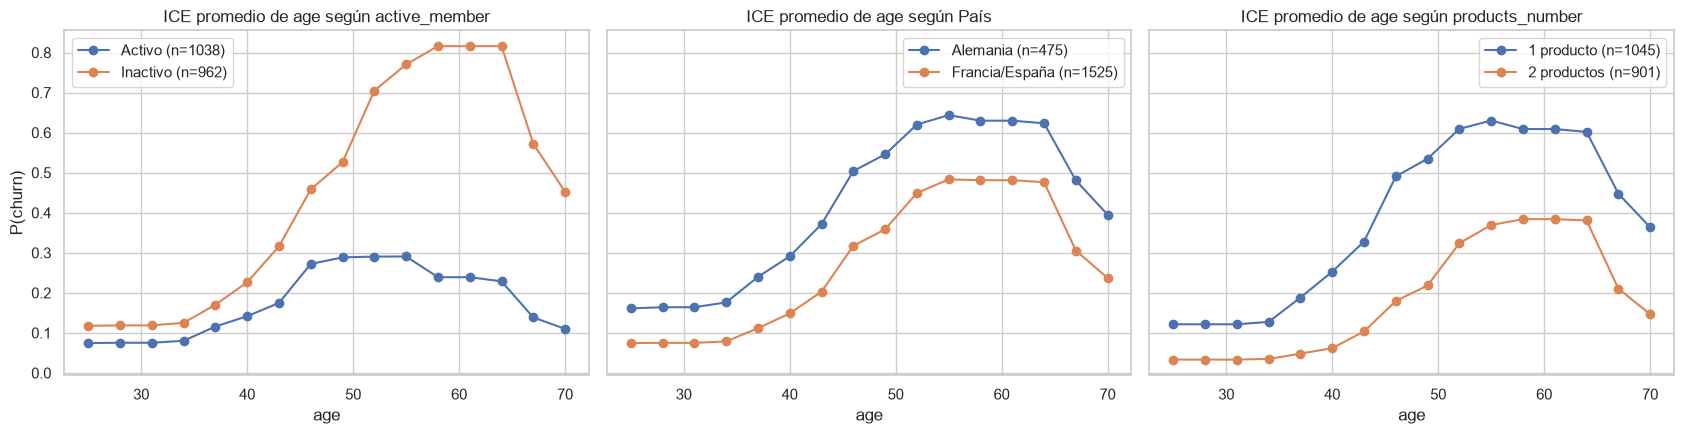

Tamaño de los grupos (validación): Activo: 1038; Inactivo: 962; Alemania: 475; Francia/España: 1525; 1 producto: 1045; 2 productos: 901
ICE promedio de age por grupo (age 25, 37, 49, 58, 70):
   active_member              País                products_number            
          Activo Inactivo Alemania Francia/España      1 producto 2 productos
25         0.074    0.118    0.161          0.075           0.121       0.033
37         0.116    0.170    0.240          0.112           0.188       0.048
49         0.289    0.526    0.546          0.358           0.535       0.218
58         0.239    0.816    0.630          0.481           0.609       0.384
70         0.110    0.452    0.395          0.237           0.363       0.147
Diferencia máxima entre grupos de cada panel (diferencia de probabilidad) y la age en que ocurre:
  active_member: 0.587 en age=64
  País: 0.187 en age=49
  products_number: 0.317 en age=49


In [52]:
def curvas_ice(modelo, variable, valores, datos=X_val):
    """ICE: una curva por cliente de `datos`; se fija `variable` en cada valor y el resto queda como está. Devuelve (clientes x valores)."""
    def prob(Xraw):
        return modelo.predict_proba(pd.DataFrame(escalador.transform(Xraw), columns=columnas, index=Xraw.index))[:, 1]
    return np.column_stack([prob(datos.assign(**{variable: v})) for v in valores])

q01, q99 = X_train.quantile(0.01), X_train.quantile(0.99)
rejillas = {"age": np.arange(np.ceil(q01["age"]), q99["age"] + 1, 2),
            "products_number": np.array([1, 2, 3, 4]),
            "balance": np.linspace(0, q99["balance"], 12),
            "credit_score": np.linspace(q01["credit_score"], 850, 12),
            "estimated_salary": np.linspace(q01["estimated_salary"], q99["estimated_salary"], 9),
            "tenure": np.arange(0, 11)}
print("Clientes de validación fuera del rango [p1, p99] de entrenamiento (donde la rejilla se corta):")
for v in ["age", "balance", "credit_score", "estimated_salary"]:
    print(f"  {v}: rango de la rejilla {rejillas[v].min():,.0f} a {rejillas[v].max():,.0f}; "
          f"{int((X_val[v] < rejillas[v].min()).sum())} por debajo y {int((X_val[v] > rejillas[v].max()).sum())} por encima (de {len(X_val)})")
print(f"  age mayor o igual que 65: {int((X_val.age >= 65).sum())} clientes ({(X_val.age >= 65).mean():.1%}); age mayor o igual que 70: {int((X_val.age >= 70).sum())}")
print(f"  balance: {int((X_val.balance == 0).sum())} clientes con saldo 0 ({(X_val.balance == 0).mean():.1%})")

ICE = {v: curvas_ice(modelo_final, v, val) for v, val in rejillas.items()}     # curvas de los 2.000 clientes de validación
pdps = {v: pd.Series(ICE[v].mean(axis=0), index=np.round(rejillas[v], 0)) for v in rejillas}   # PDP = promedio de las ICE
muestra_ice = np.random.RandomState(0).choice(len(X_val), 40, replace=False)                    # 40 curvas dibujadas

fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, (variable, valores) in zip(axes.flat, rejillas.items()):
    ax.plot(valores, ICE[variable][muestra_ice].T, color="grey", alpha=0.2, lw=0.8)
    ax.plot(valores, ICE[variable].mean(axis=0), color="C3", lw=2.5, marker="o", label="PDP = promedio de las ICE")
    ax.set_title(variable); ax.set_ylabel("P(churn)"); ax.set_ylim(0, 1)
axes[0, 0].legend()
plt.tight_layout()
plt.show()
for v, s in pdps.items():
    print(f"PDP {v}: " + ", ".join(f"{i:,.0f}: {x:.3f}" for i, x in s.items()))
print(f"PDP age: mínimo {pdps['age'].min():.3f} en age={pdps['age'].idxmin():.0f}, máximo {pdps['age'].max():.3f} en age={pdps['age'].idxmax():.0f}")
print(f"PDP salary: rango {pdps['estimated_salary'].max() - pdps['estimated_salary'].min():.3f}; PDP tenure: rango {pdps['tenure'].max() - pdps['tenure'].min():.3f}; "
      f"PDP credit_score: rango {pdps['credit_score'].max() - pdps['credit_score'].min():.3f}; PDP balance: rango {pdps['balance'].max() - pdps['balance'].min():.3f}")

# ICE centradas (c-ICE): cada curva menos su valor en el punto de anclaje (el primer valor de la rejilla)
cice = {v: ICE[v] - ICE[v][:, [0]] for v in ["age", "products_number", "balance"]}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, v in zip(axes, cice):
    ax.plot(rejillas[v], cice[v][muestra_ice].T, color="grey", alpha=0.25, lw=0.8)
    ax.plot(rejillas[v], cice[v].mean(axis=0), color="C3", lw=2.5, marker="o", label="promedio de las c-ICE")
    ax.axhline(0, color="k", lw=0.8); ax.set_title(f"c-ICE de {v} (ancla: {rejillas[v][0]:,.0f})")
    ax.set_xlabel(v); ax.set_ylabel("cambio en P(churn) respecto al ancla")
axes[0].legend(); plt.tight_layout(); plt.show()
ia55, ia25 = list(rejillas["age"]).index(55), list(rejillas["age"]).index(25)
c55 = cice["age"][:, ia55]
print(f"c-ICE de age (ancla {rejillas['age'][0]:.0f}), en age=55: promedio {c55.mean():.3f}, p10 {np.percentile(c55, 10):.3f}, p90 {np.percentile(c55, 90):.3f}; "
      f"clientes con c-ICE mayor que 0: {(c55 > 0).mean():.1%}")
pico = cice["age"].argmax(axis=1)
print(f"  edad del máximo de la curva de cada cliente: mediana {np.median(rejillas['age'][pico]):.0f}, p10 {np.percentile(rejillas['age'][pico], 10):.0f}, p90 {np.percentile(rejillas['age'][pico], 90):.0f}")
for k in [2, 3, 4]:
    ck = cice["products_number"][:, k - 1]
    print(f"c-ICE de products_number (ancla 1), en {k} productos: promedio {ck.mean():.3f}, p10 {np.percentile(ck, 10):.3f}, p90 {np.percentile(ck, 90):.3f}")
cb = cice["balance"][:, -1]
print(f"c-ICE de balance (ancla 0), en {rejillas['balance'][-1]:,.0f}: promedio {cb.mean():.3f}, p10 {np.percentile(cb, 10):.3f}, p90 {np.percentile(cb, 90):.3f}")
cb_a = cice["balance"][X_val.country_Germany.values == 1, -1].mean(); cb_f = cice["balance"][X_val.country_Germany.values == 0, -1].mean()
print(f"  c-ICE de balance en {rejillas['balance'][-1]:,.0f} por país: Alemania {cb_a:.3f}, resto {cb_f:.3f}")

# ICE promedio por subgrupos (interacciones): PDP de age dentro de cada grupo
edades = np.arange(25, 71, 3)
ice_edad = curvas_ice(modelo_final, "age", edades)
grupos_age = {"active_member": {"Activo": X_val.active_member == 1, "Inactivo": X_val.active_member == 0},
              "País": {"Alemania": X_val.country_Germany == 1, "Francia/España": X_val.country_Germany == 0},
              "products_number": {"1 producto": X_val.products_number == 1, "2 productos": X_val.products_number == 2}}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
pdp_grupos = {}
for ax, (titulo, grupos) in zip(axes, grupos_age.items()):
    for nombre_g, msk in grupos.items():
        pdp_grupos[(titulo, nombre_g)] = pd.Series(ice_edad[msk.values].mean(axis=0), index=edades)
        ax.plot(edades, pdp_grupos[(titulo, nombre_g)], marker="o", label=f"{nombre_g} (n={msk.sum()})")
    ax.set_title(f"ICE promedio de age según {titulo}"); ax.set_xlabel("age"); ax.legend()
axes[0].set_ylabel("P(churn)")
plt.tight_layout()
plt.show()
print("Tamaño de los grupos (validación): " + "; ".join(f"{k[1]}: {int(m_.sum())}" for k, m_ in {(t_, g_): m_ for t_, gs in grupos_age.items() for g_, m_ in gs.items()}.items()))
print("ICE promedio de age por grupo (age 25, 37, 49, 58, 70):")
print(pd.DataFrame(pdp_grupos).loc[[25, 37, 49, 58, 70]].round(3).to_string())
print("Diferencia máxima entre grupos de cada panel (diferencia de probabilidad) y la age en que ocurre:")
for titulo, grupos in grupos_age.items():
    a, b = [pdp_grupos[(titulo, g)] for g in grupos]
    print(f"  {titulo}: {(a - b).abs().max():.3f} en age={(a - b).abs().idxmax()}")

**PDP.**

- **`age`:** 0,095 a los 25 años, máximo de 0,521 a los 55 (meseta de 0,516 a 0,521 entre los 57 y 61), 0,431 a los 65 y 0,275 a los 71. La bajada se apoya en 57 clientes (2,9 %) de 65 años o más.
- **`products_number`:** 0,261 con 1 producto, 0,101 con 2, 0,746 con 3 y 0,863 con 4 (48 y 6 clientes).
- **`balance`:** entre 0,168 y 0,247 (rango 0,080), sin tendencia clara; 725 clientes (36,2 %) tienen saldo 0.
- **`credit_score`, `estimated_salary` y `tenure`:** casi planos (rangos 0,023, 0,017 y 0,010).

**c-ICE.**

- **`age` (ancla 21):** a los 55 el cambio promedio es +0,418 (p10 0,090; p90 0,731) y la curva de todos los clientes sube (100,0 % mayor que 0). El máximo de cada cliente está en una mediana de 51 años (p10 49; p90 59): misma forma, distinta altura.
- **`products_number` (ancla 1):** 2 productos -0,160; 3 productos +0,485 (p10 0,238; p90 0,711); 4 productos +0,603.
- **`balance` (ancla 0):** en 186.827 el cambio promedio es +0,042, pero es -0,030 en Alemania y +0,065 en el resto: el promedio esconde un efecto que depende del país.

**`age` por subgrupos** (ICE promedio):

- **`active_member`** (activos 1.038, inactivos 962): a los 58 años 0,816 (inactivos) frente a 0,239 (activos); la mayor diferencia es 0,587, a los 64 años.
- **País** (Alemania 475, Francia/España 1.525): a los 49 años 0,546 frente a 0,358.
- **`products_number`** (1 producto: 1.045; 2: 901): a los 49 años 0,535 frente a 0,218.

Es una interacción que ninguna de las dos logísticas representa, porque no incluyen términos de interacción.

### 4.4 SHAP

`shap.TreeExplainer` (algoritmo Tree SHAP, sin datos de fondo: usa la cobertura de los árboles) en log-odds: **valor base + suma de contribuciones = log-odds del cliente**. Se aplica a los 2.000 clientes de validación. En el **diagrama de enjambre** cada punto es un cliente; la distancia a 0 es el impacto en el log-odds; rojo es valor alto de la variable y azul, bajo (`shap` colorea entre los percentiles 5 y 95).

C:\Users\js.rodrigueza1\AppData\Local\anaconda3\envs\proyecto\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


shap 0.54.1: TreeExplainer sobre 2000 clientes en 0.1 s
Valor base (log-odds medio sobre el entrenamiento del modelo): -1.8576 (probabilidad 0.135)
Aditividad en los 2000 clientes (base + suma de contribuciones frente a decision_function): diferencia absoluta máxima 7.11e-15
Cliente 6237: base + suma = -2.353725; log-odds del modelo = -2.353725
                  |contribución| media (log-odds)  corr(valor, contribución)   mín.   máx.  posición Shapley  posición impureza
products_number                             0.784                     -0.387 -1.777  4.350                 1                  2
age                                         0.724                      0.751 -1.097  2.736                 2                  1
active_member                               0.366                     -0.904 -0.989  1.085                 3                  3
gender_Male                                 0.204                     -0.976 -0.408  0.409                 4                  8
country_Germa

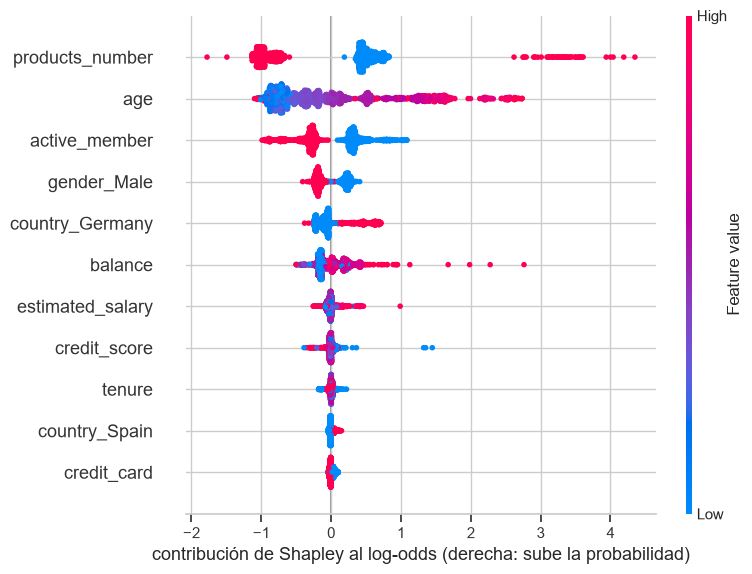

Percentil 95 de products_number en validación: 2 (shap colorea entre los percentiles 5 y 95 de cada variable)
Contribución media de products_number: 1: +0.52 (n=1045), 2: -0.93 (n=901), 3: +3.32 (n=54); el nivel 3 agrupa 3 y 4 productos
Contribución media de age por banda: <30: -0.76 (n=346), 30-39: -0.52 (n=885), 40-49: +0.54 (n=473), 50-59: +1.80 (n=187), 60+: +0.78 (n=109)
active_member: valor 1 -0.36 (n=1038), valor 0 +0.37 (n=962)
country_Germany: valor 1 +0.46 (n=475), valor 0 -0.12 (n=1525)
gender_Male: valor 1 -0.19 (n=1124), valor 0 +0.22 (n=876)
balance: saldo 0 -0.07 (n=725), saldo mayor que 0 +0.06 (n=1275); correlación de balance con country_Germany 0.386


In [53]:
import shap
d_var = len(columnas)
explicador = shap.TreeExplainer(modelo_final)       # salida en log-odds (margen), valores de Shapley exactos para árboles
t0 = time.time()
sh_val = explicador(X_val_esc)                       # 2.000 clientes de validación
SHAP_V = pd.DataFrame(sh_val.values, index=X_val.index, columns=columnas)
base_shap = float(explicador.expected_value[0]) if np.ndim(explicador.expected_value) else float(explicador.expected_value)
print(f"shap {shap.__version__}: TreeExplainer sobre {len(X_val)} clientes en {time.time() - t0:.1f} s")
print(f"Valor base (log-odds medio sobre el entrenamiento del modelo): {base_shap:.4f} (probabilidad {1 / (1 + np.exp(-base_shap)):.3f})")
lo_modelo = modelo_final.decision_function(X_val_esc)
dif_aditiv = np.abs(base_shap + SHAP_V.sum(axis=1).values - lo_modelo)
print(f"Aditividad en los {len(X_val)} clientes (base + suma de contribuciones frente a decision_function): diferencia absoluta máxima {dif_aditiv.max():.2e}")
c0 = X_val.index[0]
print(f"Cliente {c0}: base + suma = {base_shap + SHAP_V.loc[c0].sum():.6f}; log-odds del modelo = {lo_modelo[0]:.6f}")

resumen_shap = pd.DataFrame({"|contribución| media (log-odds)": SHAP_V.abs().mean(),
                             "corr(valor, contribución)": [np.corrcoef(X_val[c], SHAP_V[c])[0, 1] for c in columnas],
                             "mín.": SHAP_V.min(), "máx.": SHAP_V.max()}).sort_values("|contribución| media (log-odds)", ascending=False)
resumen_shap["posición Shapley"] = np.arange(1, d_var + 1)
resumen_shap["posición impureza"] = [list(imp_gini.index).index(c) + 1 for c in resumen_shap.index]
print(resumen_shap.round(3).to_string())
rho_sh_imp = pd.Series(np.arange(d_var), index=resumen_shap.index).corr(pd.Series([list(imp_gini.index).index(c) for c in resumen_shap.index], index=resumen_shap.index), method="spearman")
print(f"Correlación de Spearman entre el ranking de Shapley y el de impureza: {rho_sh_imp:.3f}")

# Diagrama de enjambre (rojo: valor alto de la variable; azul: bajo). Se muestran los valores originales de cada variable.
expl_raw = shap.Explanation(values=sh_val.values, base_values=sh_val.base_values, data=X_val.values, feature_names=list(columnas))
plt.figure()
shap.plots.beeswarm(expl_raw, max_display=d_var, show=False)
plt.xlabel("contribución de Shapley al log-odds (derecha: sube la probabilidad)")
plt.tight_layout(); plt.show()

print(f"Percentil 95 de products_number en validación: {X_val.products_number.quantile(0.95):.0f} (shap colorea entre los percentiles 5 y 95 de cada variable)")
pn_sw = X_val.products_number.clip(upper=3)
print("Contribución media de products_number: " + ", ".join(f"{k}: {SHAP_V.loc[pn_sw == k, 'products_number'].mean():+.2f} (n={int((pn_sw == k).sum())})" for k in [1, 2, 3]) + "; el nivel 3 agrupa 3 y 4 productos")
ed_sw = pd.cut(X_val.age, [0, 29, 39, 49, 59, 120], labels=["<30", "30-39", "40-49", "50-59", "60+"])
print("Contribución media de age por banda: " + ", ".join(f"{k}: {v:+.2f} (n={int((ed_sw == k).sum())})" for k, v in SHAP_V["age"].groupby(ed_sw, observed=True).mean().items()))
for c in ["active_member", "country_Germany", "gender_Male"]:
    g1, g0 = SHAP_V.loc[X_val[c] == 1, c], SHAP_V.loc[X_val[c] == 0, c]
    print(f"{c}: valor 1 {g1.mean():+.2f} (n={len(g1)}), valor 0 {g0.mean():+.2f} (n={len(g0)})")
bal0 = X_val.balance == 0
print(f"balance: saldo 0 {SHAP_V.loc[bal0, 'balance'].mean():+.2f} (n={int(bal0.sum())}), saldo mayor que 0 {SHAP_V.loc[~bal0, 'balance'].mean():+.2f} (n={int((~bal0).sum())}); "
      f"correlación de balance con country_Germany {X_val.balance.corr(X_val.country_Germany):.3f}")

La aditividad se cumple en los 2.000 clientes (diferencia máxima 7,11e-15); el valor base es -1,8576 (probabilidad 0,135).

- **Ranking por |contribución| media (log-odds):** `products_number` (0,784), `age` (0,724), `active_member` (0,366), `gender_Male` (0,204), `country_Germany` (0,200), `balance` (0,164); el resto, 0,046 o menos. Las tres primeras son las mismas que en la impureza, con otro orden: `age` es primera allá (Spearman 0,891 entre los dos rankings). Difiere `gender_Male`: posición 4 en Shapley y 8 en impureza (0,014); `balance` es 6 y 4.
- **`products_number`:** 1 producto +0,52 (1.045 clientes), 2 productos -0,93 (901), 3 o 4 productos +3,32 (54); la correlación valor-contribución es solo -0,387 por la forma de U. Con el percentil 95 en 2, el rojo incluye 2 productos.
- **`age`:** -0,76 (menos de 30), -0,52 (30 a 39), +0,54 (40 a 49), +1,80 (50 a 59) y +0,78 (60 o más).
- **Binarias:** `active_member` = 0 suma +0,37 y = 1 resta 0,36; `country_Germany` = 1 suma +0,46 (475 clientes); `gender_Male` = 1 resta 0,19 y = 0 suma +0,22 (mayor para mujeres).
- **`balance`:** saldo 0 -0,07 y saldo positivo +0,06, con puntos hasta 2,762; su correlación con `country_Germany` es 0,386, así que parte puede compartirse con el país (no probado).

### 4.5 Clientes para explicar

Con `umbral_negocio` (3.7) se contacta si la probabilidad es mayor o igual. Seis clientes con regla fija, sin elegirlos a mano: el verdadero positivo (VP) de mayor probabilidad y el VP más cercano al umbral; el falso positivo (FP) de mayor probabilidad y el FP más cercano a la mediana de los FP; el falso negativo (FN) de menor probabilidad y el FN más cercano al umbral.

In [54]:
p_val = pd.Series(y_prob_val, index=X_val.index)
vp_n, fp_n, fn_n, vn_n = conteos(y_val, y_prob_val, umbral_negocio)
print(f"Con umbral_negocio = {umbral_negocio} en validación: VP={vp_n}, FP={fp_n}, FN={fn_n}, VN={vn_n} (contactados: {vp_n + fp_n})")
fp_pos = p_val[(y_val == 0) & (p_val >= umbral_negocio)]
candidatos = {
    "VP claro": p_val[y_val == 1].idxmax(),
    "VP en el borde": (p_val[(y_val == 1) & (p_val >= umbral_negocio)] - umbral_negocio).idxmin(),
    "FP con perfil de riesgo": p_val[y_val == 0].idxmax(),
    "FP típico": (fp_pos - fp_pos.median()).abs().idxmin(),
    "FN sin señales": p_val[y_val == 1].idxmin(),
    "FN en el borde": (umbral_negocio - p_val[(y_val == 1) & (p_val < umbral_negocio)]).idxmin(),
}
print(f"Mediana de la probabilidad de los FP: {fp_pos.median():.3f}")
vars_perfil = ["age", "products_number", "active_member", "country_Germany", "gender_Male", "balance", "credit_score"]
casos = X_val.loc[list(candidatos.values()), vars_perfil].copy()
casos["balance"] = casos["balance"].round(0)
casos.insert(0, "tipo", list(candidatos.keys()))
casos["prob_churn"] = p_val[casos.index].round(3)
casos["churn_real"] = y_val[casos.index]
casos["clasif."] = ["VP" if (pr >= umbral_negocio and yr == 1) else "FP" if pr >= umbral_negocio else "FN" if yr == 1 else "VN"
                    for pr, yr in zip(casos.prob_churn, casos.churn_real)]
print(casos.to_string())

Con umbral_negocio = 0.2 en validación: VP=293, FP=305, FN=114, VN=1288 (contactados: 598)
Mediana de la probabilidad de los FP: 0.297
                         tipo   age  products_number  active_member  country_Germany  gender_Male   balance  credit_score  prob_churn  churn_real clasif.
3027                 VP claro  61.0                3              0                0            0   62055.0         675.0       0.987           1      VP
4130           VP en el borde  28.0                1              0                1            1  126315.0         467.0       0.201           1      VP
9972  FP con perfil de riesgo  53.0                1              0                1            0  123805.0         711.0       0.936           0      FP
119                 FP típico  36.0                1              0                0            0       0.0         687.0       0.297           0      FP
105            FN sin señales  32.0                2              1                0           

Con `umbral_negocio` = 0,2 hay 293 VP, 305 FP, 114 FN y 1.288 VN (598 contactados); la mediana de probabilidad de los FP es 0,297.

| Caso | Tipo | p | Perfil |
|---|---|---|---|
| 3027 | VP claro | 0,987 | 61 años, 3 productos, inactivo, saldo 62.055 |
| 4130 | VP en el borde | 0,201 | 28 años, 1 producto, inactivo, Alemania, hombre, saldo 126.315 |
| 9972 | FP con perfil de riesgo | 0,936 | 53 años, 1 producto, inactiva, Alemania, mujer, saldo 123.805 |
| 119 | FP típico | 0,297 | 36 años, 1 producto, inactivo, saldo 0 |
| 105 | FN sin señales | 0,021 | 32 años, 2 productos, activo, saldo 0 |
| 5813 | FN en el borde | 0,199 | 32 años, 1 producto, inactivo, Alemania, hombre, saldo 130.628 |

### 4.6 SHAP por cliente

Una cascada por caso (`shap.plots.waterfall`): parte del valor base E[f(X)] y cada barra suma (rojo) o resta (azul) log-odds hasta f(x), el log-odds del cliente. La tabla muestra las contribuciones de valor absoluto mayor que 0,15 en algún caso.

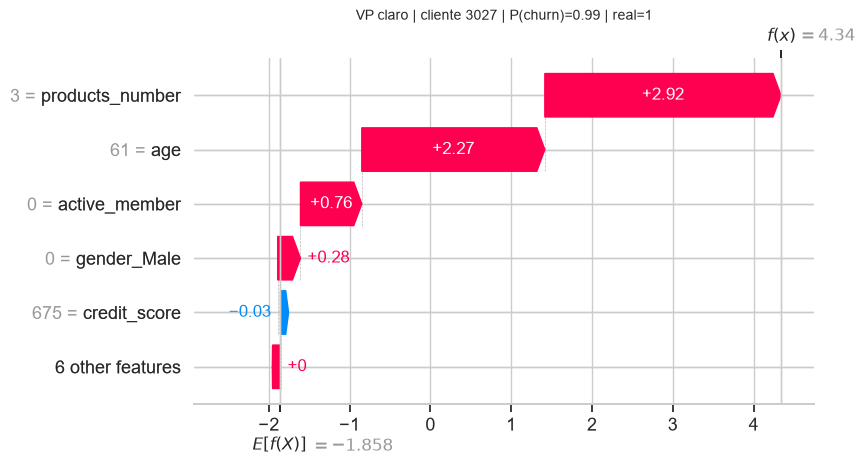

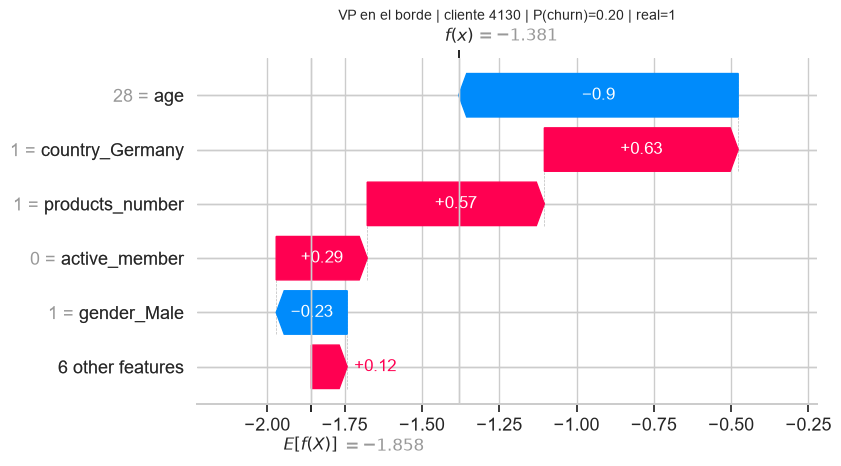

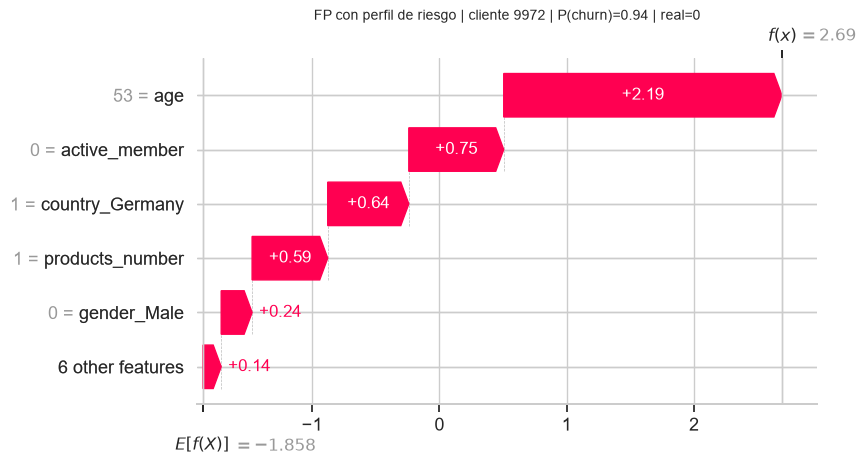

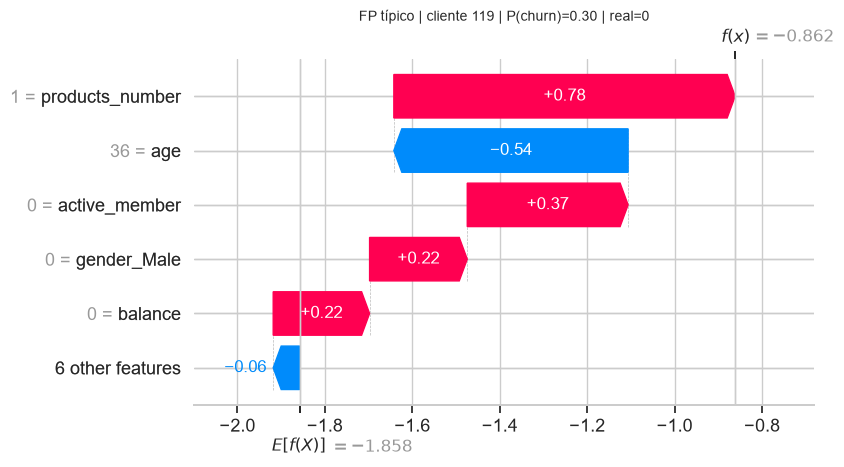

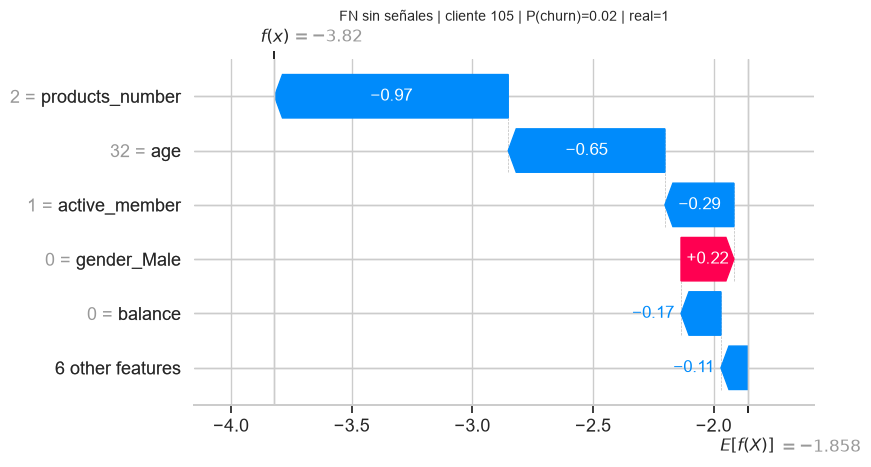

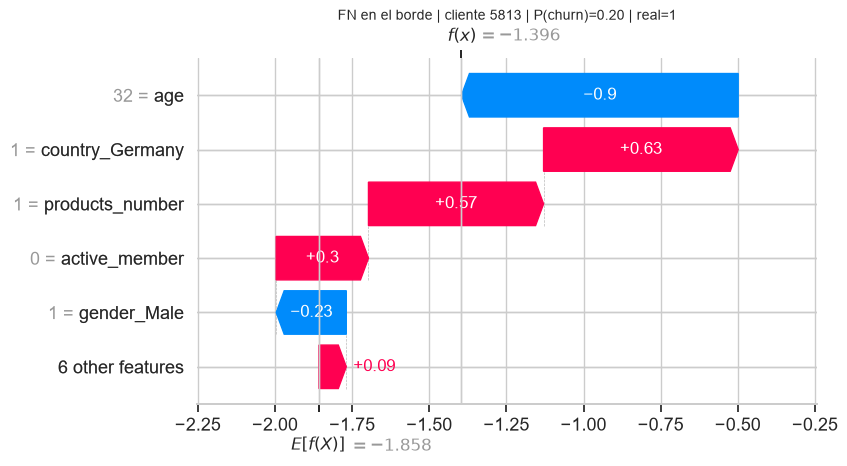

Valor base: -1.858 log-odds (probabilidad 0.135)
Contribuciones de Shapley por caso (log-odds):
                          age  balance  products_number  active_member  country_Germany  gender_Male
VP claro                 2.27    -0.00             2.92           0.76            -0.00         0.28
VP en el borde          -0.90     0.21             0.57           0.29             0.63        -0.23
FP con perfil de riesgo  2.19     0.18             0.59           0.75             0.64         0.24
FP típico               -0.54     0.22             0.78           0.37            -0.10         0.22
FN sin señales          -0.65    -0.17            -0.97          -0.29            -0.05         0.22
FN en el borde          -0.90     0.21             0.57           0.30             0.63        -0.23

Suma de contribuciones y comprobación de aditividad por caso:
  VP claro (índice 3027): base + suma = 4.3396; log-odds = 4.3396; p = 0.987
  VP en el borde (índice 4130): base + suma = -1.3811; lo

In [55]:
expl_casos = {}
for tipo, i in candidatos.items():
    k = list(X_val.index).index(i)
    expl_casos[tipo] = shap.Explanation(values=sh_val.values[k], base_values=sh_val.base_values[k], data=X_val.loc[i].values, feature_names=list(columnas))
    shap.plots.waterfall(expl_casos[tipo], max_display=6, show=False)
    plt.title(f"{tipo} | cliente {i} | P(churn)={p_val[i]:.2f} | real={y_val[i]}", fontsize=10)
    plt.show()
expl = SHAP_V.loc[list(candidatos.values())]; expl.index = list(candidatos.keys())
print(f"Valor base: {base_shap:.3f} log-odds (probabilidad {1 / (1 + np.exp(-base_shap)):.3f})")
print("Contribuciones de Shapley por caso (log-odds):")
print(expl.loc[:, expl.abs().max() > 0.15].round(2).to_string())
print("\nSuma de contribuciones y comprobación de aditividad por caso:")
for tipo, i in candidatos.items():
    lo = modelo_final.decision_function(X_val_esc.loc[[i]])[0]
    print(f"  {tipo} (índice {i}): base + suma = {base_shap + expl.loc[tipo].sum():.4f}; log-odds = {lo:.4f}; p = {p_val[i]:.3f}")
print("\nTres mayores contribuciones por caso:")
for tipo, i in candidatos.items():
    s = expl.loc[tipo]; top3 = s.reindex(s.abs().sort_values(ascending=False).index[:3])
    print(f"  {tipo} (índice {i}): " + ", ".join(f"{c}={X_val.loc[i, c]:,.0f} ({v:+.2f})" for c, v in top3.items()))

Valor base -1,858 log-odds (probabilidad 0,135). La aditividad se cumple en los seis casos.

- **3027 (VP claro):** `products_number` = 3 (+2,92), `age` = 61 (+2,27), `active_member` = 0 (+0,76).
- **4130 (VP en el borde):** `age` = 28 resta 0,90, pero `country_Germany` (+0,63), `products_number` = 1 (+0,57) y `active_member` = 0 (+0,29) lo dejan justo sobre el umbral.
- **9972 (FP, p = 0,936):** `age` = 53 (+2,19), `active_member` = 0 (+0,75), `country_Germany` (+0,64).
- **119 (FP típico):** `products_number` = 1 (+0,78) y `active_member` = 0 (+0,37) compensan `age` = 36 (-0,54).
- **105 (FN sin señales):** `products_number` = 2 (-0,97), `age` = 32 (-0,65), `active_member` = 1 (-0,29).
- **5813 (FN en el borde):** `age` = 32 (-0,90), `country_Germany` (+0,63), `products_number` = 1 (+0,57): casi la copia de 4130.

### 4.7 LIME

`lime.LimeTabularExplainer` con el entrenamiento escalado como referencia (semilla fija, variables sin discretizar): 5.000 perturbaciones por caso, kernel exponencial y un sustituto lineal ponderado sobre la probabilidad del modelo. Con `discretize_continuous=False` y el muestreo por defecto, las perturbaciones salen de una normal alrededor de la media del entrenamiento (no del cliente) y también las variables binarias toman valores continuos que no existen; el kernel es lo único que da localidad. La librería ajusta una regresión Ridge, no el Lasso de la clase. Para comparar con Shapley (log-odds) se usa peso por valor estandarizado del cliente y se compara el orden (Spearman), no la magnitud. Fidelidad: R² ponderado. Como la clase advierte que LIME es inestable, se repite con otra semilla y con otro ancho de kernel.

In [56]:
from lime.lime_tabular import LimeTabularExplainer
from importlib.metadata import version as version_pkg

def explicar_lime(semilla=42, ancho=None, n_muestras=5000):
    """LIME tabular sobre los datos escalados de entrenamiento; devuelve contribuciones por variable (peso x valor estandarizado), R2 ponderado y probabilidad del sustituto."""
    exp_l = LimeTabularExplainer(X_train_esc.values, feature_names=list(columnas), class_names=["se queda", "abandona"], mode="classification",
                                 discretize_continuous=False, kernel_width=ancho, random_state=semilla)
    salida = {}
    for tipo, i in candidatos.items():
        e = exp_l.explain_instance(X_val_esc.loc[i].values, lambda Z: modelo_final.predict_proba(pd.DataFrame(Z, columns=columnas)),
                                   num_features=d_var, num_samples=n_muestras, labels=(1,))
        w = dict(e.as_list(label=1))
        z = (X_val_esc.loc[i].values - exp_l.scaler.mean_) / exp_l.scaler.scale_
        salida[tipo] = (pd.Series({c: w[c] * zz for c, zz in zip(columnas, z)}), e.score, e.local_pred[0])
    return salida

t0 = time.time()
lime_a = explicar_lime()
print(f"LIME (lime {version_pkg('lime')}): 5000 perturbaciones por caso, kernel por defecto, semilla 42, en {time.time() - t0:.1f} s")
def top3(s): return list(s.reindex(s.abs().sort_values(ascending=False).index[:3]).index)
filas_l = []
for tipo, i in candidatos.items():
    c_l, r2, pl = lime_a[tipo]; c_s = expl.loc[tipo]
    comunes = set(top3(c_l)) & set(top3(c_s))
    signo = np.mean([np.sign(c_l[c]) == np.sign(c_s[c]) for c in c_s.abs().sort_values(ascending=False).index[:5]])
    filas_l.append((tipo, i, r2, pl, p_val[i], len(comunes), signo, c_l.corr(c_s, method="spearman"), ", ".join(top3(c_l)), ", ".join(top3(c_s))))
tabla_l = pd.DataFrame(filas_l, columns=["tipo", "cliente", "R2 ponderado", "p del sustituto", "p del modelo", "top-3 en común", "signos iguales (top-5 Shapley)", "Spearman", "top-3 LIME", "top-3 Shapley"])
print(tabla_l.round(3).to_string(index=False))

# Inestabilidad: otra semilla, y otro ancho de kernel (la mitad del por defecto)
ancho_def = np.sqrt(d_var) * 0.75
lime_b = explicar_lime(semilla=7)
lime_c = explicar_lime(ancho=ancho_def / 2)
print(f"\nEstabilidad de LIME: ancho por defecto {ancho_def:.2f}; segunda corrida con semilla 7 y tercera con ancho {ancho_def / 2:.2f}")
filas_e = []
for tipo, i in candidatos.items():
    a, b, c = lime_a[tipo][0], lime_b[tipo][0], lime_c[tipo][0]
    filas_e.append((tipo, i, len(set(top3(a)) & set(top3(b))), a.corr(b, method="spearman"), lime_b[tipo][1],
                    len(set(top3(a)) & set(top3(c))), a.corr(c, method="spearman"), lime_c[tipo][1]))
print(pd.DataFrame(filas_e, columns=["tipo", "cliente", "top-3 en común (otra semilla)", "Spearman (otra semilla)", "R2 (otra semilla)",
                                     "top-3 en común (otro ancho)", "Spearman (otro ancho)", "R2 (otro ancho)"]).round(3).to_string(index=False))
print("Top-3 por corrida, cliente " + str(candidatos["FP con perfil de riesgo"]) + ":", top3(lime_a["FP con perfil de riesgo"][0]), top3(lime_b["FP con perfil de riesgo"][0]), top3(lime_c["FP con perfil de riesgo"][0]))

LIME (lime 0.2.0.1): 5000 perturbaciones por caso, kernel por defecto, semilla 42, en 0.1 s
                   tipo  cliente  R2 ponderado  p del sustituto  p del modelo  top-3 en común  signos iguales (top-5 Shapley)  Spearman                          top-3 LIME                         top-3 Shapley
               VP claro     3027         0.303            0.688         0.987               3                             0.8     0.700 age, products_number, active_member   products_number, age, active_member
         VP en el borde     4130         0.353            0.174         0.201               2                             1.0     0.945 age, active_member, country_Germany age, country_Germany, products_number
FP con perfil de riesgo     9972         0.389            0.569         0.936               2                             1.0     0.945     age, active_member, gender_Male   age, active_member, country_Germany
              FP típico      119         0.377            0.275     

- **Fidelidad local baja:** R² ponderado entre 0,266 y 0,389. El sustituto se aleja del modelo en 3027 (0,688 frente a 0,987), 9972 (0,569 frente a 0,936) y 105 (0,123 frente a 0,021); en 4130, 119 y 5813 queda cerca (0,174, 0,275 y 0,224).
- **Acuerdo con Shapley:** las tres variables principales coinciden en 3 de 3 en el caso 3027 y en 2 de 3 en los otros cinco. Spearman: 0,945 (4130 y 9972), 0,873 (119), 0,827 (5813), 0,700 (3027) y 0,418 (105). La fracción de signos iguales en el top 5 de Shapley es 1,0 en 4130, 9972 y 5813 y 0,8 en los demás.
- **Desacuerdo:** LIME pone `gender_Male` entre las tres principales de 9972, 119 y 105 y deja fuera a `products_number` en 119 y 105, donde Shapley lo pone primero; un sustituto lineal no capta la U.
- **Inestabilidad:** con otra semilla las tres principales coinciden en los seis casos (Spearman entre 0,827 y 0,973). Con el kernel a la mitad (ancho 1,24) solo coinciden 2 de 3 en cinco casos, el Spearman baja hasta 0,755 y el R² va de 0,180 a 0,630; en 9972 `gender_Male` sale de las tres principales y entra `products_number`.

### 4.8 Comparando clientes parecidos

**Contraste:** se cambia una variable del cliente y se recalcula la probabilidad del modelo. Son contrafactuales **del modelo**, no efectos causales; `age`, género y país no se proponen como acciones. **Vecinos:** abandono real de los 50 clientes de entrenamiento más cercanos (distancia euclídea en el espacio escalado, todas las variables con el mismo peso).

In [57]:
# Explicaciones por contraste: cambiar una variable del cliente y ver cuánto se mueve la probabilidad del modelo. No son efectos causales.
def prob_gb(Xraw):
    return modelo_final.predict_proba(pd.DataFrame(escalador.transform(Xraw), columns=columnas, index=Xraw.index))[:, 1]

def p_con(i, **cambios):
    return float(prob_gb(X_val.loc[[i]].assign(**cambios))[0])

filas_cf = []
for tipo, i in candidatos.items():
    filas_cf.append((tipo, i, p_val[i], p_con(i, active_member=1), p_con(i, products_number=1), p_con(i, products_number=2),
                     p_con(i, products_number=3), p_con(i, active_member=1, products_number=2)))
tabla_cf = pd.DataFrame(filas_cf, columns=["tipo", "cliente", "p actual", "active_member=1", "products=1", "products=2", "products=3", "activo y 2 productos"])
print(f"Probabilidad del modelo al cambiar una variable del cliente (umbral_negocio = {umbral_negocio}):")
print(tabla_cf.round(3).to_string(index=False))
cruzan = {}
for _, f in tabla_cf.iterrows():
    cruzan[f["tipo"]] = [c for c in tabla_cf.columns[3:] if (f[c] >= umbral_negocio) != (f["p actual"] >= umbral_negocio)]
print("Cambios que cruzan el umbral:")
for t_, c_ in cruzan.items():
    print(f"  {t_} ({candidatos[t_]}): " + (", ".join(c_) if c_ else "ninguno"))

# Par 4130 / 5813: casi iguales y a lados distintos del umbral
a, b = candidatos["VP en el borde"], candidatos["FN en el borde"]
dif = (X_val.loc[[a, b]].T).assign(diferencia=lambda d: d[a] - d[b])
print(f"\nPar {a} / {b}: probabilidades {p_val[a]:.3f} y {p_val[b]:.3f}. Variables que difieren:")
print(dif[dif.diferencia != 0].round(0).to_string())
print(f"  {b} con el credit_score de {a} ({X_val.loc[a, 'credit_score']:.0f}): p = {p_con(b, credit_score=X_val.loc[a, 'credit_score']):.3f}")
print(f"  {b} con el estimated_salary de {a} ({X_val.loc[a, 'estimated_salary']:,.0f}): p = {p_con(b, estimated_salary=X_val.loc[a, 'estimated_salary']):.3f}")
print(f"  {b} con age 33 en vez de {X_val.loc[b, 'age']:.0f} (comportamiento del modelo, no una acción): p = {p_con(b, age=33):.3f}")
print(f"  {b} con balance de {a} ({X_val.loc[a, 'balance']:,.0f}) en vez de {X_val.loc[b, 'balance']:,.0f}: p = {p_con(b, balance=X_val.loc[a, 'balance']):.3f}")

# Vecinos más cercanos en entrenamiento (distancia euclídea en el espacio escalado)
K_VEC = 50
filas_knn = []
for tipo, i in candidatos.items():
    d = np.sqrt(((X_train_esc.values - X_val_esc.loc[i].values) ** 2).sum(axis=1))
    vec = np.argsort(d)[:K_VEC]
    filas_knn.append((tipo, i, p_val[i], y_train.iloc[vec].mean(), d[vec].mean()))
print(f"\nVecinos: abandono real de los {K_VEC} clientes de entrenamiento más cercanos frente a la probabilidad del modelo")
print(pd.DataFrame(filas_knn, columns=["tipo", "cliente", "p modelo", f"churn real de los {K_VEC} vecinos", "distancia media"]).round(3).to_string(index=False))

Probabilidad del modelo al cambiar una variable del cliente (umbral_negocio = 0.2):
                   tipo  cliente  p actual  active_member=1  products=1  products=2  products=3  activo y 2 productos
               VP claro     3027     0.987            0.918       0.929       0.826       0.987                 0.158
         VP en el borde     4130     0.201            0.143       0.201       0.061       0.749                 0.049
FP con perfil de riesgo     9972     0.936            0.665       0.936       0.751       0.984                 0.328
              FP típico      119     0.297            0.177       0.297       0.044       0.648                 0.028
         FN sin señales      105     0.021            0.021       0.122       0.021       0.473                 0.021
         FN en el borde     5813     0.199            0.139       0.199       0.061       0.792                 0.047
Cambios que cruzan el umbral:
  VP claro (3027): activo y 2 productos
  VP en el borde (41


Vecinos: abandono real de los 50 clientes de entrenamiento más cercanos frente a la probabilidad del modelo
                   tipo  cliente  p modelo  churn real de los 50 vecinos  distancia media
               VP claro     3027     0.987                          0.48            2.865
         VP en el borde     4130     0.201                          0.20            2.462
FP con perfil de riesgo     9972     0.936                          0.74            1.520
              FP típico      119     0.297                          0.34            1.844
         FN sin señales      105     0.021                          0.00            1.786
         FN en el borde     5813     0.199                          0.32            1.695


- **9972:** ningún cambio lo baja del umbral (`active_member` = 1 da 0,665; 2 productos, 0,751; ambos, 0,328).
- **3027:** solo activo y 2 productos a la vez lo bajan (0,158; solo `active_member` = 1 da 0,918).
- **4130 y 119:** `active_member` = 1 (0,143 y 0,177) o 2 productos (0,061 y 0,044) los bajan del umbral.
- **105 y 5813:** solo 3 productos los sube (0,473 y 0,792). Es comportamiento del modelo, no una acción: hay pocos clientes con 3 productos (48 en validación).
- **Par 4130 / 5813** (0,201 y 0,199): difieren en `credit_score` (467 y 663), `age` (28 y 32), `tenure`, `balance` y `estimated_salary`. A 5813 le basta el `credit_score` de 4130 (0,211) o un año más de `age` (0,216) para cruzar: cerca del umbral el corte es arbitrario.
- **Vecinos** (abandono real frente a probabilidad): 9972, 0,74 frente a 0,936; 119, 0,34 frente a 0,297; 4130, 0,20 frente a 0,201; 105, 0,00 frente a 0,021; 5813, 0,32 frente a 0,199. En 3027 el modelo (0,987) está más seguro que sus vecinos (0,48), que además están lejos (distancia media 2,865).

### 4.9 Conclusiones de la sección 4

Se contrasta con las tasas reales de abandono de **entrenamiento** (el EDA usó todos los datos; aquí se recalcula para no mezclar con validación).

In [58]:
# Contraste con el EDA: tasa de abandono real en entrenamiento por grupo, frente a lo que dicen los PDP y las contribuciones
tr_s4 = X_train.assign(churn=y_train)
bandas_edad = pd.cut(tr_s4.age, [0, 29, 39, 49, 59, 120], labels=["<30", "30-39", "40-49", "50-59", "60+"])
print("Tasa de abandono real en entrenamiento (n = %d):" % len(tr_s4))
for nom_var, g in [("age", bandas_edad), ("products_number", tr_s4.products_number), ("active_member", tr_s4.active_member),
                    ("country_Germany", tr_s4.country_Germany), ("gender_Male", tr_s4.gender_Male)]:
    t_g = tr_s4.groupby(g, observed=True).churn.agg(["mean", "size"])
    print(f"  {nom_var}: " + ", ".join(f"{k}: {r_['mean']:.3f} (n={int(r_['size'])})" for k, r_ in t_g.iterrows()))
print(f"Entrenamiento: tasa global {tr_s4.churn.mean():.3f}; clientes con 3 o 4 productos: {int((tr_s4.products_number >= 3).sum())}")
sub_1p = tr_s4[tr_s4.products_number == 1]
print("Dentro de 1 producto, active_member 0 frente a 1: " + ", ".join(f"{k}: {v:.3f}" for k, v in sub_1p.groupby("active_member").churn.mean().items()))

Tasa de abandono real en entrenamiento (n = 6000):
  age: <30: 0.079 (n=914), 30-39: 0.113 (n=2710), 40-49: 0.305 (n=1558), 50-59: 0.548 (n=507), 60+: 0.296 (n=311)
  products_number: 1: 0.279 (n=3027), 2: 0.070 (n=2760), 3: 0.832 (n=173), 4: 1.000 (n=40)
  active_member: 0: 0.271 (n=2876), 1: 0.142 (n=3124)
  country_Germany: 0: 0.165 (n=4474), 1: 0.317 (n=1526)
  gender_Male: 0: 0.249 (n=2762), 1: 0.165 (n=3238)
Entrenamiento: tasa global 0.204; clientes con 3 o 4 productos: 213
Dentro de 1 producto, active_member 0 frente a 1: 0: 0.374, 1: 0.190


**Tasas reales en entrenamiento:**

| Variable | Abandono real |
|---|---|
| `age` | 0,079 (menos de 30), 0,305 (40 a 49), 0,548 (50 a 59, n = 507), 0,296 (60 o más) |
| `products_number` | 0,279 (1), 0,070 (2), 0,832 (3, n = 173), 1,000 (4, n = 40) |
| `active_member` | 0,271 inactivos, 0,142 activos |
| País | 0,317 Alemania, 0,165 resto |
| Género | 0,249 mujeres, 0,165 hombres |

Con 1 producto, los inactivos abandonan 0,374 frente a 0,190 de los activos.

**En resumen:**

- **Principales:** `products_number`, en U (2 productos se asocian con menos abandono; 1 y sobre todo 3 o 4, con más), y `age`, que sube hasta los 55 años y baja después.
- **Secundarias:** inactividad, Alemania, ser mujer y `balance` (que depende del país).
- **Interacciones:** la edad pesa más en inactivos (0,816 frente a 0,239 a los 58 años); una razón posible, no medida, de la ventaja que les queda a los árboles sobre la logística no lineal (2.2).
- **Poco peso:** `estimated_salary`, `credit_score`, `tenure` y `credit_card` (|contribución| media de 0,046 o menos; PDP casi planos en `estimated_salary`, `credit_score` y `tenure`).
- **Casos:** 3027 acierta cuando los riesgos se acumulan; 9972 (se quedó) y 105 (se fue sin señales) son los fallos. Seis casos no bastan para concluir en general.

**Qué podría hacer el banco:**

- Contactar con probabilidad mayor o igual que `umbral_negocio` (0,2), priorizando la mayor.
- Revisar la oferta de inactivos con un solo producto, de 45 a 67 años (PDP de `age` de toda la validación sobre 0,30; no se calculó para este subgrupo), la de clientes con 3 o 4 productos (por qué es tan alto es una pregunta abierta) y la operación en Alemania (0,317 frente a 0,165).
- No apoyarse en `estimated_salary`, `tenure`, `credit_score` ni `credit_card` para priorizar: en este modelo su contribución es baja (|contribución| media de 0,046 o menos). No se probó reentrenar sin ellas.
- Incorporar datos de comportamiento para errores como el del cliente 105.

**Limitaciones:**

- **Asociación, no causalidad:** que los inactivos abandonen más no demuestra que activarlos lo reduzca; los contrafactuales de 4.8 son del modelo.
- **Momento de medición:** la foto es del mismo momento que la etiqueta. `active_member` (transacciones recientes) puede reflejar en parte el propio abandono (causalidad inversa), así que es un síntoma más que una palanca y se lee como señal concurrente, no como anticipación. `products_number` = 4 (100 % de churn en 60 clientes) es un patrón cuya causa no se conoce. Se mantienen ambas variables.
- **Pocos clientes con 3 y 4 productos** (48 y 6 en validación): los 0,746 y 0,863 del PDP son poco estables.
- **Equidad:** `age` y `gender_Male` están entre las variables de más peso y el país también entra en el modelo. Priorizar campañas con ellas puede tratar distinto a grupos de edad, género o país: en prueba se contacta al 37,0 % de las mujeres y al 25,0 % de los hombres, y al 51,2 % en Alemania (tabla por subgrupo en 5.5). La regla de contacto debería revisarse con cumplimiento antes de usarse.
- **Estimaciones:** la importancia por impureza favorece variables continuas, ICE y PDP extrapolan, Shapley se ve afectado por la correlación entre variables y LIME es inestable (4.7).

## 5. Valor para el negocio

Esta sección calcula cuánto gana el banco promedio con el modelo, cuándo recupera la inversión, qué tan sensibles son las cifras y qué límites tiene el análisis. Reutiliza los supuestos, `beneficio`, `ganancia_umbral` y `umbral_negocio` de 3.7; lo investigado (costos de contacto e implementación) entra como escenario. El umbral se elige con validación y la prueba solo reporta. Los resultados valen bajo los supuestos del enunciado; no son efectos medidos de una campaña.

### 5.1 Supuestos y fuentes

Cifras de páginas abiertas el 2026-11-06 y costos derivados. Lo no verificado se marca como supuesto.

In [59]:
# 5.1 Supuestos nuevos de la sección 5. Cifras verificadas (páginas abiertas el 2026-11-06) y supuestos propios, separados.
# --- Cifras del caso base (3.7) y de las fuentes del enunciado, copiadas de las páginas abiertas el 2026-11-06
print(f"Caso base (3.7): {N_BANCO:,} clientes, abandono de referencia {PREVALENCIA_BANCO:.0%}, éxito {P_EXITO:.0%}, horizonte {HORIZONTE} año, costo de contacto COP {COSTO_CONTACTO:,}")
print("Abandono 15 %: Review Trackers, promedio anual de instituciones financieras minoristas, citado en Business Weekly (Botswana, 2022-03-29); no abrí el informe original")
print("Superfinanciera (inclusión financiera 2025, publicada 2026-08-24): 85.5 % de los adultos (33.5 millones) con un depósito activo; 96.5 % con algún depósito. No es una cifra de abandono")
print("Nu 6-K (T1 2026): ARPAC consolidado USD 15.9 al mes; Brasil y Colombia no aparecen desglosados en el documento")
print()
# --- Cifras verificadas
TRM_MAR26 = 3713.33        # COP por USD, promedio de marzo de 2026 (6-K de Nu)
TRM_HOY = 3166.91          # COP por USD, TRM del 30-oct-2026 (TRM certificada, datos abiertos de la Superfinanciera en datos.gov.co)
ARPAC_USD_MES = 15.9       # USD por cliente activo al mes, Nu consolidado, T1 2026 (6-K de Nu)
AGENTE_USD_H = (12, 20)    # USD por hora de agente de voz bilingüe en Colombia, todo incluido (Fusion CX, 2026-08-24)
WHATSAPP_USD = 0.0125      # SUPUESTO: USD por mensaje de marketing de WhatsApp; lo vi solo en resultados de búsqueda, no abrí la fuente
CUOTA_MAX = 44_030         # COP/mes: cuota de manejo más alta de cuentas de ahorro (Superfinanciera, corte 1-jul-2026)
SAL_INTERMEDIO = (5_000_000, 6_800_000)  # COP/mes, científico de datos intermedio (KeepCoding, nov-2025)
SAL_SENIOR = 9_000_000     # COP/mes, más de 9.000.000 (KeepCoding; no es un piso garantizado)

print("Ingreso por cliente activo (Nu, 6-K T1 2026, consolidado del grupo, no solo Colombia):")
print(f"  USD {ARPAC_USD_MES} al mes x 12 = USD {ARPAC_USD_MES * 12:,.1f} al año")
print(f"  a TRM de marzo 2026 ({TRM_MAR26:,.2f}): COP {ARPAC_USD_MES * 12 * TRM_MAR26:,.0f}; a TRM del 30-oct-2026 ({TRM_HOY:,.2f}): COP {ARPAC_USD_MES * 12 * TRM_HOY:,.0f}")
print(f"  INGRESO del caso base (3.7): COP {INGRESO:,}, dentro del rango 500.000 a 900.000 del enunciado")

# --- Costo por contactado: llamada + WhatsApp + incentivo (el contactado recibe las tres cosas en el escenario investigado)
CONTACTOS_H = (6, 8, 10)   # SUPUESTO: contactos efectivos por hora de agente (bajo, base, alto); no hallé un benchmark
llamada = lambda usd_h, cph: usd_h / cph * TRM_HOY
LLAMADA_BASE = llamada(sum(AGENTE_USD_H) / 2, CONTACTOS_H[1])
LLAMADA_BAJO, LLAMADA_ALTO = llamada(AGENTE_USD_H[0], CONTACTOS_H[2]), llamada(AGENTE_USD_H[1], CONTACTOS_H[0])
WHATSAPP = WHATSAPP_USD * TRM_HOY
MESES_EXENCION, TOMA_EXENCION = 3, 0.20   # SUPUESTOS: meses de cuota de manejo exonerados y fracción de contactados que aceptan
INCENTIVO = MESES_EXENCION * CUOTA_MAX * TOMA_EXENCION
COSTO_INV = LLAMADA_BASE + WHATSAPP + INCENTIVO
COSTO_INV_BAJO = LLAMADA_BAJO + WHATSAPP + INCENTIVO / 2
COSTO_INV_ALTO = LLAMADA_ALTO + WHATSAPP + INCENTIVO * 2
print("\nCosto por contactado (COP), escenario investigado:")
print(f"  llamada: USD {sum(AGENTE_USD_H) / 2:.0f}/h entre {CONTACTOS_H[1]} contactos/h = COP {LLAMADA_BASE:,.0f} (rango {LLAMADA_BAJO:,.0f} a {LLAMADA_ALTO:,.0f})")
print(f"  WhatsApp: USD {WHATSAPP_USD} = COP {WHATSAPP:,.0f}")
print(f"  incentivo esperado: {MESES_EXENCION} meses x COP {CUOTA_MAX:,} x {TOMA_EXENCION:.0%} de aceptación = COP {INCENTIVO:,.0f}")
print(f"  total COSTO_INV = COP {COSTO_INV:,.0f} (rango {COSTO_INV_BAJO:,.0f} a {COSTO_INV_ALTO:,.0f}); el caso base de 3.7 usa COP {COSTO_CONTACTO:,}")

# --- Costo de implementación de abajo hacia arriba
FACTOR_CARGA = 1.5         # SUPUESTO: prestaciones y gastos generales sobre el salario
sal_inter = sum(SAL_INTERMEDIO) / 2
def impl(equipo, meses, infra):
    return sum(equipo) * meses * FACTOR_CARGA + infra
EQ_BAJO, EQ_BASE, EQ_ALTO = [sal_inter] * 2, [SAL_SENIOR, sal_inter, sal_inter], [SAL_SENIOR] * 2 + [sal_inter] * 2
IMPL_BAJO, IMPL_BASE, IMPL_ALTO = impl(EQ_BAJO, 2, 6e6), impl(EQ_BASE, 3, 12e6), impl(EQ_ALTO, 6, 36e6)
MANT_ANUAL, MANT_BAJO, MANT_ALTO = 0.25, 0.10, 0.40   # SUPUESTO: mantenimiento anual como fracción de la implementación
print("\nCosto de implementación (único):")
print(f"  salario intermedio según KeepCoding: de {SAL_INTERMEDIO[0]:,} a {SAL_INTERMEDIO[1]:,} al mes")
print(f"  salario intermedio (punto medio): COP {sal_inter:,.0f}/mes; senior (referencia): COP {SAL_SENIOR:,.0f}/mes")
print(f"  base: 1 senior + 2 intermedios, 3 meses, factor {FACTOR_CARGA}, infraestructura COP 12.000.000 = COP {IMPL_BASE / 1e6:,.1f} millones")
print(f"  bajo: 2 intermedios, 2 meses, infraestructura COP 6.000.000 = COP {IMPL_BAJO / 1e6:,.1f} millones")
print(f"  alto: 2 senior + 2 intermedios, 6 meses, infraestructura COP 36.000.000 = COP {IMPL_ALTO / 1e6:,.1f} millones")
print(f"  mantenimiento anual: {MANT_ANUAL:.0%} de la implementación = COP {MANT_ANUAL * IMPL_BASE / 1e6:,.1f} millones (rango {MANT_BAJO:.0%} a {MANT_ALTO:.0%})")

Caso base (3.7): 20,000 clientes, abandono de referencia 15%, éxito 30%, horizonte 1 año, costo de contacto COP 30,000
Abandono 15 %: Review Trackers, promedio anual de instituciones financieras minoristas, citado en Business Weekly (Botswana, 2022-03-29); no abrí el informe original
Superfinanciera (inclusión financiera 2025, publicada 2026-08-24): 85.5 % de los adultos (33.5 millones) con un depósito activo; 96.5 % con algún depósito. No es una cifra de abandono
Nu 6-K (T1 2026): ARPAC consolidado USD 15.9 al mes; Brasil y Colombia no aparecen desglosados en el documento

Ingreso por cliente activo (Nu, 6-K T1 2026, consolidado del grupo, no solo Colombia):
  USD 15.9 al mes x 12 = USD 190.8 al año
  a TRM de marzo 2026 (3,713.33): COP 708,503; a TRM del 30-oct-2026 (3,166.91): COP 604,246
  INGRESO del caso base (3.7): COP 700,000, dentro del rango 500.000 a 900.000 del enunciado

Costo por contactado (COP), escenario investigado:
  llamada: USD 16/h entre 8 contactos/h = COP 6,334 

| Supuesto | Base | Rango | Fuente (abierta el 2026-11-06) | Estado |
|---|---|---|---|---|
| Clientes, éxito, horizonte | 20.000; 30 %; 1 año | éxito de 10 % a 40 %; horizonte de 1 a 3 años | Enunciado | Dato dado; el éxito no está medido |
| Abandono de referencia | 15 % | de 10 % a 20,35 % (datos) | Review Trackers, vía Business Weekly (2022-03-29), fuente 2 | Fuente secundaria, de otro país, sin fecha del dato original |
| Ingreso por cliente activo | COP 700.000 | de 500.000 a 900.000 | Enunciado; contraste con Nu (6-K, T1 2026): USD 15,9 al mes, COP 708.503 a la TRM de marzo y COP 604.246 a la del 2026-10-30 | Verificado; es un promedio de todo el grupo, no de Colombia |
| Llamada por contactado | COP 6.334 | de 3.800 a 10.556 | Fusion CX (2026-08-24): USD 12 a 20 por hora | Tarifa verificada (blog); 8 contactos por hora es supuesto |
| WhatsApp por contactado | COP 40 | — | USD 0,0125 por mensaje | Supuesto: solo en resultados de búsqueda |
| Incentivo esperado | COP 26.418 | de la mitad al doble | Cuota máxima de ahorros: COP 44.030 (corte 2026-07-01, vía La República) | Cuota verificada; 3 meses exonerados y 20 % de aceptación, supuestos |
| **Costo por contactado** | **COP 30.000 (3.7)**; investigado: 32.791 | de 17.049 a 63.432 | Suma de los tres anteriores | Supuesto |
| Implementación | COP 105,6 millones | de 41,4 a 304,2 millones | KeepCoding (2025-11-17): intermedio de 5.000.000 a 6.800.000 al mes; senior, más de 9.000.000 | Blog no oficial; más de 9.000.000 (KeepCoding; no es un piso garantizado); equipo, meses, factor 1,5 e infraestructura, supuestos |
| Mantenimiento anual | 25 % de la implementación (COP 26,4 millones) | de 10 % a 40 % | — | Supuesto |
| TRM | COP 3.166,91 por USD | — | datos.gov.co, 2026-10-30; marzo de 2026: 3.713,33 (Nu) | Verificado |

Fuentes (consultadas el 2026-11-06; la 1, con 85,5 % de adultos con depósito activo, es solo contexto, no una cifra de abandono):

1. Superintendencia Financiera, Reporte de Inclusión Financiera 2025 (2026-08-24): https://www.superfinanciera.gov.co/10116222
2. Business Weekly (Botsuana), "Customer retention" (2022-03-29), cita a Review Trackers: https://businessweekly.co.bw/?p=269584
3. Nu Holdings, 6-K, Q1 2026 (2026-05-14): https://www.sec.gov/Archives/edgar/data/1691493/000129281426003055/nu20260514_6k.htm
4. Fusion CX, costos de call center (2026-08-24): https://www.fusioncx.com/blog/locations/colombia/colombia-call-center-costs-2026-b2b-buyer-guide/
5. KeepCoding, salario de Data Scientist (2025-11-17): https://keepcoding.io/blog/salario-de-data-scientist-en-colombia/
6. La República, topes de cuota de manejo (2026-07-29): https://www.larepublica.co/finanzas/cuotas-de-manejo-en-cuentas-de-ahorro-4445937
7. TRM certificada, datos.gov.co: https://www.datos.gov.co/resource/32sa-8pi3.json

**No encontré** fuentes fiables para el costo de un contacto de retención en la banca colombiana, la productividad por hora de un agente ni el costo de proyectos de ML en bancos colombianos; son supuestos y se prueban en la sensibilidad. El costo investigado (COP 32.791) queda cerca del de 3.7 (COP 30.000); el caso base no cambia.

### 5.2 Ganancia de la campaña

Se aplican al banco promedio (20.000 clientes, 15 % de abandono) el recall y la tasa de falsos positivos medidos en **prueba** con `umbral_negocio`, y se comparan con la mejor alternativa sin modelo: contactar a todos si deja ganancia, y si no, a nadie.

In [60]:
# 5.2 Ganancia esperada del banco promedio (20.000 clientes, 15 % de abandono) con tasas medidas en PRUEBA y umbral_negocio (elegido en validación)
vp_t, fp_t, fn_t, vn_t = conteos(y_test, y_prob_test, umbral_negocio)
TPR_T, FPR_T = vp_t / (vp_t + fn_t), fp_t / (fp_t + vn_t)
VP_B, FP_B = TPR_T * N_BANCO * PREVALENCIA_BANCO, FPR_T * N_BANCO * (1 - PREVALENCIA_BANCO)
print(f"Prueba con umbral {umbral_negocio}: recall {TPR_T:.3f}, tasa de falsos positivos {FPR_T:.3f}")
print(f"Banco de {N_BANCO:,} clientes: {N_BANCO * PREVALENCIA_BANCO:,.0f} se irían; el modelo detecta {VP_B:,.0f} (VP) y contacta por error a {FP_B:,.0f} (FP)")
print(f"Contactados: {VP_B + FP_B:,.0f} ({(VP_B + FP_B) / N_BANCO:.1%} de la base)")

# Bootstrap de clientes de prueba (mismas remuestras que 3.7: semilla 42, un solo sorteo por iteración)
rng_5 = np.random.default_rng(42)
tpr_b, fpr_b = [], []
for _ in range(1000):
    i = rng_5.integers(0, len(y_test_arr), len(y_test_arr))
    v, f, n_, w = conteos(y_test_arr[i], p_test_arr[i], umbral_negocio)
    tpr_b.append(v / (v + n_)); fpr_b.append(f / (f + w))
tpr_b, fpr_b = np.array(tpr_b), np.array(fpr_b)
g_b = beneficio(tpr_b, fpr_b) / 1e6
print(f"Control: ganancia {beneficio(TPR_T, FPR_T) / 1e6:,.1f} millones, IC 95 % [{ic(g_b)[0]:,.1f}; {ic(g_b)[1]:,.1f}] (3.7: {g_n:,.1f}, [{ic(boot_g['negocio'])[0]:,.1f}; {ic(boot_g['negocio'])[1]:,.1f}])")

G_TODOS = beneficio(1, 1)
G_MODELO = beneficio(TPR_T, FPR_T)
G_ALT = max(G_TODOS, 0)   # mejor alternativa sin modelo: contactar a todos si deja ganancia; si no, a nadie
print(f"\nGanancia con el modelo: COP {G_MODELO / 1e6:,.1f} millones al año")
print(f"  por cliente del banco: COP {G_MODELO / N_BANCO:,.0f}")
print(f"  por cliente contactado: COP {G_MODELO / (VP_B + FP_B):,.0f}")
print(f"  por desertor detectado: COP {G_MODELO / VP_B:,.0f}")
print(f"Mejor alternativa sin modelo: contactar a todos = COP {G_TODOS / 1e6:,.1f} millones (a nadie = 0.0)")
print(f"Valor incremental del modelo: COP {(G_MODELO - G_ALT) / 1e6:,.1f} millones al año, IC 95 % [{ic(g_b)[0] - G_ALT / 1e6:,.1f}; {ic(g_b)[1] - G_ALT / 1e6:,.1f}]")

# Una estimación por cada ingreso del enunciado, con el mismo umbral_negocio
filas_i = {}
for ing in (500_000, 700_000, 900_000):
    gb = beneficio(tpr_b, fpr_b, ingreso=ing) / 1e6
    g0, alt = beneficio(TPR_T, FPR_T, ingreso=ing), max(beneficio(1, 1, ingreso=ing), 0)
    filas_i[f"{ing:,}"] = {"ganancia (M)": g0 / 1e6, "IC95 inf": ic(gb)[0], "IC95 sup": ic(gb)[1],
                           "por cliente banco": g0 / N_BANCO, "por contactado": g0 / (VP_B + FP_B), "por detectado": g0 / VP_B,
                           "contactar a todos (M)": alt / 1e6, "incremental (M)": (g0 - alt) / 1e6}
print("\nPor ingreso anual por cliente (COP), umbral fijo:")
print(pd.DataFrame(filas_i).T.round(1).to_string())

Prueba con umbral 0.2: recall 0.744, tasa de falsos positivos 0.192
Banco de 20,000 clientes: 3,000 se irían; el modelo detecta 2,233 (VP) y contacta por error a 3,266 (FP)
Contactados: 5,499 (27.5% de la base)
Control: ganancia 304.0 millones, IC 95 % [278.4; 327.0] (3.7: 304.0, [278.4; 327.0])

Ganancia con el modelo: COP 304.0 millones al año
  por cliente del banco: COP 15,202
  por cliente contactado: COP 55,292
  por desertor detectado: COP 136,136
Mejor alternativa sin modelo: contactar a todos = COP 30.0 millones (a nadie = 0.0)
Valor incremental del modelo: COP 274.0 millones al año, IC 95 % [248.4; 297.0]

Por ingreso anual por cliente (COP), umbral fijo:
         ganancia (M)  IC95 inf  IC95 sup  por cliente banco  por contactado  por detectado  contactar a todos (M)  incremental (M)
500,000         170.0     151.2     187.7             8502.2         30922.9        76136.2                    0.0            170.0
700,000         304.0     278.4     327.0            15202.4  

En prueba, con el umbral 0,2, el recall es 0,744 y la tasa de falsos positivos 0,192. De 3.000 que se irían detecta 2.233 y contacta por error a 3.266 (5.499 contactados, 27,5 % de la base).

| Medida (caso base, ingreso COP 700.000) | Valor |
|---|---|
| Ganancia anual | COP 304,0 millones (IC 95 % de 278,4 a 327,0) |
| Por cliente del banco | COP 15.202 |
| Por cliente contactado | COP 55.292 |
| Por desertor detectado | COP 136.136 |
| Contactar a todos (mejor alternativa sin modelo) | COP 30,0 millones |
| **Valor incremental del modelo** | **COP 274,0 millones** (IC 95 % de 248,4 a 297,0) |

Cada desertor detectado deja COP 210.000 brutos (30 % de COP 700.000); los 136.136 netos descuentan su contacto (COP 30.000) y la parte que le toca del contacto de los falsos positivos. Con el umbral fijo en 0,2:

| Ingreso | Ganancia (millones) | IC 95 % | Contactar a todos | Incremental |
|---|---|---|---|---|
| 500.000 | 170,0 | de 151,2 a 187,7 | 0,0 | 170,0 |
| 700.000 | 304,0 | de 278,4 a 327,0 | 30,0 | 274,0 |
| 900.000 | 438,1 | de 405,6 a 468,0 | 210,0 | 228,1 |

El incremental baja de 274,0 a 228,1 entre 700.000 y 900.000 porque contactar a todos mejora más rápido. El IC recoge solo el muestreo de 2.000 clientes de prueba, no los supuestos de negocio.

### 5.3 Punto de equilibrio

El flujo mensual es el valor incremental anual menos el mantenimiento, dividido entre 12, desde el mes 1 y sin período de arranque. El equilibrio es el mes en que el flujo acumulado paga la implementación. El rango combina el IC 95 % del valor con implementación y mantenimiento bajos o altos.

Valor incremental anual: COP 274.0 millones; mantenimiento: COP 26.4 millones; implementación: COP 105.6 millones
Flujo mensual neto: COP 20.64 millones
Punto de equilibrio (base): 5.1 meses
Rango: 1.7 meses (límite superior del IC, implementación baja, mantenimiento 10%) a 28.8 meses (límite inferior del IC, implementación alta, mantenimiento 40%)
Con la implementación base, en las 1.000 remuestras: mediana 5.1 meses, percentiles 2,5 y 97,5: 4.7 y 5.7
Banco mínimo que cubre implementación y un año de mantenimiento: 9,633 clientes (48.2% del banco de 20.000), si el valor por cliente se mantiene
Precisión mínima de un contactado adicional (3.7): 0.143
Acumulado a 12 meses (millones COP): base 142.0, desfavorable -177.5, favorable 251.4
Acumulado a 36 meses (millones COP): base 637.3, desfavorable 76.0, favorable 837.1
Mes 0 (inversión): base -105.6, desfavorable -304.2, favorable -41.4


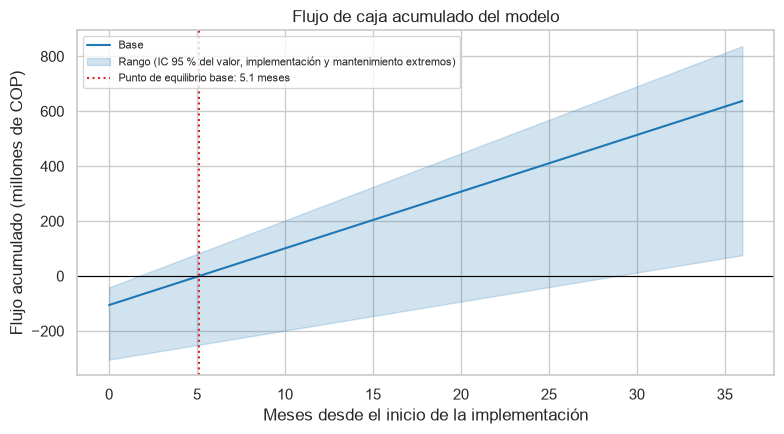

In [61]:
# 5.3 Punto de equilibrio: valor incremental anual frente a la implementación y el mantenimiento
G_INC = G_MODELO - G_ALT
MANT = MANT_ANUAL * IMPL_BASE
def meses_be(g_inc, impl_, mant_):
    neto = g_inc - mant_
    return impl_ / (neto / 12) if neto > 0 else np.inf
BE_BASE = meses_be(G_INC, IMPL_BASE, MANT)
ic_inc = ic(g_b) - G_ALT / 1e6    # IC del valor incremental, millones
BE_BAJO = meses_be(ic_inc[1] * 1e6, IMPL_BAJO, MANT_BAJO * IMPL_BAJO)    # lo más favorable
BE_ALTO = meses_be(ic_inc[0] * 1e6, IMPL_ALTO, MANT_ALTO * IMPL_ALTO)    # lo más desfavorable
print(f"Valor incremental anual: COP {G_INC / 1e6:,.1f} millones; mantenimiento: COP {MANT / 1e6:,.1f} millones; implementación: COP {IMPL_BASE / 1e6:,.1f} millones")
print(f"Flujo mensual neto: COP {(G_INC - MANT) / 12 / 1e6:,.2f} millones")
print(f"Punto de equilibrio (base): {BE_BASE:.1f} meses")
print(f"Rango: {BE_BAJO:.1f} meses (límite superior del IC, implementación baja, mantenimiento {MANT_BAJO:.0%}) a {BE_ALTO:.1f} meses "
      f"(límite inferior del IC, implementación alta, mantenimiento {MANT_ALTO:.0%})")
be_boot = np.array([meses_be(x * 1e6 - G_ALT, IMPL_BASE, MANT) for x in g_b])
print(f"Con la implementación base, en las 1.000 remuestras: mediana {np.median(be_boot):.1f} meses, percentiles 2,5 y 97,5: {np.percentile(be_boot, 2.5):.1f} y {np.percentile(be_boot, 97.5):.1f}")
n_min = (IMPL_BASE + MANT) / (G_INC / N_BANCO)
print(f"Banco mínimo que cubre implementación y un año de mantenimiento: {n_min:,.0f} clientes ({n_min / N_BANCO:.1%} del banco de 20.000), si el valor por cliente se mantiene")
print(f"Precisión mínima de un contactado adicional (3.7): {COSTO_CONTACTO / (P_EXITO * INGRESO * HORIZONTE):.3f}")

meses = np.arange(0, 37)
flujo = lambda g, im, ma: -im + meses * (g - ma) / 12
acum_base = flujo(G_INC, IMPL_BASE, MANT) / 1e6
acum_alto = flujo(ic_inc[0] * 1e6, IMPL_ALTO, MANT_ALTO * IMPL_ALTO) / 1e6
acum_bajo = flujo(ic_inc[1] * 1e6, IMPL_BAJO, MANT_BAJO * IMPL_BAJO) / 1e6
for m in (12, 36):
    print(f"Acumulado a {m} meses (millones COP): base {acum_base[m]:,.1f}, desfavorable {acum_alto[m]:,.1f}, favorable {acum_bajo[m]:,.1f}")
print(f"Mes 0 (inversión): base {acum_base[0]:,.1f}, desfavorable {acum_alto[0]:,.1f}, favorable {acum_bajo[0]:,.1f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(meses, acum_base, color="tab:blue", label="Base")
ax.fill_between(meses, acum_alto, acum_bajo, color="tab:blue", alpha=0.2, label="Rango (IC 95 % del valor, implementación y mantenimiento extremos)")
ax.axhline(0, color="black", lw=0.8)
ax.axvline(BE_BASE, color="tab:red", ls=":", label=f"Punto de equilibrio base: {BE_BASE:.1f} meses")
ax.set_xlabel("Meses desde el inicio de la implementación")
ax.set_ylabel("Flujo acumulado (millones de COP)")
ax.set_title("Flujo de caja acumulado del modelo")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

Con inversión de COP 105,6 millones y mantenimiento de COP 26,4 millones al año, el flujo neto es COP 20,64 millones al mes y la inversión se recupera en **5,1 meses** (rango de 1,7 a 28,8). Solo con la incertidumbre de muestreo (1.000 remuestras) queda entre 4,7 y 5,7 meses; el rango amplio viene de los costos supuestos, no de los datos.

La línea parte de −105,6 millones, cruza el cero en 5,1 meses y acumula 142,0 a los 12 meses y 637,3 a los 36. La banda va de −304,2 a −41,4 en el mes 0 y de 76,0 a 837,1 a los 36: incluso en el extremo desfavorable (28,8 meses) la inversión se recupera dentro de los 36.

Un banco necesita al menos 9.633 clientes (48,2 % del banco de 20.000) para cubrir la implementación y un año de mantenimiento. Un contacto adicional no pierde dinero si al menos 0,143 de los contactados se iban (3.7).

### 5.4 Qué pasa si cambian los supuestos

Una variable a la vez; el umbral se **re-optimiza en validación** y se evalúa en prueba. «Primer año neto» es el incremental menos mantenimiento e implementación; los meses son hasta el equilibrio (no se calculan para 2 y 3 años).

In [62]:
# 5.4 Sensibilidad: una variable a la vez. En cada escenario el umbral se re-optimiza en VALIDACIÓN y se evalúa en PRUEBA.
c_val = np.array([conteos(y_val, y_prob_val, u) for u in umbrales])
c_tst = np.array([conteos(y_test, y_prob_test, u) for u in umbrales])
tasas = lambda c: (c[:, 0] / (c[:, 0] + c[:, 2]), c[:, 1] / (c[:, 1] + c[:, 3]))
(t_v, f_v), (t_t, f_t) = tasas(c_val), tasas(c_tst)
i_neg = int(np.where(umbrales == umbral_negocio)[0][0])

def escenario(impl_=IMPL_BASE, mant_=MANT_ANUAL, **kw):
    i = int(np.argmax(beneficio(t_v, f_v, **kw)))                # umbral elegido en validación
    g = beneficio(t_t[i], f_t[i], **kw)                           # evaluado en prueba
    g_020 = beneficio(t_t[i_neg], f_t[i_neg], **kw)
    alt = max(beneficio(1, 1, **kw), 0)
    inc = g - alt
    h = kw.get("horizonte", HORIZONTE)
    return {"umbral": umbrales[i], "ganancia (M)": g / 1e6, "con umbral 0,20 (M)": g_020 / 1e6, "a todos (M)": alt / 1e6,
            "incremental (M)": inc / 1e6, "primer año neto (M)": (inc - mant_ * impl_ - impl_) / 1e6 if h == 1 else np.nan,
            "meses": meses_be(inc, impl_, mant_ * impl_) if h == 1 else np.nan}

prev_datos = float(pd.concat([y_val, y_test]).mean())
casos = [("Base", {}),
         ("Ingreso 500.000", dict(ingreso=500_000)), ("Ingreso 600.000", dict(ingreso=600_000)),
         ("Ingreso 800.000", dict(ingreso=800_000)), ("Ingreso 900.000", dict(ingreso=900_000)),
         ("Costo 5.000", dict(costo=5_000)), ("Costo 15.000", dict(costo=15_000)),
         (f"Costo investigado {COSTO_INV:,.0f}", dict(costo=COSTO_INV)),
         ("Costo 50.000", dict(costo=50_000)), ("Costo 100.000", dict(costo=100_000)),
         ("Éxito 10 %", dict(p=0.10)), ("Éxito 20 %", dict(p=0.20)), ("Éxito 40 %", dict(p=0.40)),
         ("Abandono 10 %", dict(prev=0.10)), (f"Abandono {prev_datos:.2%} (datos)", dict(prev=prev_datos)),
         ("Horizonte 2 años", dict(horizonte=2)), ("Horizonte 3 años", dict(horizonte=3)),
         (f"Implementación {IMPL_BAJO / 1e6:,.1f} M", dict(impl_=IMPL_BAJO)), (f"Implementación {IMPL_ALTO / 1e6:,.1f} M", dict(impl_=IMPL_ALTO)),
         ("Mantenimiento 10 %", dict(mant_=MANT_BAJO)), ("Mantenimiento 40 %", dict(mant_=MANT_ALTO))]
tabla_sens = pd.DataFrame({n: escenario(**kw) for n, kw in casos}).T
pd.options.display.width = 200
print(tabla_sens.round({"umbral": 2, "ganancia (M)": 1, "con umbral 0,20 (M)": 1, "a todos (M)": 1, "incremental (M)": 1, "primer año neto (M)": 1, "meses": 1}).to_string())
print(f"\nControl: el escenario base reproduce 3.7 (umbral {tabla_sens.loc['Base', 'umbral']}, ganancia {tabla_sens.loc['Base', 'ganancia (M)']:,.1f} frente a {g_n:,.1f})")

                          umbral  ganancia (M)  con umbral 0,20 (M)  a todos (M)  incremental (M)  primer año neto (M)  meses
Base                        0.20         304.0                304.0         30.0            274.0                142.0    5.1
Ingreso 500.000             0.27         191.1                170.0          0.0            191.1                 59.1    7.7
Ingreso 600.000             0.27         252.8                237.0          0.0            252.8                120.8    5.6
Ingreso 800.000             0.15         376.3                371.1        120.0            256.3                124.3    5.5
Ingreso 900.000             0.15         449.3                438.1        210.0            239.3                107.3    6.0
Costo 5.000                 0.04         537.7                441.5        530.0              7.7               -124.3    inf
Costo 15.000                0.08         417.5                386.5        330.0             87.5                -44.5

**Tabla:**

| Escenario | Umbral óptimo | Ganancia (millones) | Incremental | Primer año neto | Meses |
|---|---|---|---|---|---|
| Base | 0,20 | 304,0 | 274,0 | 142,0 | 5,1 |
| Ingreso 500.000 | 0,27 | 191,1 | 191,1 | 59,1 | 7,7 |
| Ingreso 900.000 | 0,15 | 449,3 | 239,3 | 107,3 | 6,0 |
| Costo 5.000 | 0,04 | 537,7 | 7,7 | −124,3 | no se recupera |
| Costo 15.000 | 0,08 | 417,5 | 87,5 | −44,5 | 20,7 |
| Costo investigado (32.791) | 0,27 | 303,5 | 303,5 | 171,5 | 4,6 |
| Costo 100.000 | 0,50 | 92,9 | 92,9 | −39,1 | 19,1 |
| Éxito 10 % | 0,50 | 37,3 | 37,3 | −94,7 | 116,2 |
| Éxito 20 % | 0,27 | 170,5 | 170,5 | 38,5 | 8,8 |
| Éxito 40 % | 0,15 | 473,6 | 233,6 | 101,6 | 6,1 |
| Abandono 10 % | 0,27 | 187,8 | 187,8 | 55,8 | 7,9 |
| Abandono 20,35 % (datos) | 0,15 | 468,0 | 213,3 | 81,3 | 6,8 |

- **Umbral óptimo:** sube cuando el contacto es caro frente a lo que deja un desertor y baja cuando es barato: 0,04 con costo de 5.000, 0,08 con 15.000, 0,20 con 30.000 y 0,50 con 100.000. También sube con éxito o ingreso bajos (0,50 con éxito de 10 %; 0,27 con ingreso de 500.000).
- **Cuándo sobra el modelo:** con costo de 5.000 contactar a todos gana 530,0 y el modelo suma 7,7, menos que su mantenimiento (26,4). Con costo de 15.000 suma 87,5 y tarda 20,7 meses en pagarse.
- **Éxito:** con 10 % el primer año neto es −94,7 y el equilibrio tardaría 116,2 meses; no está medido y pesa más que el ingreso.
- **Horizonte:** con 2 y 3 años el incremental baja (175,0 y 114,5) porque contactar a todos sube. Sin descuento financiero, el horizonte largo es optimista.
- **Implementación:** con 41,4 millones el equilibrio es de 1,9 meses y con 304,2, de 18,4; el mantenimiento cambia poco (4,8 a 5,5).

Valor neto del primer año, caso base: COP 142.0 millones
                           variable  valor bajo  valor alto  amplitud
  Implementación (41.4 M / 304.2 M)       222.3      -106.2     328.5
  Éxito de la campaña (10 % / 40 %)       -94.7       101.6     196.3
Costo de contacto (5.000 / 100.000)      -124.3       -39.1      85.2
        Ingreso (500.000 / 900.000)        59.1       107.3      48.2
        Mantenimiento (10 % / 40 %)       157.9       126.2      31.7
           Abandono (10 % / 20.35%)        55.8        81.3      25.5


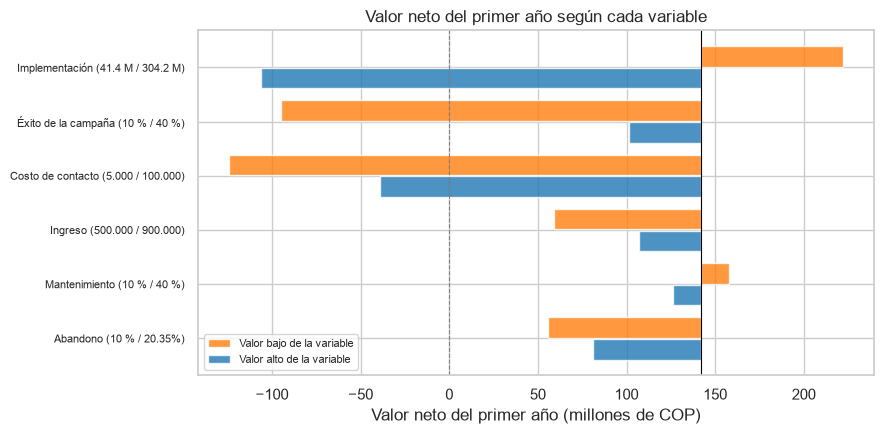

In [63]:
# Tornado: valor neto del primer año (incremental - mantenimiento - implementación) con cada variable en sus extremos
base_neto = tabla_sens.loc["Base", "primer año neto (M)"]
# (etiqueta, escenario con el valor bajo de la variable, escenario con el valor alto)
pares = [("Ingreso (500.000 / 900.000)", "Ingreso 500.000", "Ingreso 900.000"),
         ("Éxito de la campaña (10 % / 40 %)", "Éxito 10 %", "Éxito 40 %"),
         (f"Abandono (10 % / {prev_datos:.2%})", "Abandono 10 %", f"Abandono {prev_datos:.2%} (datos)"),
         ("Costo de contacto (5.000 / 100.000)", "Costo 5.000", "Costo 100.000"),
         (f"Implementación ({IMPL_BAJO / 1e6:,.1f} M / {IMPL_ALTO / 1e6:,.1f} M)", f"Implementación {IMPL_BAJO / 1e6:,.1f} M", f"Implementación {IMPL_ALTO / 1e6:,.1f} M"),
         ("Mantenimiento (10 % / 40 %)", "Mantenimiento 10 %", "Mantenimiento 40 %")]
torn = pd.DataFrame([{"variable": e, "valor bajo": tabla_sens.loc[b, "primer año neto (M)"], "valor alto": tabla_sens.loc[a, "primer año neto (M)"]} for e, b, a in pares])
torn["amplitud"] = (torn["valor alto"] - torn["valor bajo"]).abs()
torn = torn.sort_values("amplitud")
print(f"Valor neto del primer año, caso base: COP {base_neto:,.1f} millones")
print(torn.sort_values("amplitud", ascending=False).round(1).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4.5))
for k, (_, r) in enumerate(torn.iterrows()):
    ax.barh(k + 0.2, r["valor bajo"] - base_neto, height=0.38, left=base_neto, color="tab:orange", alpha=0.8, label="Valor bajo de la variable" if k == 0 else None)
    ax.barh(k - 0.2, r["valor alto"] - base_neto, height=0.38, left=base_neto, color="tab:blue", alpha=0.8, label="Valor alto de la variable" if k == 0 else None)
ax.set_yticks(range(len(torn))); ax.set_yticklabels(torn["variable"], fontsize=8)
ax.axvline(base_neto, color="black", lw=0.8); ax.axvline(0, color="gray", ls="--", lw=0.8)
ax.set_xlabel("Valor neto del primer año (millones de COP)")
ax.set_title("Valor neto del primer año según cada variable")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Tornado.** El caso base deja 142,0 millones en el primer año. Pesa más la implementación (de 222,3 a −106,2), luego el éxito (de −94,7 a 101,6) y el costo de contacto (−124,3 con 5.000, −39,1 con 100.000). Ingreso (59,1 a 107,3), abandono (55,8 a 81,3) y mantenimiento (157,9 a 126,2) mueven menos.

costo   5,000: umbral óptimo 0.04, incremental 7.7 M
costo  10,000: umbral óptimo 0.05, incremental 38.2 M
costo  20,000: umbral óptimo 0.15, incremental 142.5 M
costo  25,000: umbral óptimo 0.15, incremental 207.9 M
costo  28,000: umbral óptimo 0.20, incremental 245.0 M
costo  30,000: umbral óptimo 0.20, incremental 274.0 M
costo  31,000: umbral óptimo 0.27, incremental 300.6 M
costo  32,000: umbral óptimo 0.27, incremental 306.6 M
costo  33,000: umbral óptimo 0.27, incremental 302.7 M
costo  40,000: umbral óptimo 0.27, incremental 275.3 M
costo  60,000: umbral óptimo 0.28, incremental 197.1 M
costo 100,000: umbral óptimo 0.50, incremental 92.9 M
Mayor valor incremental: COP 306.6 M con costo de 32,000 COP (umbral óptimo 0.27)
El modelo cubre su mantenimiento anual (COP 26.4 M) con costos de contacto de 9,000 a 153,000 COP por contactado
La campaña con modelo deja ganancia positiva hasta un costo de 209,000 COP por contactado
Umbral óptimo de 0,25 o más desde un costo de 31,000 COP


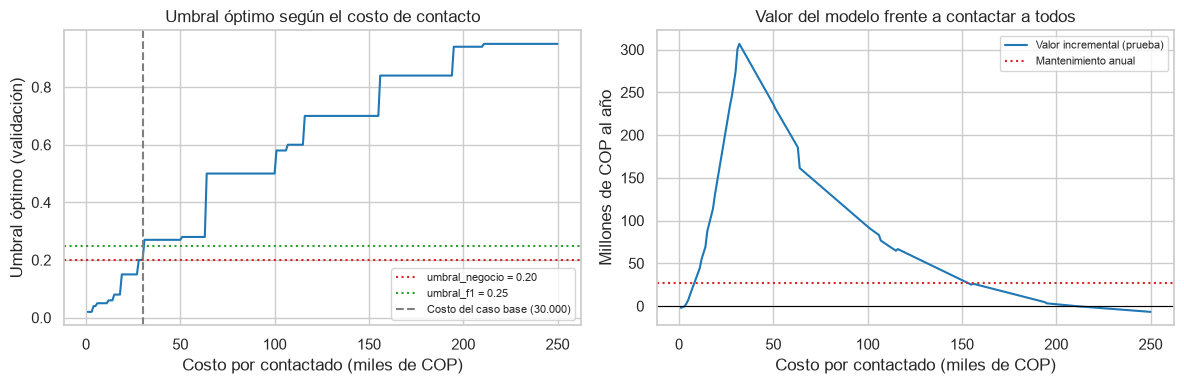

In [64]:
# Umbral óptimo y valor incremental según el costo de contacto (umbral re-optimizado en validación en cada punto)
costos = np.arange(1_000, 250_001, 1_000)
res_c = pd.DataFrame([escenario(costo=c) for c in costos], index=costos)
for c in (5_000, 10_000, 20_000, 25_000, 28_000, 30_000, 31_000, 32_000, round(COSTO_INV, -3), 40_000, 60_000, 100_000):
    r = res_c.loc[int(c)]
    print(f"costo {int(c):>7,}: umbral óptimo {r['umbral']:.2f}, incremental {r['incremental (M)']:,.1f} M")
mx = res_c["incremental (M)"].idxmax()
print(f"Mayor valor incremental: COP {res_c.loc[mx, 'incremental (M)']:,.1f} M con costo de {mx:,} COP (umbral óptimo {res_c.loc[mx, 'umbral']:.2f})")
rentable = res_c.index[res_c["incremental (M)"] * 1e6 > MANT]
print(f"El modelo cubre su mantenimiento anual (COP {MANT / 1e6:,.1f} M) con costos de contacto de {rentable.min():,} a {rentable.max():,} COP por contactado")
campana = res_c.index[res_c["ganancia (M)"] > 0]
print(f"La campaña con modelo deja ganancia positiva hasta un costo de {campana.max():,} COP por contactado")
u25 = res_c.index[res_c["umbral"] >= 0.25]
print(f"Umbral óptimo de 0,25 o más desde un costo de {u25.min():,} COP" if len(u25) else "El umbral óptimo no llega a 0,25 en la rejilla")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(costos / 1e3, res_c["umbral"], color="tab:blue")
ax[0].axhline(umbral_negocio, color="tab:red", ls=":", label=f"umbral_negocio = {umbral_negocio:.2f}")
ax[0].axhline(umbral_f1, color="tab:green", ls=":", label=f"umbral_f1 = {umbral_f1:.2f}")
ax[0].axvline(COSTO_CONTACTO / 1e3, color="gray", ls="--", label="Costo del caso base (30.000)")
ax[0].set_xlabel("Costo por contactado (miles de COP)"); ax[0].set_ylabel("Umbral óptimo (validación)")
ax[0].set_title("Umbral óptimo según el costo de contacto"); ax[0].legend(fontsize=8)
ax[1].plot(costos / 1e3, res_c["incremental (M)"], color="tab:blue", label="Valor incremental (prueba)")
ax[1].axhline(MANT / 1e6, color="tab:red", ls=":", label="Mantenimiento anual")
ax[1].axhline(0, color="black", lw=0.8)
ax[1].set_xlabel("Costo por contactado (miles de COP)"); ax[1].set_ylabel("Millones de COP al año")
ax[1].set_title("Valor del modelo frente a contactar a todos"); ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Costo de contacto.** A la izquierda, el umbral óptimo sube en escalones: 0,04 con costo de 5.000, 0,15 con 20.000 y 25.000, 0,20 con 28.000 y 30.000 (caso base), 0,27 desde 31.000 y 0,50 con 100.000. A la derecha, el incremental llega a su máximo, COP 306,6 millones, con costo de 32.000; con 5.000 es 7,7 y con 60.000, 197,1. Supera el mantenimiento (26,4) solo con costos de 9.000 a 153.000, y la campaña deja ganancia hasta 209.000 por contactado.

**¿Qué umbral usar?** La curva es plana (de 0,14 a 0,29 se obtiene al menos 95 % del máximo, 3.7) y con 31.000 el óptimo ya es 0,27; por eso conviene operar entre 0,20 y 0,27 y fijarlo con el costo real medido en un piloto. **El modelo deja de ser necesario** cuando contactar a todos rinde casi lo mismo: con costo de 5.000 el incremental es 7,7 millones.

### 5.5 Limitaciones

Las dos celdas siguientes imprimen las cifras que respaldan las limitaciones: tamaños, prevalencia y desempeño por país, y la equidad por subgrupo.

In [65]:
# 5.5 Datos para las limitaciones
n_tr, n_va, n_te = len(y_train), len(y_val), len(y_test)
print(f"Clientes: entrenamiento {n_tr:,}, validación {n_va:,}, prueba {n_te:,}; desertores en prueba: {int(y_test.sum())}")
print(f"Abandono en los datos: {prev_datos:.2%} (entrenamiento {y_train.mean():.2%}); referencia del banco: {PREVALENCIA_BANCO:.0%}")
print(f"Países en los datos: {df['country'].value_counts().to_dict()}")
print(f"Probabilidad media del modelo: validación {np.mean(y_prob_val):.3f} (tasa real {y_val.mean():.3f}), prueba {np.mean(y_prob_test):.3f} (tasa real {y_test.mean():.3f})")
tv, fv = t_v[i_neg], f_v[i_neg]
print(f"Estabilidad de las tasas con umbral {umbral_negocio}: recall {tv:.3f} en validación y {TPR_T:.3f} en prueba; falsos positivos {fv:.3f} y {FPR_T:.3f}")
por_pais = df.loc[y_val.index].assign(y=y_val.values, c=(y_prob_val >= umbral_negocio)).groupby("country").apply(
    lambda g: pd.Series({"clientes": len(g), "recall": (g.c & (g.y == 1)).sum() / (g.y == 1).sum(), "falsos positivos": (g.c & (g.y == 0)).sum() / (g.y == 0).sum()}), include_groups=False)
print("Validación por país (umbral_negocio):")
print(por_pais.round(3).to_string())

Clientes: entrenamiento 6,000, validación 2,000, prueba 2,000; desertores en prueba: 407
Abandono en los datos: 20.35% (entrenamiento 20.38%); referencia del banco: 15%
Países en los datos: {'France': 5014, 'Germany': 2509, 'Spain': 2477}
Probabilidad media del modelo: validación 0.196 (tasa real 0.203), prueba 0.198 (tasa real 0.203)
Estabilidad de las tasas con umbral 0.2: recall 0.720 en validación y 0.744 en prueba; falsos positivos 0.191 y 0.192
Validación por país (umbral_negocio):
         clientes  recall  falsos positivos
country                                    
France     1034.0   0.650             0.132
Germany     475.0   0.852             0.377
Spain       491.0   0.598             0.176


In [66]:
# Equidad por subgrupo en PRUEBA con umbral_negocio (el umbral viene de validación). IC 95 % bootstrap dentro de cada subgrupo (1.000, semilla 42).
rng_q = np.random.default_rng(42)
contactado = np.asarray(y_prob_test) >= umbral_negocio
y_q = y_test.to_numpy()
tramo_edad = pd.cut(X_test["age"], [0, 40, 50, 60, np.inf], right=False, labels=["<40 (18-39)", "40-49", "50-59", "60+"])
subgrupos = [("Todos", "todos", np.ones(len(y_q), dtype=bool)),
             ("género", "Mujer", (X_test["gender_Male"] == 0).to_numpy()), ("género", "Hombre", (X_test["gender_Male"] == 1).to_numpy()),
             ("país", "Francia", ((X_test["country_Germany"] == 0) & (X_test["country_Spain"] == 0)).to_numpy()),
             ("país", "Alemania", (X_test["country_Germany"] == 1).to_numpy()), ("país", "España", (X_test["country_Spain"] == 1).to_numpy())]
subgrupos += [("edad", str(t), (tramo_edad == t).to_numpy()) for t in tramo_edad.cat.categories]

filas_q = []
for variable, grupo, m in subgrupos:
    yg, cg = y_q[m], contactado[m]
    idx = rng_q.integers(0, len(yg), (1000, len(yg)))
    pct = cg[idx].mean(axis=1) * 100
    rec = (cg[idx] & (yg[idx] == 1)).sum(axis=1) / (yg[idx] == 1).sum(axis=1)
    filas_q.append({"variable": variable, "grupo": grupo, "n": int(m.sum()), "churn real %": yg.mean() * 100,
                    "contactado %": cg.mean() * 100, "IC contactado": f"[{np.percentile(pct, 2.5):.1f}; {np.percentile(pct, 97.5):.1f}]",
                    "recall": (cg & (yg == 1)).sum() / (yg == 1).sum(), "IC recall": f"[{np.percentile(rec, 2.5):.3f}; {np.percentile(rec, 97.5):.3f}]",
                    "precisión": (cg & (yg == 1)).sum() / cg.sum()})
equidad = pd.DataFrame(filas_q)
print(f"Prueba, umbral_negocio = {umbral_negocio}; tramos de edad cerrados a la izquierda (40-49 incluye 40 y excluye 50)")
print(equidad.round({"churn real %": 1, "contactado %": 1, "recall": 3, "precisión": 3}).to_string(index=False))

Prueba, umbral_negocio = 0.2; tramos de edad cerrados a la izquierda (40-49 incluye 40 y excluye 50)
variable       grupo    n  churn real %  contactado % IC contactado  recall      IC recall  precisión
   Todos       todos 2000          20.3          30.4  [28.5; 32.6]   0.744 [0.700; 0.786]      0.498
  género       Mujer  905          24.8          37.0  [33.9; 40.2]   0.772 [0.714; 0.825]      0.516
  género      Hombre 1095          16.7          25.0  [22.6; 27.6]   0.710 [0.640; 0.775]      0.474
    país     Francia 1008          16.5          22.9  [20.5; 25.5]   0.681 [0.605; 0.749]      0.489
    país    Alemania  508          33.3          51.2  [47.0; 55.5]   0.822 [0.767; 0.877]      0.535
    país      España  484          14.9          24.4  [20.5; 28.1]   0.708 [0.600; 0.808]      0.432
    edad <40 (18-39) 1247          10.3          13.1  [11.2; 15.0]   0.442 [0.352; 0.532]      0.350
    edad       40-49  508          31.3          54.3  [50.0; 58.7]   0.855 [0.798;

El modelo contacta más a los grupos con más churn real: 37,0 % de las mujeres (churn 24,8 %) frente a 25,0 % de los hombres (16,7 %), y 51,2 % en Alemania (33,3 %) frente a 22,9 % en Francia (16,5 %) y 24,4 % en España (14,9 %). La precisión entre géneros y países va de 0,432 a 0,535, sin IC calculado; por edad varía más (0,350 en menores de 40 y 0,655 entre 50 y 59). El riesgo es de uso: género y país entrarían en una decisión comercial. Como siguiente iteración se propone evaluar un modelo sin `gender`; no se hace en este taller.

**Del modelo**
- **Población:** 10.000 clientes de Francia (5.014), Alemania (2.509) y España (2.477), no de un banco colombiano. Con el umbral 0,2, en validación el recall es 0,650 en Francia, 0,852 en Alemania y 0,598 en España, y los falsos positivos 0,132, 0,377 y 0,176: el desempeño cambia entre poblaciones.
- **Prevalencia:** los datos tienen 20,35 % de abandono y el banco 15 %. El ajuste supone recall y falsos positivos constantes; entre validación y prueba son parecidos (recall 0,720 y 0,744; falsos positivos 0,191 y 0,192), pero eso no prueba que se mantengan con otra prevalencia o país.
- **Muestra pequeña:** la prueba tiene 2.000 clientes y 407 desertores; el IC del incremental (de 248,4 a 297,0) refleja solo ese muestreo.
- **Sin campaña previa ni uplift:** el modelo predice quién se iría, no quién respondería a la oferta; el 30 % de éxito es del enunciado y no se midió.
- **Calibración:** solo se comparó la media (0,196 predicha y 0,203 real en validación).
- **Equidad:** se revisó por género, país y edad en la tabla de arriba (prueba): el modelo contacta más a los grupos con más churn real; no se evaluó un modelo sin `gender`.
- **Momento de medición:** en producción, el desempeño depende de que `active_member` y `products_number` se observen antes de la decisión de irse; conviene confirmarlo con el banco.

**Del cálculo de valor**
- **Ingreso no es margen:** el valor usa ingreso, sin margen ni descuento, con horizonte de 1 año y clientes retenidos estables.
- **Costos incompletos:** no se modelan la canibalización ni el desgaste por contactos repetidos.
- **Fuentes débiles:** el abandono de 15 % viene de prensa de otro país; llamada y salarios, de blogs; el resto son supuestos.
- **Siguiente paso:** un piloto con grupo de control para medir el éxito y el costo reales antes de fijar el umbral y comprometer la inversión.

## 6. Insights y recomendación

**Resumen.** Se construyó un modelo (Gradient Boosting) que ordena a los clientes según su probabilidad de abandono. En datos de prueba que no se usaron para elegirlo, tiene un AUC de 0,864 (IC 95 % de 0,843 a 0,882). Bajo los supuestos del enunciado, una campaña de retención dirigida con él deja una ganancia esperada de COP 304,0 millones al año (IC 95 % de 278,4 a 327,0), es decir, COP 274,0 millones más que contactar a todos los clientes.

**Hallazgos**

- **Quién abandona** (tasas de abandono en entrenamiento). El abandono se asocia con tener 1 producto (0,279) o 3 (0,832) frente a 2 (0,070); con tener 50 a 59 años (0,548, frente a 0,079 en menores de 30); con ser inactivo (0,271 frente a 0,142); con estar en Alemania (0,317 frente a 0,165) y con ser mujer (0,249 frente a 0,165). El saldo (`balance`) se mezcla con el país.
- **Qué tan bien ordena.** Con el umbral 0,20, el modelo contacta a 609 clientes en la prueba y detecta 303 de los 407 que se iban (recall 0,744). La mitad de los contactados se iba (precisión 0,498); contactar a todos solo acierta en 0,204.
- **Cuánto vale.** La inversión (COP 105,6 millones) se recupera en 5,1 meses, con un rango de 1,7 a 28,8 según costos de implementación y mantenimiento.

**Qué tan seguros estamos**

- **Éxito de la campaña.** Es el supuesto que más pesa y nadie lo ha medido. Con 30 % el equilibrio llega en 5,1 meses; con 20 %, en 8,8; con 10 %, en 116,2.
- **Umbral.** Entre 0,20 y 0,27, según el costo de contacto (COP 30.000 es un supuesto; con 31.000 el óptimo ya es 0,27). El modelo aporta más que su mantenimiento solo con costos de COP 9.000 a 153.000 por contactado.
- **Momento de medición.** `active_member` se mide al mismo tiempo que el abandono y puede reflejarlo en parte; se lee como síntoma, no como palanca.
- **Equidad.** El modelo contacta al 37,0 % de las mujeres y al 25,0 % de los hombres, y al 51,2 % en Alemania frente a 22,9 % en Francia; sigue en parte el abandono real de cada grupo, pero es un riesgo de uso.
- **Datos.** Son de Francia, Alemania y España, no de un banco colombiano, y la referencia de abandono de 15 % viene de prensa de otro país.

**Recomendación**

1. **Lanzar un piloto con grupo de control** para medir el éxito real y el costo por contacto antes de comprometer la inversión.
2. **Operar con el umbral 0,20** y subirlo hasta 0,27 si el costo medido supera los COP 30.000.
3. **Seguir solo si el éxito medido se acerca a 20 % o más** (equilibrio en 8,8 meses). Con cerca de 10 % no se recupera (116,2 meses).
4. **Confirmar con el banco** cuándo se registran `active_member` y `products_number`: deben conocerse antes de que el cliente decida irse.
5. **Revisar la equidad con cumplimiento** y probar en la siguiente iteración un modelo sin `gender`.

## 7. Uso de IA

Usamos **Claude Code** (CLI de Anthropic) como asistente. El modelo principal, que coordinaba el trabajo, fue **Claude Opus 5.5**. Delegó tareas a subagentes de **Claude Sonnet 5.5** (casi todas) y **Claude Haiku 5.5** (al menos una revisión inicial).

**Para qué se usó**
- Revisar cada punto del enunciado frente a la guía de calificación y sugerir mejoras.
- Escribir código y texto de las celdas, siempre en copias del notebook.
- Explicarnos las técnicas de interpretabilidad de las secciones 4 y 5 con referencias academicas.

**Cómo lo controlamos**
- El equipo decidió qué hacer y qué conservar: el umbral por ganancia, el manejo del desbalance, las técnicas vistas en clase, mantener `active_member` y `products_number`, entre otras.
- Otros agentes auditaron el trabajo, y antes de integrar se recalcularon las cifras clave.
- El equipo revisó todo el contenido y hizo los commits.

**Porcentaje de ayuda.** Son estimaciones del equipo, no mediciones. 

| Sección | Ayuda de la IA (aprox.) | Por qué |
|---|---|---|
| 1. Datos | 40 % | Borrador propio; la IA ayudó con cifras impresas, pruebas y redacción |
| 2. Modelos | 45 % | Borrador propio; la IA ayudó con búsqueda ampliada, desbalance y logística no lineal |
| 3. Resultados | 50 % | Borrador propio; la IA ayudó con el umbral de negocio, intervalos y textos |
| 4. Interpretación | 70 % | Código y texto escritos con la IA; el equipo eligió las técnicas |
| 5. Negocio | 70 % | Código y texto escritos con la IA; el equipo revisó supuestos y fuentes |
| 6. Insights | 65 % | Redacción con la IA a partir de los resultados; el equipo revisó |
| **Total** | **~55 %** | Promedio aproximado |

Los prompts que enviamos, en orden y con fecha, están en [`prompts_IA.md`](prompts_IA.md). No incluyen el trabajo previo a Claude Code ni otros usos de IA fuera de esa herramienta.